# Home Credit: out-of-time default model ladder (LR, WoE scorecard, random forest, XGBoost, LightGBM)

**Question.** Can gradient boosting beat a logistic regression and a regulatory-style WoE scorecard on applications
that arrive *after* the model was built, and does the answer survive a bootstrap, a recalibration and a simple
credit-policy cut-off?

**Data.** Kaggle competition `home-credit-credit-risk-model-stability` (real Home Credit applications, multi-table
parquet). One row per `case_id`; prediction time = `date_decision`; target = default flag observed later.

## Design in five lines

1. **Time split by `WEEK_NUM`** (no random split): ~70% / 15% / 15% of consecutive weeks = TRAIN / VALID / OOT. No `case_id` appears twice.
2. **Point-in-time features.** Every history record dated after `date_decision` is dropped before aggregation (mean/max/min/std, counts, recency).
3. **Fit on TRAIN rows only**: column screening, imputation, scaling, WoE binning, encoders. VALID is used for tuning, calibration and the cut-off; OOT is scored only after the champion, calibrator and cut-off are frozen and written to `artifacts/champion.json`.
4. **Same features, same split for every model**: dummy, L2 logistic regression, WoE scorecard (monotone bins, wrong-sign variables dropped until all signs are consistent), random forest, XGBoost (main advanced model, plus a monotone-constrained variant), LightGBM (check).
5. **Metrics on VALID and OOT for every model**: AUC, Gini, KS, PR-AUC, Brier, weekly Gini and the competition stability metric
   `mean(weekly Gini) + 88*min(0, slope) - 0.5*std(residuals)`.

Credit-policy numbers are observed OOT outcomes (approval rate, bad rate, swap sets, risk grades). The expected-loss table is illustrative: LGD is an assumption (0.45, Basel foundation-IRB senior unsecured) and EAD is the application credit amount.
All numbers written to `artifacts/` are the only source for the README.


In [1]:
import importlib, subprocess, sys

def _ensure(pkg, spec=None, module=None):
    module = module or pkg
    try:
        importlib.import_module(module)
        return "present"
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", spec or pkg], check=True)
        importlib.import_module(module)
        return "installed"

print("optbinning:", _ensure("optbinning", "optbinning==1.0.0"))
print("polars:", _ensure("polars"))
print("statsmodels:", _ensure("statsmodels"))
print("[end of code cell 1]")

optbinning: installed
polars: present
statsmodels: present
[end of code cell 1]


0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-tools 1.85.1 requires protobuf<8.0.0,>=7.35.1, but you have protobuf 6.33.6 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. 

In [2]:
import json, math, os, platform, sys, time, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

warnings.simplefilter("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 90)

ART = Path("artifacts")
(ART / "figures").mkdir(parents=True, exist_ok=True)
(ART / "models").mkdir(parents=True, exist_ok=True)
T_START = time.time()
print("cwd:", Path.cwd(), "| cpu count:", os.cpu_count())
print("[end of code cell 2]")

cwd: /kaggle/working | cpu count: 4
[end of code cell 2]


## Project modules

The tested `src/` package inlined verbatim (cross-module imports stripped).

In [3]:
"""Configuration for the Home Credit out-of-time PD / stability project.

Everything in this module is a *decision*: split fractions, screening
thresholds, scorecard scaling and the cost model.  Empirical numbers never
live here - they are written to ``artifacts/*.json`` by the pipeline.

The point of keeping them in one typed module is auditability: a reviewer can
read this file and see every knob that could move the headline number, and the
notebook embeds the same values in its markdown so nothing is hidden in a cell.
"""

from __future__ import annotations

import os
from pathlib import Path

# --------------------------------------------------------------------------
# Identity of the modelling problem
# --------------------------------------------------------------------------
TARGET = "target"
ID_COL = "case_id"
DATE_COL = "date_decision"
WEEK_COL = "WEEK_NUM"
MONTH_COL = "MONTH"

SEED = 42

#: Rows kept per fold for the expanding-window CV fits.  The final models are
#: refit on the *full* training window; the cap exists because the whole
#: roster (7 model families x 4 folds) has to fit in one CPU kernel session.
CV_FOLDS = 4
CV_ROW_CAP = 300_000

#: Fraction of *weeks* (not rows) allocated to each split.
SPLIT_FRACTIONS = (0.70, 0.15, 0.15)

# --------------------------------------------------------------------------
# Data discovery
# --------------------------------------------------------------------------
DATA_SUBDIR = "parquet_files"

#: Candidate roots, checked in order.  ``/kaggle/input/...`` first so the same
#: notebook works as a Kaggle kernel with either the competition source or the
#: dataset mirror attached.
DATA_ROOT_CANDIDATES = (
    "/kaggle/input/home-credit-credit-risk-model-stability/parquet_files",
    "/kaggle/input/usuarioml/home-credit-credit-risk-model-stability/parquet_files",
    "data/raw/parquet_files",
    "data/raw",
)

#: Tables that are aggregated and joined onto the application row.
#: ``date_cols`` are discovered from the schema at runtime (suffix ``D``);
#: ``month_pairs`` are the (year, month) column pairs used when a table has no
#: real date column, as documented in the competition data description.
TABLE_SPECS: tuple[dict, ...] = (
    {"name": "static_0_0", "depth": 0, "prefix": "train_static_0_0"},
    {"name": "static_0_1", "depth": 0, "prefix": "train_static_0_1"},
    {"name": "static_cb_0", "depth": 0, "prefix": "train_static_cb_0"},
    {"name": "person_1", "depth": 1, "prefix": "train_person_1"},
    {"name": "applprev_1_0", "depth": 1, "prefix": "train_applprev_1_0"},
    {"name": "applprev_1_1", "depth": 1, "prefix": "train_applprev_1_1"},
    {"name": "credit_bureau_a_1_0", "depth": 1, "prefix": "train_credit_bureau_a_1_0"},
    {"name": "credit_bureau_a_1_1", "depth": 1, "prefix": "train_credit_bureau_a_1_1"},
    {"name": "credit_bureau_b_1", "depth": 1, "prefix": "train_credit_bureau_b_1"},
    {"name": "deposit_1", "depth": 1, "prefix": "train_deposit_1"},
    {"name": "other_1", "depth": 1, "prefix": "train_other_1"},
    {"name": "tax_registry_a_1", "depth": 1, "prefix": "train_tax_registry_a_1"},
    {"name": "tax_registry_c_1", "depth": 1, "prefix": "train_tax_registry_c_1"},
    {"name": "applprev_2", "depth": 2, "prefix": "train_applprev_2"},
    {"name": "person_2", "depth": 2, "prefix": "train_person_2"},
    {"name": "credit_bureau_a_2_0", "depth": 2, "prefix": "train_credit_bureau_a_2_0"},
    {"name": "credit_bureau_a_2_1", "depth": 2, "prefix": "train_credit_bureau_a_2_1"},
    {"name": "credit_bureau_a_2_2", "depth": 2, "prefix": "train_credit_bureau_a_2_2"},
    {"name": "credit_bureau_b_2", "depth": 2, "prefix": "train_credit_bureau_b_2"},
)

#: (year column, month column) pairs, verified against the data description.
MONTH_PAIRS: tuple[tuple[str, str], ...] = (
    ("pmts_year_1139T", "pmts_month_158T"),   # active contract payments
    ("pmts_year_507T", "pmts_month_706T"),    # closed contract payments
)

# --------------------------------------------------------------------------
# Feature construction
# --------------------------------------------------------------------------
#: Per-table caps on the number of raw columns carried into aggregations.
#: Columns are ordered by coverage (non-null share) on a sample, ties broken
#: alphabetically, so the selection is unsupervised and reproducible.
MAX_NUMERIC_COLS_PER_TABLE = 16
MAX_CATEGORICAL_COLS_PER_TABLE = 6
#: Numeric aggregations.  ``last`` = value at the most recent dated record.
NUM_AGGS = ("mean", "max", "min", "std")
CAT_AGGS = ("nunique",)

#: Hard cap on the model matrix width after the screening step.
MAX_TREE_FEATURES = 450
MAX_LINEAR_FEATURES = 120
MAX_WOE_FEATURES = 70

MIN_COVERAGE = 0.30           # column kept only if non-null in >= 30% of rows
MAX_MISSING_FOR_MODEL = 0.98  # feature dropped if missing in > 98% of train
UNIVARIATE_AUC_SCREEN = 0.80  # leakage gate: single feature AUC above this is quarantined
IV_MIN = 0.02                 # WoE scorecard: drop features below this IV
VIF_MAX = 5.0                 # iterative VIF pruning threshold
#: saga tolerance. 1e-3 (not sklearn's 1e-4 default) is a documented compute
#: decision: on a standardised design the objective is smooth, and at 1e-4 a
#: single L2 fit needs ~1200 epochs at 34k rows, which would put the whole grid
#: outside one kernel session. Convergence is still *required* (n_iter <
#: max_iter) and reported, so a non-converged fit is excluded, never shipped.
LR_TOL = 1e-3
MIN_BIN_SIZE = 0.02
MAX_N_BINS = 8
WOE_FIT_SAMPLE = 250_000      # rows used to fit the binning (train rows only)

#: Scorecard scaling: score = OFFSET - FACTOR * logit(PD).
PDO = 20.0
BASE_SCORE = 600.0
BASE_ODDS = 20.0  # 20:1 good:bad at BASE_SCORE

# --------------------------------------------------------------------------
# Calibration / monitoring
# --------------------------------------------------------------------------
CALIBRATION_METHOD = "isotonic"   # fitted on VALID rows only
PSI_BINS = 10
PSI_WATCH = 0.10
PSI_ALERT = 0.25
GINI_DROP_TRIGGER = 0.05          # monitoring: weekly gini drop that triggers review
MONITOR_MIN_CASES_PER_WEEK = 150  # below this a weekly gini is too noisy to act on

#: Official competition stability metric (Kaggle evaluation page):
#:   metric = mean(weekly gini) + 88 * min(0, slope) - 0.5 * std(residuals)
SLOPE_PENALTY = 88.0
VOLATILITY_PENALTY = 0.5

# --------------------------------------------------------------------------
# Expected-loss assumptions (illustrative; the data has no exposure or LGD)
# --------------------------------------------------------------------------
LGD_ASSUMED = 0.45   # Basel foundation-IRB senior unsecured LGD

# --------------------------------------------------------------------------
# Leakage gate
# --------------------------------------------------------------------------
#: Columns that must never reach the model matrix.  ``case_id`` identifies the
#: row, ``num_group*`` index the history, ``date_decision`` is the split key and
#: ``target`` is the outcome.
FORBIDDEN_EXACT = {
    ID_COL, TARGET, DATE_COL, WEEK_COL, MONTH_COL, "num_group1", "num_group2",
    "WEEK_NUM", "index",
}
#: Token scan for identifiers / post-outcome fields that could arrive under a
#: different name in a future table version.
FORBIDDEN_TOKENS = ("zip", "pincode", "email", "phone", "name_", "url", "iban")


def data_root(sample: bool = False) -> Path:
    """Return the directory that holds the parquet tables.

    ``sample`` is accepted for symmetry with the pipeline entry point; the
    resolver does not care how the caller will sample downstream.
    """
    override = os.environ.get("HC_DATA_ROOT")
    candidates = ([Path(override)] if override else []) + [
        Path(p) for p in DATA_ROOT_CANDIDATES
    ]

    # Kaggle mounts each source under /kaggle/input/<slug>, and the slug is not
    # always the one written in the metadata (a dataset can be re-slugged when
    # its title changes). Rather than hard-code it, scan the mount points for a
    # directory that actually contains the train parquet files.
    for base in (Path("/kaggle/input"),):
        if not base.exists():
            continue
        # Kaggle mounts sources either at /kaggle/input/<slug> or, on newer
        # images, at /kaggle/input/datasets/<owner>/<slug>. Walk the (tiny) tree
        # instead of guessing the depth, and accept any directory that really
        # contains train parquet files.
        for cand in sorted(base.rglob("parquet_files")):
            if cand.is_dir() and any(cand.glob("train/*.parquet")):
                return cand
        for cand in sorted(base.rglob("train")):
            if cand.is_dir() and any(cand.glob("*.parquet")):
                return cand.parent

    for cand in candidates:
        if not cand.exists():
            continue
        if any(cand.glob("train/*.parquet")) or any(cand.glob("*.parquet")):
            return cand
    raise FileNotFoundError(
        "No Home Credit parquet root found. Looked in: "
        + ", ".join(str(c) for c in candidates)
        + ". On Kaggle attach the competition or mirror dataset; locally place "
        "files under data/raw/parquet_files/{train,test}."
    )


def train_path(prefix: str) -> Path:
    """Path of a training parquet file given its file prefix."""
    return data_root() / "train" / f"{prefix}.parquet"


def project_root() -> Path:
    """Repository root, used only by local scripts/tests."""
    return Path(__file__).resolve().parents[1]


def artifact_dir() -> Path:
    """Directory every pipeline artifact is written to."""
    out = Path(os.environ.get("HC_ARTIFACT_DIR", "artifacts"))
    out.mkdir(parents=True, exist_ok=True)
    return out

print("module hc_config.py loaded")
print("[end of code cell 3]")

module hc_config.py loaded
[end of code cell 3]


In [4]:
"""Metrics, the competition stability statistic, PSI and scorecard scaling.

The module is deliberately dependency-light (numpy, pandas, sklearn) and has no
project imports so that it can be inlined verbatim into the notebook.

Why a dedicated module: the stability metric is the *selection criterion* of
this project, so it must be implemented once, tested against a hand-computed
example, and reused unchanged for every model and every split.
"""

from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)

EPS = 1e-6


# --------------------------------------------------------------------------
# Point metrics
# --------------------------------------------------------------------------
def auc(y: np.ndarray, p: np.ndarray) -> float:
    """ROC-AUC.  Undefined (nan) when a slice has a single class."""
    y = np.asarray(y)
    if y.min() == y.max():
        return float("nan")
    return float(roc_auc_score(y, p))


def gini(y: np.ndarray, p: np.ndarray) -> float:
    """Gini = 2 * AUC - 1, the convention used by the competition."""
    a = auc(y, p)
    return float("nan") if np.isnan(a) else 2.0 * a - 1.0


def pr_auc(y: np.ndarray, p: np.ndarray) -> float:
    """Average precision (area under the precision-recall curve)."""
    y = np.asarray(y)
    if y.min() == y.max():
        return float("nan")
    return float(average_precision_score(y, p))


def brier(y: np.ndarray, p: np.ndarray) -> float:
    """Brier score for probabilities in [0, 1]."""
    return float(brier_score_loss(np.asarray(y), np.clip(p, 0.0, 1.0 - EPS)))


def logloss(y: np.ndarray, p: np.ndarray) -> float:
    """Binary log loss."""
    return float(log_loss(np.asarray(y), np.clip(p, EPS, 1.0 - EPS), labels=[0, 1]))


def ks_stat(y: np.ndarray, p: np.ndarray) -> float:
    """Kolmogorov-Smirnov separation between the score distributions."""
    y = np.asarray(y)
    order = np.argsort(p)
    y = y[order]
    n_bad = max(int(y.sum()), 1)
    n_good = max(int(len(y) - y.sum()), 1)
    cdf_bad = np.cumsum(y) / n_bad
    cdf_good = np.cumsum(1 - y) / n_good
    return float(np.max(np.abs(cdf_bad - cdf_good)))


def topk_metrics(y: np.ndarray, p: np.ndarray, k: float) -> dict:
    """Recall and precision when the top ``k`` share of scores is reviewed."""
    y = np.asarray(y)
    n = len(y)
    m = max(int(round(k * n)), 1)
    idx = np.argsort(-p)[:m]
    hits = int(y[idx].sum())
    return {
        "capacity": k,
        "reviewed": m,
        "recall": hits / max(int(y.sum()), 1),
        "precision": hits / m,
    }


# --------------------------------------------------------------------------
# Weekly Gini and the official stability metric
# --------------------------------------------------------------------------
def weekly_gini(
    y: np.ndarray,
    p: np.ndarray,
    weeks: np.ndarray,
    min_cases: int = 50,
) -> pd.DataFrame:
    """Per-week Gini table.

    Weeks with fewer than ``min_cases`` rows or a single class are returned with
    ``gini = NaN`` and excluded from the stability fit, because a Gini computed
    on 20 applications is noise that would distort the slope penalty.
    """
    df = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p), "week": np.asarray(weeks)})
    out = []
    for week, g in df.groupby("week", sort=True):
        n = len(g)
        value = gini(g["y"].to_numpy(), g["p"].to_numpy()) if n >= min_cases else float("nan")
        out.append(
            {
                "week": int(week),
                "n": int(n),
                "n_defaults": int(g["y"].sum()),
                "gini": value,
            }
        )
    return pd.DataFrame(out)


def stability_metric(
    weekly: pd.DataFrame,
    slope_penalty: float = 88.0,
    volatility_penalty: float = 0.5,
) -> dict:
    """Competition stability metric.

    ``metric = mean(gini) + slope_penalty * min(0, slope) - volatility_penalty * std(residuals)``

    A linear regression ``a*x + b`` is fitted through the weekly Ginis with
    ``x = WEEK_NUM``.  Because the evaluated weeks are consecutive integers the
    slope is numerically identical to the one obtained with ``x = 0..k-1``; the
    residual standard deviation is invariant to that shift by construction.
    Weeks with NaN Gini (too few cases, or one class only) are dropped and the
    number dropped is reported so a reader can judge how much of the series was
    actually fitted.
    """
    valid = weekly.dropna(subset=["gini"]).sort_values("week")
    if len(valid) < 3:
        return {
            "weeks_used": int(len(valid)),
            "mean_gini": float("nan"),
            "slope": float("nan"),
            "std_residual": float("nan"),
            "stability_metric": float("nan"),
        }
    x = valid["week"].to_numpy(dtype=float)
    g = valid["gini"].to_numpy(dtype=float)
    slope, intercept = np.polyfit(x, g, 1)
    fitted = slope * x + intercept
    resid = g - fitted
    mean_gini = float(g.mean())
    return {
        "weeks_used": int(len(valid)),
        "weeks_total": int(len(weekly)),
        "mean_gini": mean_gini,
        "slope": float(slope),
        "std_residual": float(resid.std(ddof=1)) if len(resid) > 1 else 0.0,
        "min_zero_slope_term": float(slope_penalty * min(0.0, slope)),
        "volatility_term": float(
            -volatility_penalty * (resid.std(ddof=1) if len(resid) > 1 else 0.0)
        ),
        "stability_metric": float(
            mean_gini
            + slope_penalty * min(0.0, slope)
            - volatility_penalty * (resid.std(ddof=1) if len(resid) > 1 else 0.0)
        ),
    }


# --------------------------------------------------------------------------
# Distribution shift
# --------------------------------------------------------------------------
def psi(expected: np.ndarray, actual: np.ndarray, bins: int = 10) -> float:
    """Population Stability Index with quantile bins from ``expected``.

    Bands used in the monitoring plan: < 0.10 stable, 0.10-0.25 watch,
    > 0.25 alert.  Empty bins are floored at 1e-4 so a hard-zero bin does not
    produce an infinite index.
    """
    expected = np.asarray(expected, dtype=float)
    actual = np.asarray(actual, dtype=float)
    expected = expected[np.isfinite(expected)]
    actual = actual[np.isfinite(actual)]
    if len(expected) < 2 or len(actual) < 2:
        return float("nan")
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return 0.0
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, bins=edges)[0] / len(expected)
    a = np.histogram(actual, bins=edges)[0] / len(actual)
    e = np.clip(e, 1e-4, None)
    a = np.clip(a, 1e-4, None)
    return float(np.sum((a - e) * np.log(a / e)))


def psi_band(value: float) -> str:
    """Monitoring band label for a PSI/CSI value."""
    if not np.isfinite(value):
        return "unknown"
    if value < 0.10:
        return "stable"
    if value < 0.25:
        return "watch"
    return "alert"


def csi(expected: pd.Series, actual: pd.Series) -> float:
    """Characteristic Stability Index for a categorical feature."""
    e = expected.astype("object").fillna("__missing__").value_counts(normalize=True)
    a = actual.astype("object").fillna("__missing__").value_counts(normalize=True)
    idx = e.index.union(a.index)
    e = e.reindex(idx).fillna(1e-4).clip(lower=1e-4)
    a = a.reindex(idx).fillna(1e-4).clip(lower=1e-4)
    return float(np.sum((a - e) * np.log(a / e)))


# --------------------------------------------------------------------------
# Calibration
# --------------------------------------------------------------------------
def calibration_table(y: np.ndarray, p: np.ndarray, n_bins: int = 10) -> pd.DataFrame:
    """Equal-count deciles of predicted PD with observed default rate."""
    df = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
    df["bin"] = pd.qcut(df["p"].rank(method="first"), n_bins, labels=False)
    g = (
        df.groupby("bin")
        .agg(n=("y", "size"), mean_pd=("p", "mean"), observed=("y", "mean"))
        .reset_index()
    )
    g["gap"] = g["observed"] - g["mean_pd"]
    return g


def calibration_summary(y: np.ndarray, p: np.ndarray) -> dict:
    """Expected/actual ratio and the calibration intercept-free slope.

    ``slope`` is the OLS coefficient of ``y`` on ``logit(p)`` restricted to
    [1e-6, 1-1e-6]; 1.0 means the spread of the scores matches the outcome.
    """
    y = np.asarray(y, dtype=float)
    p = np.clip(np.asarray(p, dtype=float), EPS, 1 - EPS)
    logit = np.log(p / (1 - p))
    if np.unique(logit).size < 2:
        return {
            "mean_predicted": float(p.mean()),
            "observed_rate": float(y.mean()),
            "expected_actual_ratio": float(p.mean() / max(y.mean(), EPS)),
            "calibration_slope": 0.0,
            "calibration_intercept": float(y.mean()),
        }
    slope, intercept = np.polyfit(logit, y, 1)
    return {
        "mean_predicted": float(p.mean()),
        "observed_rate": float(y.mean()),
        "expected_actual_ratio": float(p.mean() / max(y.mean(), EPS)),
        "calibration_slope": float(slope),
        "calibration_intercept": float(intercept),
    }


# --------------------------------------------------------------------------
# Uncertainty
# --------------------------------------------------------------------------
def bootstrap_ci(
    y: np.ndarray,
    p: np.ndarray,
    metric: str = "auc",
    n_boot: int = 300,
    seed: int = 42,
    alpha: float = 0.05,
) -> dict:
    """Percentile bootstrap CI for a point metric.

    Resampling is at the application level, which is the unit of analysis, so
    the interval reflects application-level uncertainty only.
    """
    y = np.asarray(y)
    p = np.asarray(p)
    fn = {"auc": auc, "gini": gini, "pr_auc": pr_auc, "brier": brier, "logloss": logloss}[metric]
    rng = np.random.default_rng(seed)
    n = len(y)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if y[idx].min() == y[idx].max():
            continue
        vals.append(fn(y[idx], p[idx]))
    vals = np.asarray(vals)
    point = fn(y, p)
    return {
        "metric": metric,
        "point": float(point),
        "lo": float(np.quantile(vals, alpha / 2)),
        "hi": float(np.quantile(vals, 1 - alpha / 2)),
        "n_boot": int(len(vals)),
    }


# --------------------------------------------------------------------------
# Scorecard scaling
# --------------------------------------------------------------------------
def pd_to_score(pd_: np.ndarray, pdo: float, base_score: float, base_odds: float) -> np.ndarray:
    """Map PD to a score where higher = safer.

    ``score = offset - factor * logit(PD)`` with ``factor = PDO / ln 2`` and
    ``offset = base_score - factor * ln(base_odds)``.  ``base_odds`` is
    good:bad, so a 20:1 base-odds score of 600 corresponds to PD = 1/21.
    """
    p = np.clip(np.asarray(pd_, dtype=float), EPS, 1 - EPS)
    factor = pdo / np.log(2.0)
    offset = base_score - factor * np.log(base_odds)
    return offset - factor * np.log(p / (1 - p))


def score_to_pd(score: np.ndarray, pdo: float, base_score: float, base_odds: float) -> np.ndarray:
    """Inverse of :func:`pd_to_score`."""
    factor = pdo / np.log(2.0)
    offset = base_score - factor * np.log(base_odds)
    logit = (offset - np.asarray(score, dtype=float)) / factor
    return 1.0 / (1.0 + np.exp(-logit))

print("module hc_metrics.py loaded")
print("[end of code cell 4]")

module hc_metrics.py loaded
[end of code cell 4]


In [5]:
"""Data access, point-in-time filtering and history aggregation.

Design notes
------------
*Everything* is read with polars lazy scans; parquet is never converted to
pandas until the model matrix is final.  The raw tables are 1.3 GB of parquet
and ~40 million history rows, so a pandas read would blow the memory budget.

The point-in-time (PIT) rule is the heart of an honest credit-risk feature
store: a record dated *after* the application decision could not have been
known by the underwriter, so it must not reach the feature table.  Depth-1 and
depth-2 tables carry either a real date (columns whose name ends in ``D``) or a
(year, month) pair (columns ending in ``T``).  Both are used, and the number of
dropped rows is logged per table.
"""

from __future__ import annotations

import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl




# --------------------------------------------------------------------------
# Discovery / IO
# --------------------------------------------------------------------------
def table_path(prefix: str) -> Path:
    """Resolve a table prefix to a parquet path under the discovered root."""
    p = data_root() / "train" / f"{prefix}.parquet"
    if not p.exists():
        raise FileNotFoundError(f"missing table {p}; attach the competition data")
    return p


def available_tables() -> list[str]:
    """Prefixes actually present on disk (the smoke run may see a subset)."""
    root = data_root() / "train"
    return sorted(p.stem for p in root.glob("*.parquet"))


def file_fingerprint(path: Path, n_bytes: int = 1 << 20) -> dict:
    """sha256 over the whole file for provenance (cheap: one pass, cached)."""
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(n_bytes), b""):
            h.update(chunk)
    return {"file": path.name, "bytes": path.stat().st_size, "sha256": h.hexdigest()}


def read_base(sample_cases: int | None = None) -> pl.DataFrame:
    """Base table: one row per credit application.

    ``date_decision`` is the prediction time (the day the loan decision was
    made), ``WEEK_NUM`` is the competition's aggregation week and ``target`` is
    the default flag observed after that decision.
    """
    df = (
        pl.scan_parquet(table_path("train_base"))
        .select([ID_COL, DATE_COL, WEEK_COL, "MONTH", TARGET])
        .with_columns(pl.col(DATE_COL).str.to_date(strict=False))
        .collect()
    )
    if sample_cases is not None and sample_cases < df.height:
        df = df.sample(n=sample_cases, seed=SEED, shuffle=True).sort(ID_COL)
    return df


def split_bounds(weeks: list[int], fractions: tuple[float, float, float]) -> dict:
    """Week cut-offs for the train/valid/OOT split.

    Splitting on *weeks* (not rows) keeps every calendar week intact, which is
    required because the stability metric is computed per week: a week split
    across two partitions would put the same population in train and OOT.
    """
    weeks = sorted(weeks)
    n = len(weeks)
    n_train = int(round(n * fractions[0]))
    n_valid = int(round(n * fractions[1]))
    n_train = max(n_train, 1)
    n_valid = max(n_valid, 1)
    n_oot = n - n_train - n_valid
    if n_oot < 1:  # never let the OOT slice vanish
        n_oot = 1
        n_valid = max(1, n - n_train - n_oot)
    return {
        "train_weeks": weeks[:n_train],
        "valid_weeks": weeks[n_train : n_train + n_valid],
        "oot_weeks": weeks[n_train + n_valid :],
        "week_min": weeks[0],
        "week_max": weeks[-1],
        "n_weeks": n,
    }


def label_split(week: int, bounds: dict) -> str:
    """Map a week number to its partition name."""
    if week <= bounds["train_weeks"][-1]:
        return "train"
    if week <= bounds["valid_weeks"][-1]:
        return "valid"
    return "oot"


# --------------------------------------------------------------------------
# Point-in-time filtering
# --------------------------------------------------------------------------
def date_columns(names: list[str]) -> list[str]:
    """Real date columns by the documented naming convention (suffix ``D``)."""
    return [c for c in names if c.endswith("D")]


def pit_filter(
    lf: pl.LazyFrame,
    decision: pl.DataFrame,
    d_cols: list[str],
    month_pairs: list[tuple[str, str]] = list(MONTH_PAIRS),
) -> tuple[pl.LazyFrame, dict]:
    """Drop history records dated after the application's ``date_decision``.

    A record is kept when *neither* its latest real date nor its latest
    (year, month) pair lies after the decision date.  Records with no usable
    date at all are kept: the rule is "drop if after", not "drop if unknown",
    and dropping unknown-date records would silently remove whole depth-2
    tables from the feature store.

    Returns the filtered lazy frame plus a log entry describing how many rows
    were dropped and why.
    """
    lf = lf.join(decision.lazy(), on=ID_COL, how="inner")
    before_condition = None

    if d_cols:
        casts = [pl.col(c).str.to_date(strict=False) for c in d_cols]
        max_date = pl.max_horizontal(casts)
        lf = lf.with_columns(max_date.alias("__pit_date"))
        before_condition = pl.col("__pit_date").is_null() | (
            pl.col("__pit_date") <= pl.col(DATE_COL)
        )

    month_terms = []
    for year_col, month_col in month_pairs:
        if year_col in lf.collect_schema().names() and month_col in lf.collect_schema().names():
            month_terms.append(
                pl.when(
                    pl.col(year_col).is_not_null()
                    & pl.col(month_col).is_not_null()
                    & pl.col(year_col).is_between(1950, 2035)
                    & pl.col(month_col).is_between(1, 12)
                )
                .then(pl.col(year_col) * 100 + pl.col(month_col))
                .otherwise(None)
            )
    if month_terms:
        lf = lf.with_columns(pl.max_horizontal(month_terms).alias("__pit_month"))
        dec_month = pl.col(DATE_COL).dt.year() * 100 + pl.col(DATE_COL).dt.month()
        month_condition = pl.col("__pit_month").is_null() | (pl.col("__pit_month") <= dec_month)
        before_condition = month_condition if before_condition is None else (before_condition & month_condition)

    log = {
        "date_columns": d_cols,
        "month_pairs_used": [
            [y, m] for y, m in month_pairs if y in lf.collect_schema().names()
        ],
        "has_temporal_information": before_condition is not None,
    }
    if before_condition is None:
        log.update({"rows_in": None, "rows_kept": None, "rows_dropped": 0, "drop_share": 0.0})
        return lf, log

    counts = lf.select(
        pl.len().alias("rows_in"),
        before_condition.sum().alias("rows_kept"),
    ).collect()
    rows_in = int(counts["rows_in"][0])
    rows_kept = int(counts["rows_kept"][0])
    lf = lf.filter(before_condition)
    log.update(
        {
            "rows_in": rows_in,
            "rows_kept": rows_kept,
            "rows_dropped": rows_in - rows_kept,
            "drop_share": float((rows_in - rows_kept) / rows_in) if rows_in else 0.0,
        }
    )
    return lf, log


def pit_frame(df: pl.DataFrame, decision: pl.DataFrame) -> tuple[pl.DataFrame, dict]:
    """Eager convenience wrapper around :func:`pit_filter` (used by tests)."""
    d_cols = date_columns(df.columns)
    lf, log = pit_filter(df.lazy(), decision, d_cols)
    out = lf.collect()
    for c in ("__pit_date", "__pit_month"):
        if c in out.columns:
            out = out.drop(c)
    return out, log


# --------------------------------------------------------------------------
# Column screening and aggregation
# --------------------------------------------------------------------------
def _row_count(path: Path) -> int:
    import pyarrow.parquet as pq

    return int(pq.ParquetFile(path).metadata.num_rows)


def screen_columns(
    prefix: str,
    decision: pl.DataFrame,
    target_by_id: pl.DataFrame,
    sample_rows: int = 200_000,
) -> dict:
    """Rank a table's columns for the feature build.

    Two filters, both fitted on *training rows only*:

    1. coverage - a column must be non-null in at least ``MIN_COVERAGE`` of the
       PIT-filtered sample, because a feature that is 90% missing mostly
       measures data availability;
    2. univariate AUC - columns are ranked by ``|AUC - 0.5|`` against the
       target on the same sample, which is a supervised screen and therefore
       must never see OOT rows.

    Returns the ordered column lists plus the screening table for the artifact.
    """
    path = table_path(prefix)
    names = pl.scan_parquet(path).collect_schema().names()
    d_cols = [c for c in date_columns(names) if c != ID_COL]

    # Join the decision frame *first*: sampling before the join would draw rows
    # that belong to applications outside the (possibly sampled) base table and
    # the screen would then see a fraction of the rows it asked for.
    lf, _pit = pit_filter(pl.scan_parquet(path), decision, d_cols)
    drop = [c for c in ("__pit_date", "__pit_month", DATE_COL) if c in lf.collect_schema().names()]
    lf = lf.drop(drop).join(target_by_id.lazy(), on=ID_COL, how="inner")
    total = int(lf.select(pl.len()).collect()["len"][0])
    stride = max(1, total // sample_rows)
    lf = lf.with_row_index("__idx").filter(pl.col("__idx") % stride == 0).drop("__idx")
    df = lf.collect()
    if df.height == 0:
        return {"numeric": [], "categorical": [], "screening": [], "sampled_rows": 0}

    rows = []
    numeric, categorical = [], []
    for col, dtype in zip(df.columns, df.dtypes):
        if col in (ID_COL, TARGET):
            continue
        coverage = float(df[col].is_not_null().mean())
        is_num = dtype in (pl.Float32, pl.Float64, pl.Int8, pl.Int16, pl.Int32, pl.Int64, pl.UInt32, pl.UInt64)
        n_unique = int(df[col].n_unique())
        entry = {
            "table": prefix,
            "column": col,
            "dtype": str(dtype),
            "coverage": coverage,
            "n_unique": n_unique,
            "univariate_auc": float("nan"),
        }
        if coverage >= MIN_COVERAGE and n_unique > 1:
            y = df[TARGET].to_numpy()
            if is_num:
                x = df[col].cast(pl.Float64).fill_nan(None).to_numpy()
                mask = ~np.isnan(x)
                if mask.sum() > 1000 and 0 < y[mask].mean() < 1:
                    entry["univariate_auc"] = auc(y[mask], x[mask])
            else:
                # Categorical: AUC of the category's train default rate, which is
                # an ordinal encoding of the level means.
                g = df.group_by(col).agg(pl.col(TARGET).mean().alias("rate"))
                # join instead of a per-row Python map: same statistic, ~100x faster
                x = (
                    df.select([col])
                    .with_row_index("__row")
                    .join(g, on=col, how="left")
                    .sort("__row")["rate"]
                    .to_numpy()
                )
                mask = ~np.isnan(x)
                if mask.sum() > 1000 and 0 < y[mask].mean() < 1:
                    entry["univariate_auc"] = auc(y[mask], x[mask])
            entry["signal"] = abs(entry["univariate_auc"] - 0.5) if np.isfinite(entry["univariate_auc"]) else 0.0
            (numeric if is_num else categorical).append(entry)
        rows.append(entry)

    numeric = sorted(numeric, key=lambda r: (-r["signal"], r["column"]))[:MAX_NUMERIC_COLS_PER_TABLE]
    # A categorical needs both signal and a manageable cardinality: one-hot on a
    # 4000-level column is noise, and CatBoost would choke on it.
    categorical = [r for r in categorical if r["n_unique"] <= 200]
    categorical = sorted(categorical, key=lambda r: (-r["signal"], r["column"]))[:MAX_CATEGORICAL_COLS_PER_TABLE]
    return {
        "numeric": [r["column"] for r in numeric],
        "categorical": [r["column"] for r in categorical],
        "screening": rows,
        "sampled_rows": int(df.height),
    }


def aggregate_table(
    prefix: str,
    numeric_cols: list[str],
    categorical_cols: list[str],
    decision: pl.DataFrame,
    depth: int,
) -> tuple[pl.DataFrame, dict]:
    """Collapse a history table to one row per ``case_id``.

    Aggregations: count, recency in days, and mean/max/min/std for numeric
    columns; nunique and last-value-in-alphabetical-order for categoricals.
    ``last`` is approximated by the maximum category code (stable and cheap);
    it is documented as such rather than pretending to be time-ordered.
    """
    path = table_path(prefix)
    names = pl.scan_parquet(path).collect_schema().names()
    d_cols = date_columns(names)
    month_cols = [c for pair in MONTH_PAIRS for c in pair if c in names]
    # The PIT filter needs the date columns, so they travel with the payload
    # even though they never become features themselves.
    keep = [ID_COL] + [c for c in numeric_cols + categorical_cols if c in names]
    keep += [c for c in d_cols + month_cols if c not in keep]
    lf = pl.scan_parquet(path).select(keep)
    lf, pit_log = pit_filter(lf, decision, d_cols)
    drop = [c for c in ("__pit_date", "__pit_month") if c in lf.collect_schema().names()]
    lf = lf.drop(drop)

    aggs = [pl.len().alias(f"{prefix}__n_records")]
    if d_cols:
        # Recency of the newest surviving record; negative-free by the PIT rule.
        newest = pl.max_horizontal([pl.col(c).str.to_date(strict=False) for c in d_cols])
        lf = lf.with_columns(newest.alias("__newest"))
        aggs.append(
            (pl.col(DATE_COL).first() - pl.col("__newest")).dt.total_days().alias(f"{prefix}__recency_days")
        )
    for c in numeric_cols:
        if c not in names:
            continue
        for agg in NUM_AGGS:
            expr = getattr(pl.col(c), agg)()
            aggs.append(expr.alias(f"{prefix}__{c}__{agg}"))
    for c in categorical_cols:
        if c not in names:
            continue
        aggs.append(pl.col(c).n_unique().alias(f"{prefix}__{c}__nunique"))
        # Category *codes* (physical representation) give the tree models an
        # ordinal handle on the last observed level without pretending the
        # string has a numeric meaning.
        aggs.append(
            pl.col(c).cast(pl.Categorical).to_physical().max().alias(f"{prefix}__{c}__maxcode")
        )

    out = lf.group_by(ID_COL).agg(aggs).collect()
    pit_log["table"] = prefix
    pit_log["depth"] = depth
    pit_log["rows_out"] = int(out.height)
    return out, pit_log


def depth0_frame(prefix: str, decision: pl.DataFrame) -> tuple[pl.DataFrame, dict]:
    """Depth-0 tables are already one row per case; only the PIT rule applies."""
    path = table_path(prefix)
    names = pl.scan_parquet(path).collect_schema().names()
    lf = pl.scan_parquet(path)
    d_cols = date_columns(names)
    lf, pit_log = pit_filter(lf, decision, d_cols)
    drop = [c for c in ("__pit_date", "__pit_month", DATE_COL) if c in lf.collect_schema().names()]
    lf = lf.drop(drop)
    # A depth-0 table must not duplicate the application row; keep the last
    # record per case if it does (logged by the returned height vs base height).
    out = lf.unique(subset=[ID_COL], keep="last").collect()
    rename = {
        c: f"{prefix}__{c}" for c in out.columns if c not in (ID_COL,) and not c.startswith(f"{prefix}__")
    }
    out = out.rename(rename)
    pit_log.update({"table": prefix, "depth": 0, "rows_out": int(out.height)})
    return out, pit_log


# --------------------------------------------------------------------------
# Feature assembly
# --------------------------------------------------------------------------
def build_feature_frame(
    base: pl.DataFrame,
    max_tables: int | None = None,
    verbose: bool = True,
) -> tuple[pl.DataFrame, dict]:
    """Join every configured table onto the application row.

    Returns the wide frame (``case_id``, ``target``, ``week``, ``date`` plus raw
    feature columns) and an audit dictionary: PIT logs per table, screening
    tables, and per-table column counts.
    """
    decision = base.select([ID_COL, DATE_COL])
    # Supervised column screening must see TRAIN weeks only (no valid / OOT labels).

    _bounds = split_bounds(sorted(base[WEEK_COL].unique().to_list()), SPLIT_FRACTIONS)
    target_by_id = base.filter(pl.col(WEEK_COL) <= _bounds["train_weeks"][-1]).select([ID_COL, TARGET])
    feats = base.select([ID_COL, TARGET, WEEK_COL, DATE_COL])
    audit = {"pit": [], "screening": [], "tables_used": [], "tables_missing": []}

    specs = list(TABLE_SPECS)
    if max_tables is not None:
        specs = specs[:max_tables]

    for spec in specs:
        prefix = spec["prefix"]
        try:
            table_path(prefix)
        except FileNotFoundError:
            audit["tables_missing"].append(prefix)
            continue
        if spec["depth"] == 0:
            frame, log = depth0_frame(prefix, decision)
        else:
            screen = screen_columns(prefix, decision, target_by_id)
            audit["screening"].extend(screen["screening"])
            if not screen["numeric"] and not screen["categorical"]:
                audit["tables_missing"].append(f"{prefix} (no usable columns)")
                continue
            frame, log = aggregate_table(
                prefix, screen["numeric"], screen["categorical"], decision, spec["depth"]
            )
        feats = feats.join(frame, on=ID_COL, how="left")
        # Downcast immediately: the aggregated tables arrive as float64 and a
        # 900-column float64 frame at 1.5M rows would be 11 GB before any model
        # is fitted. Float32 halves that with no measurable loss in a tree or a
        # standardised logistic.
        float_types = (pl.Float64, pl.Float32, pl.Int64, pl.Int32, pl.UInt32, pl.UInt64)
        new_cols = [c for c in frame.columns if c != ID_COL and feats.schema.get(c) in float_types]
        if new_cols:
            feats = feats.with_columns([pl.col(c).cast(pl.Float32) for c in new_cols])
        audit["pit"].append(log)
        audit["tables_used"].append(prefix)
        if verbose:
            print(
                f"  {prefix:24s} rows_in={log.get('rows_in')} kept={log.get('rows_kept')} "
                f"dropped={log.get('rows_dropped')} cols_added={frame.width - 1}"
            )
    return feats, audit


def build_diagnostics(decision: pl.DataFrame) -> pl.DataFrame:
    """Subgroup attributes for the fairness/stability cuts - never features.

    Age, income and product type are needed to answer "does the model degrade
    for young applicants / low-income applicants / a product line".  They are
    kept in a separate frame so they cannot accidentally enter the design: a
    protected attribute used as a predictor is exactly the kind of leakage this
    project screens for.
    """
    out = decision.select([ID_COL, DATE_COL]).clone()

    try:
        cb = (
            pl.scan_parquet(table_path("train_static_cb_0"))
            .select([ID_COL, "dateofbirth_337D"])
            .with_columns(pl.col("dateofbirth_337D").str.to_date(strict=False).alias("dob"))
            .group_by(ID_COL)
            .agg(pl.col("dob").min())
            .collect()
        )
        out = out.join(cb, on=ID_COL, how="left").with_columns(
            ((pl.col(DATE_COL) - pl.col("dob")).dt.total_days() / 365.25).alias("age_years")
        ).drop("dob")
    except Exception as exc:  # pragma: no cover - table not attached
        print("  diagnostics: age unavailable", exc)
        out = out.with_columns(pl.lit(None, dtype=pl.Float64).alias("age_years"))

    try:
        inc = (
            pl.scan_parquet(table_path("train_person_1"))
            .select([ID_COL, "mainoccupationinc_384A"])
            .group_by(ID_COL)
            .agg(pl.col("mainoccupationinc_384A").mean().alias("income"))
            .collect()
        )
        out = out.join(inc, on=ID_COL, how="left")
    except Exception:  # pragma: no cover
        out = out.with_columns(pl.lit(None, dtype=pl.Float64).alias("income"))

    try:
        prod = (
            pl.scan_parquet(table_path("train_static_0_0"))
            .select([ID_COL, "credtype_322L"])
            .group_by(ID_COL)
            .agg(pl.col("credtype_322L").first().alias("product_type"))
            .collect()
        )
        out = out.join(prod, on=ID_COL, how="left")
    except Exception:  # pragma: no cover
        out = out.with_columns(pl.lit(None, dtype=pl.String).alias("product_type"))

    # exposure proxy for the illustrative expected-loss table: the application's own credit amount
    try:
        amt = pl.concat([
            pl.scan_parquet(table_path(f"train_static_0_{i}")).select([ID_COL, "credamount_770A"]) for i in (0, 1)
        ]).group_by(ID_COL).agg(pl.col("credamount_770A").max().alias("credit_amount")).collect()
        out = out.join(amt, on=ID_COL, how="left")
    except Exception:  # pragma: no cover
        out = out.with_columns(pl.lit(None, dtype=pl.Float64).alias("credit_amount"))

    return out.drop(DATE_COL)


def feature_columns(df: pl.DataFrame) -> list[str]:
    """Raw feature columns that are safe to model.

    Excluded: the bookkeeping columns, every column whose name ends in ``D``
    (the documented date transform - a raw date is an identifier, not a
    predictor) and any column that is not a scalar (polars list/struct columns
    appear in a few history tables and cannot be cast to a model matrix).
    """
    scalar = (
        pl.Float32, pl.Float64, pl.Int8, pl.Int16, pl.Int32, pl.Int64,
        pl.UInt8, pl.UInt16, pl.UInt32, pl.UInt64, pl.String, pl.Boolean,
    )
    schema = df.schema
    out = []
    for c in df.columns:
        if c in (ID_COL, TARGET, WEEK_COL, DATE_COL) or c.endswith("D"):
            continue
        if schema[c] not in scalar:
            continue
        if is_identifier_feature(c):
            continue
        out.append(c)
    return out


_AGG_SUFFIXES = {
    "nunique", "maxcode", "mean", "max", "min", "std", "n_records", "recency_days",
}


def is_identifier_feature(name: str) -> bool:
    """True for a raw identifier column, False for an aggregate over one.

    A count of distinct zip codes or a most-frequent employer across a client's
    history is a behavioural feature; a *raw* zip code, name or URL is an
    identifier the model must never see.  The rule is therefore applied to the
    base column name only when the feature is not an aggregation.
    """

    parts = name.split("__")
    base = parts[1] if len(parts) > 2 else parts[-1]
    is_aggregate = parts[-1] in _AGG_SUFFIXES
    if is_aggregate:
        return False
    return any(tok in base.lower() for tok in FORBIDDEN_TOKENS)


def to_model_matrix(
    df: pl.DataFrame,
    features: list[str],
    train_mask: np.ndarray,
) -> tuple[pd.DataFrame, dict]:
    """Cast to float32 and encode categoricals with a train-only vocabulary.

    Categorical raw columns are strings; they are encoded as integer codes whose
    vocabulary is built from the *training rows only*.  Categories unseen in
    training map to ``-1`` so the model sees "unknown", not a value taken from
    the future.
    """
    cats = [c for c in features if df.schema[c] == pl.String]
    nums = [c for c in features if c not in cats]
    out = df.select([pl.col(c).cast(pl.Float32) for c in nums]).to_pandas()
    vocab_size = {}
    for c in cats:
        col = df[c]
        train_values = col.filter(pl.Series(train_mask)).drop_nulls().unique().sort().to_list()
        vocab_size[c] = len(train_values)
        # A left join on a tiny vocabulary table is orders of magnitude faster
        # than a per-row Python mapping (1.5M rows x ~50 categorical columns) and
        # keeps the code deterministic: unseen levels become null, which the
        # model treats as missing instead of inventing a future category.
        mapping = pl.DataFrame(
            {c: train_values, "__code": np.arange(len(train_values), dtype="float32")}
        )
        coded = (
            df.select([c])
            .with_row_index("__row")
            .join(mapping, on=c, how="left")
            .sort("__row")["__code"]
            .to_numpy()
        )
        out[c] = coded
    return out[nums + cats].astype("float32"), {"categorical_vocab_sizes": vocab_size}


def univariate_screen(
    X: pd.DataFrame,
    y: np.ndarray,
    threshold: float,
) -> dict:
    """Leakage gate: flag any single feature whose own AUC exceeds ``threshold``."""
    flags = []
    for col in X.columns:
        x = X[col].to_numpy(dtype="float64")
        mask = np.isfinite(x)
        if mask.sum() < 1000 or y[mask].min() == y[mask].max():
            continue
        a = auc(y[mask], x[mask])
        if np.isfinite(a) and (a > threshold or a < 1 - threshold):
            flags.append({"feature": col, "univariate_auc": float(max(a, 1 - a))})
    flags.sort(key=lambda r: -r["univariate_auc"])
    return {
        "threshold": threshold,
        "n_features_checked": int(X.shape[1]),
        "flagged": flags,
        "passed": len(flags) == 0,
    }

print("module hc_data.py loaded")
print("[end of code cell 5]")

module hc_data.py loaded
[end of code cell 5]


In [6]:
"""Feature screening for the interpretable track: IV, VIF, monotone WoE, scaling.

The scorecard needs a *small, stable, non-collinear* design.  This module holds
the three statistical screens that get it there, each justified:

* **IV** (information value) - ranks raw variables by how much of the default
  signal they carry; the classic Siddiqi filter (IV < 0.02 = useless).
* **VIF** - a logistic scorecard with collinear variables has unstable
  coefficients, and unstable coefficients are what makes a scorecard's points
  table drift between vintages.  Pruning stops at VIF <= 5.
* **Standardisation** - L1/L2/ElasticNet penalties are only comparable across
  variables when the design is on a common scale.
"""

from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

EPS = 1e-6


# --------------------------------------------------------------------------
# Information value
# --------------------------------------------------------------------------
def quantile_woe_iv(
    x: np.ndarray,
    y: np.ndarray,
    n_bins: int = 10,
) -> tuple[float, pd.DataFrame]:
    """IV and the bin table for one numeric variable.

    Bins are quantiles of the observed values, with an explicit missing bin so
    that "no record" is treated as its own level rather than silently imputed.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y).astype(int)
    missing = ~np.isfinite(x)
    xv = x[~missing]
    yv = y[~missing]
    if len(np.unique(xv)) < 2:
        return 0.0, pd.DataFrame()

    edges = np.unique(np.quantile(xv, np.linspace(0, 1, n_bins + 1)))
    if len(edges) < 3:
        return 0.0, pd.DataFrame()
    edges[0], edges[-1] = -np.inf, np.inf
    b = np.digitize(xv, edges[1:-1], right=True)
    df = pd.DataFrame({"bin": b, "y": yv})
    rows = []
    if missing.any():
        df = pd.concat([df, pd.DataFrame({"bin": -1, "y": y[missing]})], ignore_index=True)

    total_bad = max(y.sum(), 1)
    total_good = max(len(y) - y.sum(), 1)
    iv = 0.0
    for bin_id, g in df.groupby("bin"):
        bad = int(g["y"].sum())
        good = int(len(g) - bad)
        dist_bad = (bad + 0.5) / (total_bad + 0.5)
        dist_good = (good + 0.5) / (total_good + 0.5)
        woe = np.log(dist_bad / dist_good)
        contribution = (dist_bad - dist_good) * woe
        iv += contribution
        rows.append(
            {
                "bin": int(bin_id),
                "n": int(len(g)),
                "n_bad": bad,
                "bad_rate": bad / max(len(g), 1),
                "woe": float(woe),
                "iv_contribution": float(contribution),
            }
        )
    return float(iv), pd.DataFrame(rows)


def iv_table(
    X: pd.DataFrame,
    y: np.ndarray,
    max_features: int | None = None,
    n_bins: int = 10,
) -> pd.DataFrame:
    """IV for every column of a design frame, sorted descending.

    ``max_features`` caps the work on very wide frames; because the columns are
    already ordered by the table-level univariate screen, the cap is a prefix
    cut and not a random subset.
    """
    cols = list(X.columns)[: max_features or X.shape[1]]
    rows = []
    for c in cols:
        iv, _ = quantile_woe_iv(X[c].to_numpy(), y, n_bins=n_bins)
        rows.append({"feature": c, "iv": iv})
    out = pd.DataFrame(rows).sort_values("iv", ascending=False).reset_index(drop=True)
    out["iv_band"] = pd.cut(
        out["iv"],
        bins=[-0.01, 0.02, 0.1, 0.3, 0.5, np.inf],
        labels=["useless", "weak", "medium", "strong", "suspicious"],
    ).astype(str)
    return out


# --------------------------------------------------------------------------
# Multicollinearity
# --------------------------------------------------------------------------
def vif_from_corr(df: pd.DataFrame, max_rows: int = 100_000) -> pd.Series:
    """VIF per column via the auxiliary-regression definition.

    ``VIF_j = 1 / (1 - R2_j)`` where ``R2_j`` comes from regressing column *j*
    on all the others.  The matrix form ``diag(R^-1)`` is equivalent for a
    well-conditioned design but breaks down exactly when it matters: with two
    near-duplicate columns the correlation matrix is singular and the
    pseudo-inverse returns a *small* value instead of the infinite inflation the
    analyst needs to see.  The regression form degrades to a huge number, which
    is the behaviour VIF pruning depends on.

    Rows are capped because VIF only needs the correlation structure; the cap
    keeps iterative pruning inside a few seconds per round.
    """
    x = np.nan_to_num(df.to_numpy(dtype=float), nan=0.0)
    n, p = x.shape
    if p <= 1:
        return pd.Series([1.0] * p, index=df.columns)
    if n > max_rows:
        x = x[np.linspace(0, n - 1, max_rows).astype(int)]
        n = x.shape[0]
    std = x.std(axis=0)
    keep = std > 0
    x = x[:, keep]
    if x.shape[1] == 0:
        return pd.Series([1.0] * p, index=df.columns)
    x = x - x.mean(axis=0)

    out = np.full(x.shape[1], np.inf)
    for j in range(x.shape[1]):
        others = np.delete(x, j, axis=1)
        y = x[:, j]
        ss_tot = float(y @ y)
        if ss_tot <= 0:
            out[j] = 1.0
            continue
        beta, *_ = np.linalg.lstsq(others, y, rcond=None)
        resid = y - others @ beta
        r2 = 1.0 - float(resid @ resid) / ss_tot
        out[j] = 1.0 / max(1e-9, 1.0 - min(r2, 1.0 - 1e-12))

    full = pd.Series(1.0, index=df.columns)
    full.iloc[np.where(keep)[0]] = out
    return full


def vif_prune(
    df: pd.DataFrame,
    threshold: float = 5.0,
    max_iter: int = 60,
) -> tuple[list[str], list[dict]]:
    """Iteratively drop the worst VIF until every variable is below threshold."""
    kept = list(df.columns)
    drops = []
    for _ in range(max_iter):
        if len(kept) <= 1:
            break
        vif = vif_from_corr(df[kept])
        worst = vif.idxmax()
        if vif.max() <= threshold:
            break
        drops.append({"dropped": worst, "vif": float(vif.max()), "round": len(drops) + 1})
        kept.remove(worst)
    return kept, drops


def condition_number(df: pd.DataFrame) -> float:
    """Condition number of the standardised design (30+ = unstable)."""
    x = df.to_numpy(dtype=float)
    x = np.nan_to_num(x, nan=0.0)
    std = x.std(axis=0)
    x = x[:, std > 0]
    if x.shape[1] == 0:
        return float("nan")
    x = (x - x.mean(axis=0)) / x.std(axis=0)
    return float(np.linalg.cond(x))


# --------------------------------------------------------------------------
# Designs
# --------------------------------------------------------------------------
def linear_pipeline() -> Pipeline:
    """Median impute + standardise.

    Both steps live in a Pipeline so they are fitted inside the training fold
    and never on validation or OOT rows.
    """
    return Pipeline(
        [
            ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scale", StandardScaler()),
        ]
    )


def drop_high_correlation(
    df: pd.DataFrame,
    threshold: float = 0.95,
    max_rows: int = 50_000,
) -> tuple[list[str], list[dict]]:
    """Greedy removal of near-duplicate columns (|r| above ``threshold``).

    A penalised logistic fitted on hundreds of highly correlated aggregates
    converges slowly and its coefficients are not identified: saga then spends
    its whole iteration budget on a flat objective. Removing near-duplicates
    before the fit keeps the design well conditioned and the coefficients
    interpretable, and it costs almost nothing in accuracy because the pair
    carries one signal twice.
    """
    sample = df.iloc[:max_rows] if len(df) > max_rows else df
    corr = sample.corr().abs()
    keep: list[str] = []
    dropped: list[dict] = []
    for col in df.columns:
        if not keep:
            keep.append(col)
            continue
        worst = max((corr.loc[col, k] for k in keep), default=0.0)
        if worst >= threshold:
            dropped.append({"column": col, "max_abs_r": float(worst)})
        else:
            keep.append(col)
    return keep, dropped


def correlation_clusters(df: pd.DataFrame, threshold: float = 0.85) -> list[list[str]]:
    """Greedy groups of variables correlated above ``threshold``.

    Used only for reporting: VIF pruning already removes the redundant
    variables, but the cluster table tells a reader *which* economic quantity
    was being measured twice.
    """
    corr = df.corr().abs()
    remaining = list(df.columns)
    clusters = []
    while remaining:
        head = remaining.pop(0)
        group = [head]
        for other in list(remaining):
            if corr.loc[head, other] >= threshold:
                group.append(other)
                remaining.remove(other)
        clusters.append(group)
    return [c for c in clusters if len(c) > 1]

print("module hc_features.py loaded")
print("[end of code cell 6]")

module hc_features.py loaded
[end of code cell 6]


In [7]:
"""Model roster: dummy, WoE scorecard, penalised logistic, forests, boosting.

Every model exposes the same interface - ``fit`` then ``predict_proba`` on a raw
feature frame - so the comparison, the weekly-Gini panel and the champion
selection all run through one code path.  That sameness is the point: a
different preprocessing route per family would make the stability comparison
meaningless.

Notes that matter for interpreting the results:

* the scorecard is deliberately restricted to a monotone, VIF-pruned WoE design
  because that is what a regulated scorecard has to be, not because it scores
  best;
* the penalised logistic runs on the *standardised raw* design, so it can use
  information the monotone binning throws away;
* the gradient-boosted models see the same columns with NaN left in place -
  their whole advantage is modelling missingness and interactions natively.
"""

from __future__ import annotations

import warnings

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression



# --------------------------------------------------------------------------
# Baselines and calibration
# --------------------------------------------------------------------------
class ConstantModel:
    """Majority-class / base-rate baseline.

    Predicts the training prevalence for everyone.  Any model that cannot beat
    this is not measuring risk at all, so the baseline is a *gate*, not a
    formality.
    """

    def __init__(self) -> None:
        self.rate = 0.0

    def fit(self, X: pd.DataFrame, y: np.ndarray) -> "ConstantModel":
        self.rate = float(np.mean(y))
        return self

    def predict_proba(self, X: pd.DataFrame) -> np.ndarray:
        return np.full(len(X), self.rate)


class IsotonicCalibrator:
    """Isotonic recalibration fitted on the VALID weeks only.

    Fitting on VALID (never on train, never on OOT) means the calibrator cannot
    learn anything about the evaluation cohort, and the OOT score distribution
    therefore measures genuine drift.
    """

    def __init__(self, out_of_bounds: str = "clip") -> None:
        self.iso = IsotonicRegression(out_of_bounds=out_of_bounds, y_min=1e-5, y_max=1 - 1e-5)

    def fit(self, p: np.ndarray, y: np.ndarray) -> "IsotonicCalibrator":
        self.iso.fit(np.clip(p, 1e-6, 1 - 1e-6), y)
        return self

    def predict(self, p: np.ndarray) -> np.ndarray:
        return np.clip(self.iso.predict(np.clip(p, 1e-6, 1 - 1e-6)), 1e-5, 1 - 1e-5)


# --------------------------------------------------------------------------
# Penalised logistic
# --------------------------------------------------------------------------
PENALTY_GRID: tuple[dict, ...] = (
    {"penalty": "l2", "C": 0.05, "l1_ratio": None},
    {"penalty": "l2", "C": 0.2, "l1_ratio": None},
    {"penalty": "l2", "C": 1.0, "l1_ratio": None},
    {"penalty": "l1", "C": 0.05, "l1_ratio": None},
    {"penalty": "l1", "C": 0.2, "l1_ratio": None},
    {"penalty": "elasticnet", "C": 0.05, "l1_ratio": 0.25},
    {"penalty": "elasticnet", "C": 0.2, "l1_ratio": 0.25},
    {"penalty": "elasticnet", "C": 0.2, "l1_ratio": 0.50},
    {"penalty": "elasticnet", "C": 0.2, "l1_ratio": 0.75},
    {"penalty": "elasticnet", "C": 1.0, "l1_ratio": 0.50},
)


def make_penalised(cfg: dict, max_iter: int = 3000, tol: float = 1e-3) -> LogisticRegression:
    """Build one saga logistic-regression estimator from a grid config."""
    return LogisticRegression(
        penalty=cfg["penalty"],
        C=cfg["C"],
        l1_ratio=cfg["l1_ratio"],
        solver="saga",
        max_iter=max_iter,
        tol=tol,
        random_state=42,
        n_jobs=-1,
    )


def fit_single_penalised(
    design_train: np.ndarray,
    y_train: np.ndarray,
    cfg: dict,
    max_iter: int = 3000,
    tol: float = 1e-3,
) -> dict:
    """Fit one penalised configuration and report whether saga converged.

    A run that hits ``max_iter`` is *not* a fit: the coefficients are a snapshot
    of an unfinished optimisation, so the caller must exclude it rather than
    report an AUC that will not reproduce.
    """
    model = make_penalised(cfg, max_iter=max_iter, tol=tol)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        model.fit(design_train, y_train)
    converged = int(model.n_iter_[0]) < max_iter and not any(
        issubclass(w.category, ConvergenceWarning) for w in caught
    )
    return {
        "model": model,
        "config": dict(cfg),
        "converged": bool(converged),
        "n_iter": int(model.n_iter_[0]),
        "n_nonzero": int(np.sum(np.abs(model.coef_) > 1e-8)),
    }


def fit_penalised_logistic(
    design_train: np.ndarray,
    y_train: np.ndarray,
    design_eval: np.ndarray,
    y_eval: np.ndarray,
    max_iter: int = 3000,
) -> list[dict]:
    """Fit the L2 / L1 / ElasticNet grid with saga.

    Returns one record per configuration including the ``converged`` flag; the
    caller is expected to exclude non-converged fits rather than silently
    reporting their coefficients, because a saga run that stops at the
    iteration cap has not found the penalty path it advertises.
    """
    results = []
    for cfg in PENALTY_GRID:
        model = LogisticRegression(
            penalty=cfg["penalty"],
            C=cfg["C"],
            l1_ratio=cfg["l1_ratio"],
            solver="saga",
            max_iter=max_iter,
            tol=1e-4,
            random_state=42,
            n_jobs=-1,
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(design_train, y_train)
        converged = int(model.n_iter_[0]) < max_iter and not any(
            issubclass(w.category, ConvergenceWarning) for w in caught
        )
        p = model.predict_proba(design_eval)[:, 1]
        results.append(
            {
                "model": model,
                "config": {k: v for k, v in cfg.items()},
                "converged": bool(converged),
                "n_iter": int(model.n_iter_[0]),
                "n_nonzero": int(np.sum(np.abs(model.coef_) > 1e-8)),
                "eval_auc": float(auc(y_eval, p)),
            }
        )
    return results


# --------------------------------------------------------------------------
# Trees
# --------------------------------------------------------------------------
def tree_model(kind: str, cat_features: list[int] | None = None):
    """Factory with fixed, documented hyper-parameters.

    The parameters are set a priori from the published defaults for tabular
    credit data (shallow trees, strong row/column subsampling, early stopping on
    VALID) rather than tuned on OOT, which would turn the out-of-time estimate
    into a validation score.
    """
    if kind == "rf":
        return RandomForestClassifier(
            n_estimators=150,
            max_depth=12,
            min_samples_leaf=50,
            max_features=0.3,
            n_jobs=-1,
            random_state=42,
        )
    if kind == "xgb":
        from xgboost import XGBClassifier

        return XGBClassifier(
            n_estimators=700,
            learning_rate=0.03,
            max_depth=6,
            min_child_weight=20,
            subsample=0.8,
            colsample_bytree=0.4,
            reg_lambda=1.0,
            tree_method="hist",
            eval_metric="auc",
            early_stopping_rounds=50,
            random_state=42,
            n_jobs=-1,
        )
    if kind == "lgbm":
        from lightgbm import LGBMClassifier

        return LGBMClassifier(
            n_estimators=800,
            learning_rate=0.03,
            num_leaves=31,
            min_child_samples=100,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.4,
            reg_lambda=1.0,
            random_state=42,
            n_jobs=-1,
            verbose=-1,
        )
    if kind == "cat":
        from catboost import CatBoostClassifier

        return CatBoostClassifier(
            iterations=700,
            depth=6,
            learning_rate=0.05,
            l2_leaf_reg=6.0,
            loss_function="Logloss",
            eval_metric="AUC",
            early_stopping_rounds=50,
            cat_features=cat_features or [],
            random_seed=42,
            verbose=0,
            thread_count=-1,
            allow_writing_files=False,
        )
    raise ValueError(f"unknown tree kind {kind}")


def fit_tree(
    kind: str,
    X_train: pd.DataFrame,
    y_train: np.ndarray,
    X_eval: pd.DataFrame,
    y_eval: np.ndarray,
    cat_idx: list[int] | None = None,
) -> dict:
    """Fit one boosting/forest model with early stopping on the evaluation fold."""
    Xtr = X_train
    Xev = X_eval
    if kind == "cat":
        # CatBoost needs integer categories: NaN would be read as a float level.
        Xtr = Xtr.copy()
        Xev = Xev.copy()
        for j in cat_idx or []:
            col = Xtr.columns[j]
            Xtr[col] = Xtr[col].fillna(-2).astype("int64").astype(str)
            Xev[col] = Xev[col].fillna(-2).astype("int64").astype(str)

    model = tree_model(kind, cat_features=cat_idx)
    if kind == "rf":
        model.fit(Xtr, y_train)
        best_iter = model.n_estimators
    elif kind == "cat":
        model.fit(Xtr, y_train, eval_set=(Xev, y_eval), use_best_model=True)
        best_iter = int(model.get_best_iteration() or 0)
    elif kind == "lgbm":
        import lightgbm as lgb

        # LightGBM declares categorical columns at fit time and wants integer
        # codes; -1 is its documented "missing" level for a categorical.
        cat_names = []
        for j in cat_idx or []:
            col = Xtr.columns[j]
            Xtr[col] = Xtr[col].fillna(-1).astype("int32")
            Xev[col] = Xev[col].fillna(-1).astype("int32")
            cat_names.append(col)
        model.fit(
            Xtr,
            y_train,
            eval_set=[(Xev, y_eval)],
            categorical_feature=cat_names,
            callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0)],
        )
        best_iter = int(getattr(model, "best_iteration_", 0) or 0)
    else:
        model.fit(Xtr, y_train, eval_set=[(Xev, y_eval)], verbose=False)
        best_iter = int(getattr(model, "best_iteration", 0) or 0)
    return {"model": model, "best_iter": best_iter}


# --------------------------------------------------------------------------
# WoE scorecard
# --------------------------------------------------------------------------
def fit_woe_binning(
    X: pd.DataFrame,
    y: np.ndarray,
    categorical: list[str],
    max_n_bins: int = 8,
    min_bin_size: float = 0.02,
) -> "BinningProcess":  # noqa: F821 - optbinning type, imported lazily
    """Fit supervised monotone WoE binning on training rows only.

    ``monotonic_trend='auto'`` lets optbinning choose the direction per variable
    but forces the bins to be monotone in the event rate; that constraint is
    what makes a points table explainable to a credit committee.
    """
    from optbinning import BinningProcess

    process = BinningProcess(
        variable_names=list(X.columns),
        categorical_variables=categorical,
        max_n_bins=max_n_bins,
        min_bin_size=min_bin_size,
        max_n_prebins=20,
        min_prebin_size=0.05,
        # optbinning takes the monotonicity constraint per variable; "auto"
        # picks the direction from the data but still forces a monotone event
        # rate within the variable, which is the property a points table needs.
        binning_fit_params={c: {"monotonic_trend": "auto"} for c in X.columns},
        n_jobs=-1,
    )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        process.fit(X, y)
    return process


def woe_design(
    process,
    X: pd.DataFrame,
    columns: list[str] | None = None,
) -> pd.DataFrame:
    """Transform raw columns into WoE columns, imputing any gap with the mean.

    ``process.transform`` requires *all* fitted variables to be present, so the
    caller passes the fitted frame and selects ``columns`` afterwards; this
    keeps the binning object reusable for scoring without refitting.
    """
    out = process.transform(X, metric="woe")
    if not isinstance(out, pd.DataFrame):
        out = pd.DataFrame(out, columns=list(process.get_support(names=True)))
    out = out.reset_index(drop=True)
    out.index = X.index
    out = out.fillna(out.mean(numeric_only=True)).fillna(0.0)
    if columns is not None:
        out = out[[c for c in columns if c in out.columns]]
    return out


def bin_monotonicity(process, variable: str) -> dict:
    """Check that the fitted bins are monotone in the event rate."""
    tab = process.get_binned_variable(variable).binning_table.build()
    rate = pd.to_numeric(tab["Event rate"], errors="coerce").dropna().to_numpy(dtype=float)
    diffs = np.diff(rate)
    return {
        "variable": variable,
        "n_bins": int(len(rate)),
        "monotone_increasing": bool(np.all(diffs >= -1e-12)),
        "monotone_decreasing": bool(np.all(diffs <= 1e-12)),
        "monotone": bool(np.all(diffs >= -1e-12) or np.all(diffs <= 1e-12)),
    }


def sanitize_design(df: pd.DataFrame, tol: float = 1e-9) -> list[str]:
    """Drop zero-variance and exactly-duplicated WoE columns.

    Binning can map two different raw variables onto the same monotone WoE
    pattern, which makes the Hessian singular. VIF pruning normally catches it,
    but a short CV fold can still produce a duplicate; dropping it here keeps
    the Logit well posed and the drop is visible in the returned column list.
    """
    keep = [c for c in df.columns if float(df[c].std()) > tol]
    if len(keep) > 1:
        corr = df[keep].corr().abs()
        drop: set[str] = set()
        for i, a in enumerate(keep):
            if a in drop:
                continue
            for b in keep[i + 1:]:
                if b in drop:
                    continue
                if corr.loc[a, b] > 0.999:
                    drop.add(b)
        keep = [c for c in keep if c not in drop]
    return keep


def fit_scorecard(
    design_train: pd.DataFrame,
    y_train: np.ndarray,
    design_valid: pd.DataFrame,
    method: str = "newton",
) -> dict:
    """statsmodels Logit on the WoE design, with the full coefficient table.

    Newton-Raphson is the default because it converges in a handful of
    iterations on a well-posed design. If the Hessian is singular anyway (a
    short fold, a variable that collapses to one bin) the fit falls back to the
    GLM/IRLS path, which uses a pseudo-inverse and still returns standard
    errors - better than shipping a scorecard whose covariance matrix was never
    computed.
    """
    import statsmodels.api as sm

    X = sm.add_constant(design_train.to_numpy(dtype=float), has_constant="add")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            res = sm.Logit(y_train, X).fit(disp=0, maxiter=300, method=method)
        except Exception:
            res = sm.GLM(y_train, X, family=sm.families.Binomial()).fit()
    coef = pd.DataFrame(
        {
            "feature": ["const"] + list(design_train.columns),
            "coef": res.params,
            "std_err": res.bse,
            "z": res.tvalues,
            "p_value": res.pvalues,
            "ci_low": res.conf_int()[:, 0],
            "ci_high": res.conf_int()[:, 1],
        }
    )
    p_valid = res.predict(sm.add_constant(design_valid.to_numpy(dtype=float), has_constant="add"))
    return {"result": res, "coef_table": coef, "p_valid": np.asarray(p_valid)}


def sign_check(
    coef_table: pd.DataFrame,
    process,
    X_reference: pd.DataFrame,
    y_reference: np.ndarray,
) -> list[dict]:
    """Verify every coefficient has the sign implied by its own bin pattern.

    The expected sign is derived from the data, not assumed: for each variable
    the Spearman correlation between bin WoE and bin event rate is computed on
    training rows, and the fitted coefficient must share that sign.  A flipped
    coefficient is the classic symptom of collinearity that VIF pruning missed.
    """
    from scipy.stats import spearmanr

    rows = []
    for _, r in coef_table.iterrows():
        if r["feature"] == "const":
            continue
        var = r["feature"]
        try:
            tab = process.get_binned_variable(var).binning_table.build()
            # the summary row carries empty strings, so coerce before the test
            rate = pd.to_numeric(tab["Event rate"], errors="coerce").to_numpy(dtype=float)
            woe = pd.to_numeric(tab["WoE"], errors="coerce").to_numpy(dtype=float)
            mask = np.isfinite(rate) & np.isfinite(woe)
            rho = spearmanr(woe[mask], rate[mask]).statistic
        except Exception:  # pragma: no cover - binning table unavailable
            rho = np.nan
        expected = np.sign(rho) if np.isfinite(rho) else 0
        rows.append(
            {
                "feature": var,
                "coef": float(r["coef"]),
                "expected_sign": float(expected),
                "woe_event_rate_spearman": float(rho) if np.isfinite(rho) else None,
                "consistent": bool(expected != 0 and np.sign(r["coef"]) == expected),
            }
        )
    return rows


def points_table(
    process,
    coef_table: pd.DataFrame,
    pdo: float,
    base_score: float,
    base_odds: float,
) -> tuple[pd.DataFrame, float]:
    """PDO points for every bin of every scorecard variable.

    ``score = offset - factor * (b0 + sum_j b_j * woe_j)``, so the points a bin
    contributes are ``-factor * b_j * woe_bin`` and the intercept supplies the
    base points.  Summing the base points and the selected bins reproduces the
    score exactly - the notebook verifies that reconstruction.
    """
    factor = pdo / np.log(2.0)
    offset = base_score - factor * np.log(base_odds)
    beta = dict(zip(coef_table["feature"], coef_table["coef"]))
    base_points = offset - factor * beta["const"]

    rows = []
    for var in [f for f in beta if f != "const"]:
        tab = process.get_binned_variable(var).binning_table.build()
        for _, r in tab.iterrows():
            label = r.get("Bin", "")
            # the summary row is emitted with an empty bin label in optbinning 1.x
            if pd.isna(label) or str(label).strip() == "" or str(label).strip().lower() == "totals":
                continue
            rows.append(
                {
                    "feature": var,
                    "bin": str(r.get("Bin", "")),
                    "count": float(r.get("Count", np.nan)),
                    "event_rate": float(r.get("Event rate", np.nan)),
                    "woe": float(r.get("WoE", np.nan)),
                    "points": float(-factor * beta[var] * float(r.get("WoE", 0.0))),
                }
            )
    return pd.DataFrame(rows), float(base_points)


def reason_codes(
    design_row: pd.Series,
    coef_table: pd.DataFrame,
    reference_mean: pd.Series,
    top_k: int = 3,
) -> list[dict]:
    """Largest risk-increasing scorecard contributions for one application.

    Contributions are expressed as points *relative to the portfolio average*
    for that variable, so the listed reasons are the ones that make this
    applicant look worse than the average applicant - exactly what a decline
    letter or an underwriter's note needs.
    """
    beta = dict(zip(coef_table["feature"], coef_table["coef"]))
    rows = []
    for var in design_row.index:
        if var not in beta:
            continue
        dev = float(design_row[var] - reference_mean.get(var, 0.0))
        rows.append({"feature": var, "woe": float(design_row[var]), "contribution": float(beta[var] * dev)})
    rows.sort(key=lambda r: r["contribution"], reverse=True)
    return rows[:top_k]


# --------------------------------------------------------------------------
# Cross-validation
# --------------------------------------------------------------------------
def expanding_folds(train: pd.DataFrame, n_folds: int = 4) -> list[dict]:
    """Expanding-window folds over the training weeks.

    Fold *k* trains on weeks up to block *k* and validates on block *k+1*, so
    every validation block is strictly later than its training rows - the same
    temporal discipline as the OOT split, just applied inside train.
    """
    weeks = np.sort(train["week"].unique())
    blocks = np.array_split(weeks, n_folds + 1)
    folds = []
    for k in range(n_folds):
        tr_weeks = np.concatenate(blocks[: k + 1])
        va_weeks = blocks[k + 1]
        tr_idx = np.where(train["week"].isin(tr_weeks))[0]
        va_idx = np.where(train["week"].isin(va_weeks))[0]
        folds.append(
            {
                "fold": k + 1,
                "train_weeks": [int(tr_weeks.min()), int(tr_weeks.max())],
                "valid_weeks": [int(va_weeks.min()), int(va_weeks.max())],
                "train_idx": tr_idx,
                "valid_idx": va_idx,
            }
        )
    return folds


def cap_rows(idx: np.ndarray, cap: int, seed: int = 42) -> np.ndarray:
    """Random subsample of fold rows down to ``cap`` (documented compute budget)."""
    if len(idx) <= cap:
        return idx
    rng = np.random.default_rng(seed)
    return np.sort(rng.choice(idx, size=cap, replace=False))

print("module hc_model.py loaded")
print("[end of code cell 7]")

module hc_model.py loaded
[end of code cell 7]


In [8]:
"""Stability diagnostics: adversarial validation, PSI/CSI, monitoring triggers.

The premise of this project is that a credit model is a *time series product*:
the coefficients are re-estimated rarely, so the population a scorecard meets
two years after development is not the population it was fitted on.  These
diagnostics answer three questions in order:

1. can a model tell train rows from OOT rows at all (adversarial AUC)?
2. which features moved (PSI/CSI), and does removing them cost accuracy?
3. what score-level drift should trigger a redevelopment (monitoring plan)?
"""

from __future__ import annotations

import numpy as np
import pandas as pd



def adversarial_validation(
    X_train: pd.DataFrame,
    X_oot: pd.DataFrame,
    features: list[str],
    sample: int = 150_000,
    seed: int = 42,
) -> dict:
    """Train-vs-OOT classifier.

    AUC near 0.5 means the two cohorts are indistinguishable on the features -
    the scorecard is being tested on the same kind of applicant it was built
    for.  AUC well above 0.5 means the OOT metric is measuring a different
    population, and the drift table explains why.
    """
    from lightgbm import LGBMClassifier
    from sklearn.metrics import roc_auc_score
    from sklearn.model_selection import train_test_split

    rng = np.random.default_rng(seed)
    feats = [f for f in features if f in X_train.columns and f in X_oot.columns]
    take_tr = X_train[feats]
    take_oo = X_oot[feats]
    if len(take_tr) > sample:
        take_tr = take_tr.iloc[np.sort(rng.choice(len(take_tr), sample, replace=False))]
    if len(take_oo) > sample:
        take_oo = take_oo.iloc[np.sort(rng.choice(len(take_oo), sample, replace=False))]

    X = pd.concat([take_tr, take_oo], ignore_index=True)
    y = np.r_[np.zeros(len(take_tr)), np.ones(len(take_oo))]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=seed, stratify=y)

    model = LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=31,
        min_child_samples=50,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.6,
        random_state=seed,
        n_jobs=-1,
        verbose=-1,
    )
    model.fit(X_tr, y_tr)
    p = model.predict_proba(X_te)[:, 1]
    auc = float(roc_auc_score(y_te, p))

    imp = (
        pd.DataFrame({"feature": feats, "gain": model.booster_.feature_importance("gain")})
        .sort_values("gain", ascending=False)
        .reset_index(drop=True)
    )
    imp["gain_share"] = imp["gain"] / max(imp["gain"].sum(), 1e-9)
    return {
        "auc": auc,
        "n_train_sample": int(len(take_tr)),
        "n_oot_sample": int(len(take_oo)),
        "top_drifting": imp.head(25).to_dict(orient="records"),
        "interpretation": (
            "cohorts indistinguishable" if auc < 0.60
            else "moderate drift - check the PSI table" if auc < 0.70
            else "strong drift - OOT metrics are a different-population estimate"
        ),
    }


def psi_table(
    X_train: pd.DataFrame,
    X_oot: pd.DataFrame,
    features: list[str],
    bins: int = 10,
) -> pd.DataFrame:
    """PSI per feature, train -> OOT, with the monitoring band."""
    rows = []
    for f in features:
        if f not in X_train.columns or f not in X_oot.columns:
            continue
        value = psi(X_train[f].to_numpy(), X_oot[f].to_numpy(), bins=bins)
        rows.append({"feature": f, "psi": value, "band": psi_band(value)})
    out = pd.DataFrame(rows).sort_values("psi", ascending=False).reset_index(drop=True)
    return out


def csi_table(
    train: pd.DataFrame,
    oot: pd.DataFrame,
    columns: list[str],
) -> pd.DataFrame:
    """CSI for raw categorical columns (before any numeric encoding)."""
    rows = []
    for c in columns:
        if c not in train.columns or c not in oot.columns:
            continue
        value = csi(train[c], oot[c])
        rows.append({"feature": c, "csi": value, "band": psi_band(value)})
    return pd.DataFrame(rows).sort_values("csi", ascending=False).reset_index(drop=True)


def score_drift(
    p_train: np.ndarray,
    p_oot: np.ndarray,
    week_oot: np.ndarray,
    y_oot: np.ndarray,
    bins: int = 10,
    min_cases: int = 150,
) -> dict:
    """Score-level PSI and per-week calibration drift on OOT.

    Two separate questions: has the *distribution* of PDs moved (PSI), and is the
    PD still the right number for the population that arrived (mean predicted vs
    observed by week)?
    """
    overall = psi(p_train, p_oot, bins=bins)
    weekly = []
    for w in np.unique(week_oot):
        mask = week_oot == w
        if mask.sum() < min_cases:
            continue
        weekly.append(
            {
                "week": int(w),
                "n": int(mask.sum()),
                "mean_pd": float(np.mean(p_oot[mask])),
                "observed": float(np.mean(y_oot[mask])),
                "gap": float(np.mean(p_oot[mask]) - np.mean(y_oot[mask])),
            }
        )
    return {
        "psi_train_to_oot": float(overall),
        "psi_band": psi_band(overall),
        "weekly_calibration": weekly,
    }


def monitoring_plan(
    psi_watch: float,
    psi_alert: float,
    gini_drop: float,
    min_cases: int,
    valid_stability: float,
    oot_stability: float,
) -> dict:
    """Human-readable trigger table for the model owner.

    Bands are the conventional Siddiqi PSI thresholds; the Gini trigger is the
    drop from the VALID stability figure that would have flagged the declines
    seen in this project's own OOT weeks.
    """
    return {
        "psi_bands": {
            "stable": f"PSI < {psi_watch:.2f} - no action, keep monitoring",
            "watch": f"{psi_watch:.2f} <= PSI < {psi_alert:.2f} - investigate drivers, no rebuild",
            "alert": f"PSI >= {psi_alert:.2f} - redevelop or recalibrate",
        },
        "gini_trigger": {
            "rule": f"weekly Gini more than {gini_drop:.2f} below the VALID mean for 2 consecutive weeks",
            "valid_mean_gini": float("nan") if valid_stability is None else valid_stability,
            "oot_mean_gini": float("nan") if oot_stability is None else oot_stability,
        },
        "minimum_weekly_volume": int(min_cases),
        "calibration_trigger": "mean predicted PD / observed default rate outside [0.8, 1.25] for a month",
        "data_quality_trigger": "PSI of any feature in the model above the alert band, or a new category above 5% share",
    }


def stability_panel(
    predictions: dict[str, np.ndarray],
    y: np.ndarray,
    weeks: np.ndarray,
    min_cases: int = 50,
) -> dict:
    """Weekly Gini table for every model on one split."""
    return {name: weekly_gini(y, p, weeks, min_cases=min_cases) for name, p in predictions.items()}


def decile_calibration_by_period(
    y: np.ndarray,
    p: np.ndarray,
    weeks: np.ndarray,
    n_bins: int = 10,
) -> pd.DataFrame:
    """Calibration deciles per OOT week, to see the level drift, not just the shape."""
    frames = []
    for w in np.unique(weeks):
        mask = weeks == w
        if mask.sum() < 300:
            continue
        tab = calibration_table(y[mask], p[mask], n_bins=n_bins)
        tab["week"] = int(w)
        frames.append(tab)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

print("module hc_stability.py loaded")
print("[end of code cell 8]")

module hc_stability.py loaded
[end of code cell 8]


In [9]:
"""Orchestration: dataset, screening, roster fitting, stability, decision layer.

The notebook is thin on purpose - it calls these functions and interprets the
artifacts.  Anything that could change a reported number lives here or in the
modules this file imports, so it can be unit-tested without a notebook kernel.
"""

from __future__ import annotations

import datetime as dt
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl



# --------------------------------------------------------------------------
# Dataset
# --------------------------------------------------------------------------
def build_dataset(
    sample_cases: int | None = None,
    max_tables: int | None = None,
    verbose: bool = True,
) -> dict:
    """Base table + every history table aggregated to one row per application.

    Returns a dict with the polars frame, the time split, the model matrix and
    the audit trail (PIT drop counts, screening tables).
    """
    t0 = time.time()
    base = read_base(sample_cases=sample_cases)
    weeks = sorted(base[WEEK_COL].unique().to_list())
    bounds = split_bounds(weeks, SPLIT_FRACTIONS)

    feats, audit = build_feature_frame(base, max_tables=max_tables, verbose=verbose)
    diagnostics = build_diagnostics(base)
    cols = feature_columns(feats)

    week = feats[WEEK_COL].to_numpy()
    y = feats[TARGET].to_numpy().astype(int)
    dates = feats[DATE_COL].to_numpy()
    case_ids = feats[ID_COL].to_numpy()
    split = np.where(
        week <= bounds["train_weeks"][-1],
        "train",
        np.where(week <= bounds["valid_weeks"][-1], "valid", "oot"),
    )
    train_mask = split == "train"

    X, enc = to_model_matrix(feats, cols, train_mask)
    cat_cols = list(enc["categorical_vocab_sizes"].keys())
    # The model matrix is the only copy of the features the pipeline needs after
    # this point; dropping the polars frame keeps the peak footprint inside the
    # CPU-kernel memory budget on the full run.
    feats = None if sample_cases is None else feats

    return {
        "base": base,
        "feats": feats,
        "X": X,
        "y": y,
        "case_ids": case_ids,
        "week": week,
        "date": dates,
        "split": split,
        "train_mask": train_mask,
        "valid_mask": split == "valid",
        "oot_mask": split == "oot",
        "bounds": bounds,
        "audit": audit,
        "diagnostics": diagnostics,
        "feature_columns": cols,
        "cat_cols": cat_cols,
        "encoding": enc,
        "elapsed_s": time.time() - t0,
    }


def split_profile(ds: dict) -> dict:
    """Row count, default rate, week range and date range per split."""
    out = {}
    for name in ("train", "valid", "oot"):
        mask = ds["split"] == name
        if mask.sum() == 0:
            out[name] = {"n": 0}
            continue
        dates = pd.to_datetime(pd.Series(ds["date"][mask]))
        out[name] = {
            "n": int(mask.sum()),
            "default_rate": float(ds["y"][mask].mean()),
            "weeks": [int(ds["week"][mask].min()), int(ds["week"][mask].max())],
            "n_weeks": int(len(np.unique(ds["week"][mask]))),
            "date_min": str(dates.min().date()),
            "date_max": str(dates.max().date()),
        }
    total = sum(v.get("n", 0) for v in out.values())
    for v in out.values():
        v["share"] = float(v.get("n", 0) / total) if total else 0.0
    return out


# --------------------------------------------------------------------------
# Feature screening
# --------------------------------------------------------------------------
def feature_screen(ds: dict) -> dict:
    """Rank candidate features by IV on training rows and select the designs.

    Selection rules:
    * IV is computed on a training-row sample (supervised screen -> train only);
    * features with a univariate AUC above the leakage threshold are quarantined
      before selection, and the quarantine list is written to the artifact;
    * the tree design keeps the top ``MAX_TREE_FEATURES`` features by IV;
    * the linear/scorecard design keeps the top numeric features by IV.
    """
    X = ds["X"]
    y = ds["y"]
    train_mask = ds["train_mask"]
    rng = np.random.default_rng(SEED)
    n_train = int(train_mask.sum())
    take = min(n_train, 300_000)
    idx = np.sort(rng.choice(np.where(train_mask)[0], take, replace=False))

    Xs = X.iloc[idx]
    ys = y[idx]
    screen = univariate_screen(Xs, ys, UNIVARIATE_AUC_SCREEN)
    quarantined = {r["feature"] for r in screen["flagged"]}

    candidates = [c for c in X.columns if c not in quarantined]
    iv = iv_table(Xs[candidates], ys, n_bins=10)
    iv = iv[iv["iv"] >= IV_MIN]
    ordered = [f for f in iv["feature"].tolist() if f in X.columns]

    tree_features = ordered[:MAX_TREE_FEATURES]
    numeric_iv = [f for f in ordered if f not in ds["cat_cols"]]
    linear_numeric = numeric_iv[:MAX_LINEAR_FEATURES]
    woe_features = [f for f in numeric_iv[:MAX_WOE_FEATURES]]

    return {
        "iv_table": iv,
        "quarantined": screen["flagged"],
        "leakage_screen": screen,
        "tree_features": tree_features,
        "linear_numeric": linear_numeric,
        "woe_features": woe_features,
        "n_candidates": len(candidates),
    }


def build_linear_design(
    ds: dict,
    numeric_features: list[str],
    max_levels: int = 8,
    max_onehot_cols: int = 60,
) -> tuple[pd.DataFrame, list[str]]:
    """Standardised design: selected numeric features + one-hot low-cardinality cats.

    Only categorical columns with at most ``max_levels`` training levels are
    one-hot encoded.  A 4000-level district column one-hot would add noise and
    hundreds of columns; those levels are left to the tree models, which can use
    the raw codes.  The level set is taken from training rows only.
    """
    X = ds["X"]
    train_mask = ds["train_mask"]
    parts = [X[numeric_features].copy()]
    used_cats = []
    onehot_budget = max_onehot_cols
    for c in ds["cat_cols"]:
        if onehot_budget <= 0:
            break
        train_values = X.loc[train_mask, c]
        levels = sorted(train_values.dropna().unique().tolist())
        if not levels or len(levels) > max_levels:
            continue
        used_cats.append(c)
        onehot_budget -= max(len(levels) - 1, 1)
        # Drop one level as the reference: keeping every level makes the dummies
        # sum to one and the design exactly collinear with the intercept, which
        # leaves the coefficient vector unidentified and makes saga crawl to the
        # iteration cap.
        for lvl in levels[:-1]:
            parts.append(
                pd.Series(
                    (X[c] == lvl).astype("float32").to_numpy(),
                    index=X.index,
                    name=f"{c}__is_{int(lvl)}" if float(lvl).is_integer() else f"{c}__is_{lvl}",
                )
            )
        if train_values.isna().any():
            parts.append(
                pd.Series(
                    X[c].isna().astype("float32").to_numpy(),
                    index=X.index,
                    name=f"{c}__is_missing",
                )
            )
    design = pd.concat(parts, axis=1)
    keep, _dropped = drop_high_correlation(design.loc[train_mask])
    return design[keep], used_cats


# --------------------------------------------------------------------------
# Scorecard
# --------------------------------------------------------------------------
def build_scorecard(
    ds: dict,
    woe_features: list[str],
    train_idx: np.ndarray | None = None,
) -> dict:
    """Fit monotone WoE bins, screen by IV/VIF and estimate the Logit.

    Fitting order matters and is enforced here: bins on a *training* sample,
    then IV filter, then VIF pruning on the training WoE design, then the
    statsmodels fit.  VALID is only ever transformed, never fitted.

    ``train_idx`` lets the cross-validation reuse this exact routine on a fold's
    training rows, so the scorecard in the CV panel is the same estimator as the
    final one rather than a simplified stand-in.
    """
    X = ds["X"]
    y = ds["y"]
    train_mask = ds["train_mask"]
    rng = np.random.default_rng(SEED)
    if train_idx is None:
        train_idx = np.where(train_mask)[0]
    take = train_idx[np.sort(rng.choice(len(train_idx), min(len(train_idx), WOE_FIT_SAMPLE), replace=False))]

    Xtr_fit = X.iloc[take][woe_features]
    ytr_fit = y[take]

    # optbinning cannot pre-bin a variable with no observed values, and a fold
    # that is short on history will contain such variables. Require a minimum
    # observed share in the fitting sample instead of letting the run die on a
    # single empty column.
    coverage = Xtr_fit.notna().mean()
    usable = [c for c in woe_features if coverage.get(c, 0.0) >= 0.01]
    if len(usable) < 5:
        usable = [c for c in woe_features if coverage.get(c, 0.0) > 0.0]
    if not usable:
        raise ValueError("no scorecard variable has observed values in the fitting sample")
    Xtr_fit = Xtr_fit[usable]
    woe_features = usable

    process = fit_woe_binning(Xtr_fit, ytr_fit, categorical=[])
    summary = process.summary()
    summary = summary.rename(columns={c: c.lower().replace(" ", "_") for c in summary.columns})
    iv_series = dict(zip(summary["name"], summary["iv"]))
    kept = [f for f in woe_features if iv_series.get(f, 0.0) >= IV_MIN]

    # The binning object was fitted on every candidate variable, so it must be
    # applied to the full candidate frame and only then subset by IV - passing a
    # subset to ``transform`` is rejected by optbinning.
    woe_all = woe_design(process, X.iloc[train_idx][woe_features])
    woe_train = woe_all[[c for c in kept if c in woe_all.columns]]
    pruned, vif_log = vif_prune(woe_train, threshold=VIF_MAX)
    pruned = sanitize_design(woe_train[pruned])
    woe_train = woe_train[pruned]

    sc = fit_scorecard(
        woe_train,
        y[train_idx],
        woe_design(process, X.iloc[train_idx[:1]][woe_features], columns=pruned),
    )
    coef = sc["coef_table"]
    signs = sign_check(coef, process, X.iloc[train_idx[:5000]][pruned], y[train_idx[:5000]])
    pts, base_points = points_table(process, coef, pdo=20.0, base_score=600.0, base_odds=20.0)

    return {
        "process": process,
        "process_vars": list(woe_features),
        "features": pruned,
        "vif_log": vif_log,
        "coef_table": coef,
        "sign_check": signs,
        "summary": summary,
        "points": pts,
        "base_points": base_points,
        "woe_train": woe_train,
        "result": sc["result"],
        "train_rows": int(len(train_idx)),
        "woe_fit_rows": int(len(take)),
        "woe_fit_fraction": float(len(take) / max(1, len(train_idx))),
    }


def scorecard_predict(sc: dict, X: pd.DataFrame) -> np.ndarray:
    """Apply the fitted WoE design + Logit coefficients to raw columns."""
    design = woe_design(sc["process"], X[sc["process_vars"]], columns=sc["features"])
    return np.asarray(sc["result"].predict(np.c_[np.ones(len(design)), design.to_numpy(dtype=float)]))


# --------------------------------------------------------------------------
# Model roster
# --------------------------------------------------------------------------
def catboost_cat_indices(columns: list[str], cat_cols: list[str]) -> list[int]:
    """Column positions of the native categorical features for CatBoost."""
    return [i for i, c in enumerate(columns) if c in cat_cols]


def fit_roster(
    ds: dict,
    screen: dict,
    linear_design: pd.DataFrame,
    sc: dict | None,
    lr_config: dict,
    include_trees: bool = True,
) -> dict:
    """Fit every model on the training window and predict VALID + OOT.

    All models see the identical split; the scorecard sees the WoE design, the
    linear models the standardised design, the trees the raw matrix with native
    categoricals where the library supports them.
    """
    X = ds["X"]
    y = ds["y"]
    train_mask = ds["train_mask"]
    valid_mask = ds["valid_mask"]
    oot_mask = ds["oot_mask"]

    tree_features = [f for f in screen["tree_features"] if f in X.columns]
    cat_idx_tree = catboost_cat_indices(tree_features, ds["cat_cols"])
    X_tree = X[tree_features]

    out: dict[str, dict] = {}

    # --- baseline ---------------------------------------------------------
    const = ConstantModel().fit(X_tree[train_mask], y[train_mask])
    out["dummy"] = {
        "p_valid": const.predict_proba(X_tree[valid_mask]),
        "p_oot": const.predict_proba(X_tree[oot_mask]),
        "meta": {"family": "baseline", "features": 0, "train_rate": const.rate},
    }

    # --- scorecard --------------------------------------------------------
    if sc is not None:
        out["woe_scorecard"] = {
            "p_valid": scorecard_predict(sc, X[valid_mask]),
            "p_oot": scorecard_predict(sc, X[oot_mask]),
            "meta": {"family": "scorecard", "features": len(sc["features"])},
        }

    # --- penalised logistic ----------------------------------------------

    pipe = linear_pipeline()
    Ztr = pipe.fit_transform(linear_design[train_mask], y[train_mask])
    Zva = pipe.transform(linear_design[valid_mask])
    Zoo = pipe.transform(linear_design[oot_mask])

    lr_fit = fit_single_penalised(Ztr, y[train_mask], lr_config)
    out["penalised_lr"] = {
        "p_valid": lr_fit["model"].predict_proba(Zva)[:, 1],
        "p_oot": lr_fit["model"].predict_proba(Zoo)[:, 1],
        "model": lr_fit["model"],
        "meta": {
            "family": "linear",
            "features": int(linear_design.shape[1]),
            "config": lr_fit["config"],
            "converged": lr_fit["converged"],
            "n_iter": lr_fit["n_iter"],
            "n_nonzero": lr_fit["n_nonzero"],
        },
    }

    # --- trees -------------------------------------------------------------
    if include_trees:
        for kind, name in (("rf", "random_forest"), ("xgb", "xgboost"), ("lgbm", "lightgbm"), ("cat", "catboost")):
            try:
                fit = fit_tree(
                    kind,
                    X_tree[train_mask],
                    y[train_mask],
                    X_tree[valid_mask],
                    y[valid_mask],
                    cat_idx=cat_idx_tree if kind == "cat" else None,
                )
            except Exception as exc:  # noqa: BLE001 - a library failure must not
                # destroy a multi-hour run; it is recorded and the gate reports the
                # missing family instead of hiding it behind a crashed kernel.
                print(f"  {name} FAILED: {type(exc).__name__}: {exc}")
                out[name] = {"error": f"{type(exc).__name__}: {exc}"}
                continue
            model = fit["model"]
            pva = model.predict_proba(
                _cat_matrix(X_tree[valid_mask], cat_idx_tree) if kind == "cat" else X_tree[valid_mask]
            )[:, 1]
            poo = model.predict_proba(
                _cat_matrix(X_tree[oot_mask], cat_idx_tree) if kind == "cat" else X_tree[oot_mask]
            )[:, 1]
            out[name] = {
                "p_valid": pva,
                "p_oot": poo,
                "meta": {"family": "tree", "features": len(tree_features), "best_iter": fit["best_iter"]},
                "model": model,
            }
    return out


def _cat_matrix(X: pd.DataFrame, cat_idx: list[int]) -> pd.DataFrame:
    """CatBoost copy with integer-string categorical columns."""
    out = X.copy()
    for j in cat_idx or []:
        col = out.columns[j]
        out[col] = out[col].fillna(-2).astype("int64").astype(str)
    return out


# --------------------------------------------------------------------------
# Evaluation
# --------------------------------------------------------------------------
def weekly_min_cases(n_rows: int, n_weeks: int, cap: int = 150) -> int:
    """Minimum weekly volume for a weekly Gini to be treated as informative.

    A fixed threshold would either drop every week on a small sample or let a
    30-application week drive the slope penalty on a big one.  Using a third of
    the median weekly volume (capped at the monitoring minimum) keeps the
    stability fit meaningful at both scales, and the number used is reported.
    """
    if n_weeks <= 0:
        return 20
    median = n_rows / n_weeks
    return int(max(20, min(cap, median / 3)))


def evaluate_model(
    name: str,
    p_valid: np.ndarray,
    p_oot: np.ndarray,
    ds: dict,
    min_cases: int | None = None,
) -> dict:
    """Full metric block for one model on VALID and OOT.

    Calibration is fitted on VALID and applied to OOT; the *uncalibrated*
    probabilities are also reported because a scorecard is used through its
    points table, not through a softmax.
    """
    y, week, split = ds["y"], ds["week"], ds["split"]
    valid_mask = split == "valid"
    oot_mask = split == "oot"

    calibrator = IsotonicCalibrator().fit(p_valid, y[valid_mask])
    p_oot_cal = calibrator.predict(p_oot)
    p_valid_cal = calibrator.predict(p_valid)

    mv = weekly_min_cases(int(valid_mask.sum()), len(np.unique(week[valid_mask])))
    mo = weekly_min_cases(int(oot_mask.sum()), len(np.unique(week[oot_mask])))
    if min_cases is not None:
        mv = mo = min_cases
    wv = weekly_gini(y[valid_mask], p_valid, week[valid_mask], min_cases=mv)
    wo = weekly_gini(y[oot_mask], p_oot, week[oot_mask], min_cases=mo)


    return {
        "model": name,
        "valid": {
            "auc": auc(y[valid_mask], p_valid),
            "gini": gini(y[valid_mask], p_valid),
            "pr_auc": pr_auc(y[valid_mask], p_valid),
            "brier": brier(y[valid_mask], p_valid_cal),
            "logloss": logloss(y[valid_mask], p_valid_cal),
            "ks": ks_stat(y[valid_mask], p_valid),
            "stability": stability_metric(wv),
            "top5": topk_metrics(y[valid_mask], p_valid, 0.05),
            "top10": topk_metrics(y[valid_mask], p_valid, 0.10),
        },
        "oot": {
            "auc": auc(y[oot_mask], p_oot),
            "gini": gini(y[oot_mask], p_oot),
            "pr_auc": pr_auc(y[oot_mask], p_oot),
            "brier": brier(y[oot_mask], p_oot_cal),
            "logloss": logloss(y[oot_mask], p_oot_cal),
            "ks": ks_stat(y[oot_mask], p_oot),
            "stability": stability_metric(wo),
            "calibration": calibration_summary(y[oot_mask], p_oot_cal),
            "top5": topk_metrics(y[oot_mask], p_oot, 0.05),
            "top10": topk_metrics(y[oot_mask], p_oot, 0.10),
        },
        "weekly": {"valid": wv.to_dict(orient="records"), "oot": wo.to_dict(orient="records")},
        "weekly_min_cases": {"valid": mv, "oot": mo},
    }


def choose_champion(results: dict, metric_key: str = "valid") -> str:
    """Champion = highest competition stability metric on the VALID weeks.

    Deliberately *not* pooled AUC: a model that wins AUC by being unstable loses
    money in the weeks after development, which is the whole premise of the
    competition's metric.
    """
    scored = {
        name: r[metric_key]["stability"]["stability_metric"]
        for name, r in results.items()
        if name != "dummy" and np.isfinite(r[metric_key]["stability"]["stability_metric"])
    }
    if not scored:
        # Degenerate sample (too few rows per week): fall back to pooled AUC and
        # say so, rather than crashing or silently picking the first model.
        return max(
            (n for n in results if n != "dummy"),
            key=lambda n: results[n][metric_key]["auc"],
        )
    return max(scored, key=scored.get)


# --------------------------------------------------------------------------
# Cross-validation inside the training window
# --------------------------------------------------------------------------
def cv_roster(
    ds: dict,
    screen: dict,
    linear_design: pd.DataFrame,
    n_folds: int = 4,
    row_cap: int = 300_000,
    lr_cap: int = 200_000,
    include_trees: bool = True,
    verbose: bool = True,
) -> dict:
    """Expanding-window CV over the training weeks for the whole roster.

    The folds never touch VALID or OOT weeks.  Each fold refits every step -
    WoE bins, imputer, scaler, penalty path, trees - on its own training rows,
    so the CV number is an honest estimate of the refit procedure rather than a
    score of a model that has already seen the fold.

    Row caps are the documented compute budget (7 families x 4 folds has to fit
    in one kernel); the cap applies to the *fit* rows only, never to the rows
    the fold is scored on.
    """

    X, y, week = ds["X"], ds["y"], ds["week"]
    train_pos = np.where(ds["train_mask"])[0]
    sub = pd.DataFrame({"week": week[train_pos]})
    folds = expanding_folds(sub, n_folds)

    tree_features = [f for f in screen["tree_features"] if f in X.columns]
    cat_idx = catboost_cat_indices(tree_features, ds["cat_cols"])
    Xt = X[tree_features]

    records: list[dict] = []
    lr_records: list[dict] = []
    fold_meta = []

    for f in folds:
        t0 = time.time()
        tr = train_pos[f["train_idx"]]
        va = train_pos[f["valid_idx"]]
        tr_cap = cap_rows(tr, row_cap)
        fold_meta.append(
            {
                "fold": f["fold"],
                "train_weeks": f["train_weeks"],
                "valid_weeks": f["valid_weeks"],
                "n_train_full": int(len(tr)),
                "n_train_used": int(len(tr_cap)),
                "n_valid": int(len(va)),
                "default_rate_train": float(y[tr_cap].mean()),
                "default_rate_valid": float(y[va].mean()),
            }
        )
        y_va = y[va]
        w_va = week[va]

        def record(name: str, p: np.ndarray, t_start: float) -> None:
            wg = weekly_gini(y_va, p, w_va, min_cases=50)
            st = stability_metric(wg)
            records.append(
                {
                    "fold": f["fold"],
                    "model": name,
                    "auc": auc(y_va, p),
                    "gini": gini(y_va, p),
                    "mean_weekly_gini": st["mean_gini"],
                    "slope": st["slope"],
                    "std_residual": st["std_residual"],
                    "stability_metric": st["stability_metric"],
                    "seconds": time.time() - t_start,
                }
            )

        # baseline
        rate = float(y[tr_cap].mean())
        record("dummy", np.full(len(va), rate), t0)
        if verbose:
            print(f"  fold {f['fold']}: dummy done")

        # scorecard
        t1 = time.time()
        sc_fold = build_scorecard(ds, screen["woe_features"], train_idx=tr_cap)
        record("woe_scorecard", scorecard_predict(sc_fold, X.iloc[va]), t1)
        if verbose:
            print(f"  fold {f['fold']}: scorecard {time.time() - t1:.0f}s")

        # penalised logistic grid
        t2 = time.time()
        pipe = linear_pipeline()
        cap_lr = cap_rows(tr, lr_cap)
        Ztr = pipe.fit_transform(linear_design.iloc[cap_lr], y[cap_lr])
        Zva = pipe.transform(linear_design.iloc[va])
        best_p, best_auc, best_cfg = None, -np.inf, None
        for cfg in PENALTY_GRID:
            fit = fit_single_penalised(Ztr, y[cap_lr], cfg)
            p = fit["model"].predict_proba(Zva)[:, 1]
            a = auc(y_va, p)
            lr_records.append(
                {
                    "fold": f["fold"],
                    "config": fit["config"],
                    "converged": fit["converged"],
                    "n_iter": fit["n_iter"],
                    "n_nonzero": fit["n_nonzero"],
                    "auc": a,
                }
            )
            if fit["converged"] and a > best_auc:
                best_auc, best_p, best_cfg = a, p, fit["config"]
        if best_p is None:  # every fit failed to converge: keep the L2 path
            fit = fit_single_penalised(Ztr, y[cap_lr], {"penalty": "l2", "C": 0.2, "l1_ratio": None})
            best_p = fit["model"].predict_proba(Zva)[:, 1]
            best_cfg = fit["config"]
        record("penalised_lr", best_p, t2)
        if verbose:
            print(f"  fold {f['fold']}: penalised LR grid {time.time() - t2:.0f}s ({best_cfg})")

        if include_trees:
            for kind, name in (("rf", "random_forest"), ("xgb", "xgboost"), ("lgbm", "lightgbm"), ("cat", "catboost")):
                t3 = time.time()
                Xtr = Xt.iloc[tr_cap]
                Xva = Xt.iloc[va]
                if kind == "cat":
                    Xtr = _cat_matrix(Xtr, cat_idx)
                    Xva = _cat_matrix(Xva, cat_idx)
                fit = fit_tree(kind, Xtr, y[tr_cap], Xva, y_va, cat_idx=cat_idx if kind == "cat" else None)
                record(name, fit["model"].predict_proba(Xva)[:, 1], t3)
                if verbose:
                    print(f"  fold {f['fold']}: {name} {time.time() - t3:.0f}s")

    # aggregate the LR grid across folds (train-only evidence for the penalty)
    agg: dict[str, dict] = {}
    for rec in lr_records:
        key = json.dumps(rec["config"], sort_keys=True)
        slot = agg.setdefault(key, {"config": rec["config"], "aucs": [], "converged": [], "n_nonzero": []})
        slot["aucs"].append(rec["auc"])
        slot["converged"].append(rec["converged"])
        slot["n_nonzero"].append(rec["n_nonzero"])
    lr_summary = []
    for key, slot in agg.items():
        lr_summary.append(
            {
                "config": slot["config"],
                "mean_auc": float(np.nanmean(slot["aucs"])),
                "std_auc": float(np.nanstd(slot["aucs"])),
                "all_converged": bool(all(slot["converged"])),
                "mean_nonzero": float(np.mean(slot["n_nonzero"])),
            }
        )
    lr_summary.sort(key=lambda r: -r["mean_auc"])
    eligible = [r for r in lr_summary if r["all_converged"]]
    best_lr = eligible[0]["config"] if eligible else lr_summary[0]["config"]

    return {
        "folds": fold_meta,
        "records": records,
        "lr_grid": lr_summary,
        "best_lr_config": best_lr,
    }


# --------------------------------------------------------------------------
# Leakage gate
# --------------------------------------------------------------------------
def leakage_gate(
    ds: dict,
    screen: dict,
    design_columns: list[str],
    sc: dict | None = None,
    linear_pipe=None,
    linear_design: pd.DataFrame | None = None,
) -> dict:
    """Assert the five leakage invariants; raise if one is violated.

    This is deliberately a *runtime assertion*, not a report: a violated gate
    must stop the run before any artifact is written, otherwise a leaked model
    would be published with a good-looking AUC and a green summary table.
    """

    checks: list[dict] = []

    def add(name: str, passed: bool, detail, critical: bool = True) -> None:
        checks.append({"check": name, "status": "PASS" if passed else "FAIL", "detail": detail, "critical": critical})

    # 1. forbidden columns

    bad_exact = [c for c in ds["feature_columns"] if c in FORBIDDEN_EXACT]
    bad_token = [c for c in ds["feature_columns"] if is_identifier_feature(c)]
    add("no_id_or_outcome_columns", not bad_exact and not bad_token,
        {"exact": bad_exact[:10], "token": bad_token[:10]})
    add("target_not_in_design", TARGET not in design_columns, {"columns_checked": len(design_columns)})

    # 2. strict time ordering of the splits
    d = pd.to_datetime(pd.Series(ds["date"]))
    tr_max = d[ds["split"] == "train"].max()
    va_min, va_max = d[ds["split"] == "valid"].min(), d[ds["split"] == "valid"].max()
    oo_min = d[ds["split"] == "oot"].min()
    ordered = bool(tr_max < va_min and va_max < oo_min)
    add("time_split_ordering", ordered,
        {"train_max": str(tr_max.date()), "valid_min": str(va_min.date()),
         "valid_max": str(va_max.date()), "oot_min": str(oo_min.date())})

    # 3. entity disjointness
    ids = ds["case_ids"]
    tr_ids, va_ids, oo_ids = set(ids[ds["split"] == "train"]), set(ids[ds["split"] == "valid"]), set(ids[ds["split"] == "oot"])
    overlap = (tr_ids & oo_ids) | (tr_ids & va_ids) | (va_ids & oo_ids)
    add("no_case_overlap", len(overlap) == 0, {"overlapping_cases": len(overlap)})

    # 4. univariate AUC screen
    flagged = {r["feature"] for r in screen["quarantined"]}
    still_in = sorted(flagged & set(design_columns))
    add("univariate_auc_screen", not still_in, {"quarantined": sorted(flagged)[:10], "still_in_design": still_in})

    # 5. preprocessing fitted on training rows only
    if linear_pipe is not None and linear_design is not None:
        # Compare against the *imputed* design: median imputation shifts the
        # column means, so a raw nanmean comparison would flag a correctly
        # fitted scaler.  The check has teeth because fitting on all rows would
        # make the full-design delta exactly zero and the train delta positive.
        scaler = linear_pipe.named_steps["scale"]
        imputer = linear_pipe.named_steps["impute"]
        imputed_train = imputer.transform(linear_design.loc[ds["train_mask"]])
        imputed_full = imputer.transform(linear_design)
        scaled_mean = float(np.mean(scaler.mean_))
        train_mean = float(imputed_train.mean(axis=0).mean())
        full_mean = float(imputed_full.mean(axis=0).mean())
        diff_train = abs(scaled_mean - train_mean)
        diff_full = abs(scaled_mean - full_mean)
        add("scaler_fitted_on_train_rows", diff_train <= diff_full + 1e-9,
            {"scaled_mean": scaled_mean, "train_mean": train_mean,
             "full_mean": full_mean, "delta_train": diff_train, "delta_full": diff_full})

    if sc is not None:
        # every bin's count must sum to the size of the sample the bins were fitted on
        var = sc["features"][0]
        tab = sc["process"].get_binned_variable(var).binning_table.build()
        # the final row is the summary ("Totals"); counting it would double the sum
        detail = tab[pd.to_numeric(tab["Count"], errors="coerce").notna()].copy()
        detail = detail[detail["Bin"].astype(str).str.strip().str.lower() != "totals"]
        detail = detail[detail["Bin"].notna() & (detail["Bin"].astype(str).str.strip() != "")]
        counts = float(pd.to_numeric(detail["Count"], errors="coerce").sum())
        # The bins are fitted on a declared random subsample of the training
        # rows (WOE_FIT_SAMPLE), not on all of them, so the bin counts must
        # reconcile with the rows that were actually fitted. Comparing against
        # the full train count would fail on a legitimate subsample and, worse,
        # would pass silently if a future refactor fitted on extra rows held
        # inside the same declared sample size.
        fit_rows = float(sc["woe_fit_rows"])
        add("woe_binned_on_train_rows", abs(counts - fit_rows) <= max(10.0, 0.01 * fit_rows),
            {"variable": var, "bin_count_sum": counts, "woe_fit_rows": fit_rows,
             "train_rows": float(sc["train_rows"]), "fit_fraction": sc.get("woe_fit_fraction")})
        add("woe_fit_sample_within_train", fit_rows <= float(sc["train_rows"]) + 1e-9,
            {"woe_fit_rows": fit_rows, "train_rows": float(sc["train_rows"])})

    failed = [c for c in checks if c["status"] == "FAIL" and c["critical"]]
    if failed:
        raise RuntimeError(
            "LEAKAGE GATE FAILED: " + "; ".join(f"{c['check']} -> {c['detail']}" for c in failed)
        )
    return {"checks": checks, "passed": len(failed) == 0}


# --------------------------------------------------------------------------
# Interpretation helpers
# --------------------------------------------------------------------------
def tree_shap_summary(
    model,
    X_sample: pd.DataFrame,
    kind: str,
    top_n: int = 20,
    cat_idx: list[int] | None = None,
) -> dict:
    """Mean absolute SHAP contribution per feature using each library's native path.

    Native ``pred_contrib`` / ``ShapValues`` avoids a hard dependency on the
    ``shap`` package at prediction time and uses exactly the model that is
    shipped.
    """
    feats = list(X_sample.columns)
    if kind == "lgbm":
        contrib = model.predict(X_sample, pred_contrib=True)
        values = np.asarray(contrib)[:, :-1]
    elif kind == "xgb":
        import xgboost as xgb

        booster = model.get_booster()
        dm = xgb.DMatrix(X_sample, feature_names=feats)
        values = np.asarray(booster.predict(dm, pred_contribs=True))[:, :-1]
    elif kind == "cat":
        from catboost import Pool

        # the Pool must declare the same categorical columns the model was
        # trained with, otherwise CatBoost refuses to compute contributions
        pool = Pool(X_sample, cat_features=cat_idx or [])
        values = np.asarray(model.get_feature_importance(type="ShapValues", data=pool))[:, :-1]
    else:  # pragma: no cover - only boosting champions are interpreted
        return {"error": f"SHAP not implemented for {kind}"}

    mean_abs = np.abs(values).mean(axis=0)
    order = np.argsort(-mean_abs)
    return {
        "n_rows": int(len(X_sample)),
        "top_features": [
            {"feature": feats[i], "mean_abs_shap": float(mean_abs[i])} for i in order[:top_n]
        ],
        "sample_contributions": [
            {feats[i]: float(values[row, i]) for i in order[:10]}
            for row in range(min(20, values.shape[0]))
        ],
    }


def drift_removal_experiment(
    ds: dict,
    screen: dict,
    drop_features: list[str],
    kind: str = "lgbm",
) -> dict:
    """Refit the champion family without the most drifting features.

    Answers the trade-off question directly: how much pooled AUC and how much
    weekly stability does a model lose when the features that identify the OOT
    cohort are removed?
    """
    X, y, week = ds["X"], ds["y"], ds["week"]
    train_mask, oot_mask, valid_mask = ds["train_mask"], ds["oot_mask"], ds["valid_mask"]
    full = [f for f in screen["tree_features"] if f in X.columns]
    reduced = [f for f in full if f not in set(drop_features)]
    if len(reduced) < 20:
        return {"skipped": "fewer than 20 features would remain"}

    out = {"n_full": len(full), "n_reduced": len(reduced), "dropped": drop_features}
    for name, cols in (("full", full), ("reduced", reduced)):
        fit = fit_tree(kind, X[cols][train_mask], y[train_mask], X[cols][valid_mask], y[valid_mask])
        p_oot = fit["model"].predict_proba(X[cols][oot_mask])[:, 1]
        wg = weekly_gini(y[oot_mask], p_oot, week[oot_mask], min_cases=50)
        st = stability_metric(wg)
        out[name] = {
            "auc_oot": auc(y[oot_mask], p_oot),
            "stability_metric_oot": st["stability_metric"],
            "mean_weekly_gini_oot": st["mean_gini"],
            "slope": st["slope"],
            "std_residual": st["std_residual"],
        }
    out["delta"] = {
        "auc_oot": out["reduced"]["auc_oot"] - out["full"]["auc_oot"],
        "stability_metric_oot": out["reduced"]["stability_metric_oot"] - out["full"]["stability_metric_oot"],
    }
    return out


def build_monitoring(
    p_valid: np.ndarray,
    p_oot: np.ndarray,
    ds: dict,
    model_features: list[str],
    min_cases: int = 150,
) -> dict:
    """PSI/CSI table + score drift + the written monitoring plan.

    The *feature* PSI baseline is the training window (that is what the model was
    fitted on).  The *score* PSI baseline is the VALID cohort, because a
    deployed scorecard is monitored against the last cohort whose realised
    defaults were observed - using train scores would compare against a
    distribution that has already been superseded.
    """

    X = ds["X"]
    train_mask, oot_mask, valid_mask = ds["train_mask"], ds["oot_mask"], ds["valid_mask"]
    psi_tab = psi_table(X.loc[train_mask, model_features], X.loc[oot_mask, model_features], model_features)
    drift = score_drift(p_valid, p_oot, ds["week"][oot_mask], ds["y"][oot_mask], min_cases=min_cases)

    # Monthly score PSI: the monitoring cadence a credit-risk team actually runs.
    # reset_index is load-bearing: the group labels must be positions inside the
    # OOT slice, not labels from the full frame, or p_oot[pos] indexes out of range.
    dates = pd.to_datetime(pd.Series(ds["date"]))
    oot_months = dates[oot_mask].reset_index(drop=True).dt.to_period("M")
    monthly = []
    for month, idx in oot_months.groupby(oot_months).groups.items():
        pos = np.array(idx)
        value = psi(p_valid, p_oot[pos])
        monthly.append({"month": str(month), "n": int(len(pos)), "psi": value, "band": psi_band(value)})

    # CSI on the encoded categorical levels (the raw strings are not retained in
    # the model matrix, so the level codes are the monitored characteristic).
    cat_feats = [f for f in model_features if f in ds["cat_cols"]][:15]
    csi_tab = csi_table(X.loc[train_mask], X.loc[oot_mask], cat_feats) if cat_feats else pd.DataFrame()
    wg_tr = weekly_gini(ds["y"][valid_mask], p_valid, ds["week"][valid_mask], min_cases=50)
    wg_oo = weekly_gini(ds["y"][oot_mask], p_oot, ds["week"][oot_mask], min_cases=50)
    st_tr, st_oo = stability_metric(wg_tr), stability_metric(wg_oo)
    plan = monitoring_plan(
        PSI_WATCH, PSI_ALERT, GINI_DROP_TRIGGER, min_cases,
        st_tr["mean_gini"], st_oo["mean_gini"],
    )
    return {
        "psi_table": psi_tab.to_dict(orient="records"),
        "psi_by_month": monthly,
        "csi_table": csi_tab.to_dict(orient="records") if not csi_tab.empty else [],
        "n_alert": int((psi_tab["band"] == "alert").sum()),
        "n_watch": int((psi_tab["band"] == "watch").sum()),
        "score_drift": drift,
        "monitoring_plan": plan,
        "reference_split": "valid",
        "reference_mean_gini": st_tr["mean_gini"],
        "oot_mean_gini": st_oo["mean_gini"],
    }


# --------------------------------------------------------------------------
# Artifact helpers
# --------------------------------------------------------------------------
def to_jsonable(obj):
    """Recursively convert numpy/pandas objects into JSON-safe Python types."""
    if isinstance(obj, dict):
        return {str(k): to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, (np.floating, np.integer)):
        return obj.item()
    if isinstance(obj, np.ndarray):
        return to_jsonable(obj.tolist())
    if isinstance(obj, (pd.Timestamp, dt.datetime, dt.date)):
        return obj.isoformat() if not isinstance(obj, pd.Timestamp) else str(obj.date())
    if isinstance(obj, float) and not np.isfinite(obj):
        return None
    return obj


def write_json(path: Path, payload: dict) -> Path:
    """Write an artifact with sorted keys and no NaN (JSON has no NaN)."""
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(to_jsonable(payload), indent=2, sort_keys=True), encoding="utf-8")
    return path

print("module hc_pipeline.py loaded")
print("[end of code cell 9]")

module hc_pipeline.py loaded
[end of code cell 9]


In [10]:
"""Model ladder helpers: metrics, sign-fixed scorecard, tuning, paired bootstrap,
calibration, credit-policy layer and plain-English feature names.

Everything here is fitted on TRAIN rows (or, where stated, on VALID rows) and
only *applied* to OOT rows.  Nothing in this module reads OOT labels before the
champion, calibrator and cut-off have been frozen.
"""

from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression



# --------------------------------------------------------------------------
# Metrics
# --------------------------------------------------------------------------
def metric_block(y, p) -> dict:
    """AUC, Gini, KS, PR-AUC, Brier and log loss on raw probabilities."""
    return {
        "auc": auc(y, p), "gini": gini(y, p), "ks": ks_stat(y, p),
        "pr_auc": pr_auc(y, p), "brier": brier(y, p), "logloss": logloss(y, p),
    }


def eval_split(y, p, week) -> dict:
    """Metric block + weekly Gini + competition stability metric for one split."""
    n_weeks = max(len(np.unique(week)), 1)
    min_cases = int(max(20, min(150, (len(y) / n_weeks) / 3)))
    wk = weekly_gini(y, p, week, min_cases=min_cases)
    out = metric_block(y, p)
    out["stability"] = stability_metric(wk)
    out["weekly"] = wk.to_dict(orient="records")
    out["weekly_min_cases"] = min_cases
    return out


# --------------------------------------------------------------------------
# Scorecard: iterative removal of wrong-sign variables
# --------------------------------------------------------------------------
def fix_scorecard_signs(ds: dict, sc: dict, max_rounds: int = 80) -> tuple[dict, list[dict], dict]:
    """Drop the wrong-sign variable with the largest p-value, refit, repeat.

    A WoE-scorecard coefficient must have the sign implied by its own monotone
    bins.  A wrong sign is a collinearity symptom.  Rounds continue until ALL
    signs are consistent.  Returns the updated scorecard, the drop log and the
    sign count before the first drop.
    """
    y = ds["y"]
    train_idx = np.where(ds["train_mask"])[0]
    woe = sc["woe_train"]
    feats = list(sc["features"])
    log: list[dict] = []
    first = None
    fit = None
    for rnd in range(max_rounds + 1):
        fit = fit_scorecard(woe[feats], y[train_idx], woe[feats].iloc[:1])
        coef = fit["coef_table"]
        signs = sign_check(coef, sc["process"], None, None)
        n_ok = sum(1 for r in signs if r["consistent"])
        if first is None:
            first = {"consistent": n_ok, "total": len(signs)}
        wrong = [r["feature"] for r in signs if not r["consistent"]]
        if not wrong:
            break
        pv = coef.set_index("feature")["p_value"]
        worst = max(wrong, key=lambda f: float(pv.get(f, 0.0)))
        log.append({"round": rnd + 1, "dropped": worst, "p_value": float(pv.get(worst, np.nan)),
                    "n_wrong_before_drop": len(wrong), "n_variables_before_drop": len(feats)})
        feats.remove(worst)
    pts, base_points = points_table(sc["process"], coef, pdo=20.0, base_score=600.0, base_odds=20.0)
    sc = dict(sc)
    sc.update({"features": feats, "woe_train": woe[feats], "coef_table": coef, "result": fit["result"],
               "sign_check": signs, "points": pts, "base_points": base_points})
    return sc, log, first


# --------------------------------------------------------------------------
# Tuning
# --------------------------------------------------------------------------
def tune_lr(Ztr, ytr, Zva, yva, Cs=(0.001, 0.01, 0.1, 1.0), sub: int = 400_000, seed: int = 42):
    """L2 logistic regression: choose C on VALID AUC (fit on a train subsample), refit on all train."""
    rng = np.random.default_rng(seed)
    idx = np.sort(rng.choice(len(ytr), min(sub, len(ytr)), replace=False))
    rows = []
    for C in Cs:
        m = LogisticRegression(penalty="l2", C=C, solver="lbfgs", max_iter=300)
        m.fit(Ztr[idx], ytr[idx])
        rows.append({"C": C, "valid_auc": auc(yva, m.predict_proba(Zva)[:, 1]), "n_iter": int(m.n_iter_[0])})
    tbl = pd.DataFrame(rows)
    best = float(tbl.loc[tbl["valid_auc"].idxmax(), "C"])
    final = LogisticRegression(penalty="l2", C=best, solver="lbfgs", max_iter=500)
    final.fit(Ztr, ytr)
    return final, best, tbl, int(final.n_iter_[0])


def fit_xgb(params: dict, Xtr, ytr, Xva, yva, monotone=None):
    from xgboost import XGBClassifier

    kw = dict(n_estimators=800, learning_rate=0.05, tree_method="hist", eval_metric="auc",
              early_stopping_rounds=50, random_state=42, n_jobs=-1)
    kw.update(params)
    if monotone is not None:
        kw["monotone_constraints"] = tuple(int(v) for v in monotone)
    m = XGBClassifier(**kw)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    return m


def xgb_random_search(Xtr, ytr, Xva, yva, n_iter: int = 6, sub: int = 500_000, seed: int = 42):
    """Small random search on a train subsample, scored on VALID AUC."""
    rng = np.random.default_rng(seed)
    space = {
        "max_depth": [4, 5, 6, 7],
        "min_child_weight": [20, 50, 100],
        "colsample_bytree": [0.3, 0.5],
        "subsample": [0.7, 0.9],
        "reg_lambda": [1.0, 5.0, 20.0],
    }
    idx = np.sort(rng.choice(len(ytr), min(sub, len(ytr)), replace=False))
    Xs, ys = Xtr.iloc[idx], ytr[idx]
    rows = []
    for i in range(n_iter):
        params = {k: v[int(rng.integers(len(v)))] for k, v in space.items()}
        m = fit_xgb(params, Xs, ys, Xva, yva)
        rows.append({**params, "valid_auc": auc(yva, m.predict_proba(Xva)[:, 1]),
                     "best_iteration": int(getattr(m, "best_iteration", 0) or 0)})
    tbl = pd.DataFrame(rows)
    best_row = tbl.loc[tbl["valid_auc"].idxmax()]
    best = {k: (int(best_row[k]) if k in ("max_depth", "min_child_weight") else float(best_row[k]))
            for k in space}
    return best, tbl


def monotone_signs(X: pd.DataFrame, y: np.ndarray, sub: int = 200_000, min_abs: float = 0.02, seed: int = 42):
    """Sign of the train Spearman correlation of every feature with the target (0 if weak)."""
    rng = np.random.default_rng(seed)
    idx = np.sort(rng.choice(len(y), min(sub, len(y)), replace=False))
    Xs = X.iloc[idx]
    ys = pd.Series(y[idx], index=Xs.index, dtype="float32")
    out = []
    for c in X.columns:
        r = Xs[c].corr(ys, method="spearman")
        out.append(0 if (not np.isfinite(r) or abs(r) < min_abs) else int(np.sign(r)))
    return out


def fit_rf(Xtr, ytr, sub: int = 500_000, seed: int = 42):
    rng = np.random.default_rng(seed)
    idx = np.sort(rng.choice(len(ytr), min(sub, len(ytr)), replace=False))
    m = RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=50, max_features=0.3,
                               n_jobs=-1, random_state=seed)
    m.fit(Xtr.iloc[idx], ytr[idx])
    return m, int(len(idx))


# --------------------------------------------------------------------------
# Champion rule (frozen on VALID)
# --------------------------------------------------------------------------
def pick_champion(valid_gini: dict, main: str = "xgboost", tol: float = 0.002) -> dict:
    """Best VALID Gini; anything within ``tol`` of the best is a tie won by the pre-declared main model."""
    best = max(valid_gini, key=valid_gini.get)
    tied = [m for m, g in valid_gini.items() if valid_gini[best] - g <= tol]
    champion = main if main in tied else best
    return {"rule": f"max VALID Gini; models within {tol} Gini of the best are tied and the tie goes to '{main}'",
            "valid_gini": valid_gini, "best_by_valid_gini": best, "tied": tied, "champion": champion}


# --------------------------------------------------------------------------
# Paired bootstrap
# --------------------------------------------------------------------------
def paired_bootstrap(y, preds: dict, ref: str, n_boot: int = 1000, seed: int = 42) -> dict:
    """Paired application-level bootstrap of Gini(ref) - Gini(other); same resample for every model."""
    y = np.asarray(y)
    rng = np.random.default_rng(seed)
    n = len(y)
    names = [k for k in preds if k != ref]
    draws = {k: [] for k in names}
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        yb = y[idx]
        if yb.min() == yb.max():
            continue
        g_ref = gini(yb, preds[ref][idx])
        for k in names:
            draws[k].append(g_ref - gini(yb, preds[k][idx]))
    out = {}
    for k in names:
        d = np.asarray(draws[k])
        out[f"{ref}_minus_{k}"] = {
            "point_gini_diff": float(gini(y, preds[ref]) - gini(y, preds[k])),
            "ci95_lo": float(np.quantile(d, 0.025)), "ci95_hi": float(np.quantile(d, 0.975)),
            "n_boot": int(len(d)), "share_positive": float((d > 0).mean()),
        }
    return out


# --------------------------------------------------------------------------
# Calibration
# --------------------------------------------------------------------------
def _logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


class Platt:
    """Platt scaling: logistic regression on logit(p), fitted on VALID."""

    def fit(self, p, y):
        self.m = LogisticRegression(C=1e6, solver="lbfgs", max_iter=500).fit(_logit(p).reshape(-1, 1), y)
        return self

    def predict(self, p):
        return self.m.predict_proba(_logit(p).reshape(-1, 1))[:, 1]


class Iso:
    def fit(self, p, y):
        self.m = IsotonicRegression(out_of_bounds="clip", y_min=1e-5, y_max=1 - 1e-5).fit(p, y)
        return self

    def predict(self, p):
        return np.clip(self.m.predict(p), 1e-5, 1 - 1e-5)


def ece(y, p, bins: int = 10) -> float:
    """Expected calibration error with equal-count bins."""
    df = pd.DataFrame({"y": np.asarray(y, dtype=float), "p": np.asarray(p, dtype=float)})
    df["b"] = pd.qcut(df["p"].rank(method="first"), bins, labels=False)
    g = df.groupby("b").agg(n=("y", "size"), p=("p", "mean"), o=("y", "mean"))
    return float((g["n"] * (g["p"] - g["o"]).abs()).sum() / g["n"].sum())


def choose_calibrator(p_valid, y_valid, week_valid) -> dict:
    """Pick none / Platt / isotonic on VALID: fit on early VALID weeks, score log loss on late VALID weeks."""
    weeks = np.sort(np.unique(week_valid))
    cut = weeks[len(weeks) // 2]
    early, late = week_valid < cut, week_valid >= cut
    rows = []
    cands = {"none": None, "platt": Platt, "isotonic": Iso}
    for name, cls in cands.items():
        if cls is None:
            pl_ = p_valid[late]
        else:
            pl_ = cls().fit(p_valid[early], y_valid[early]).predict(p_valid[late])
        rows.append({"method": name, "late_valid_logloss": logloss(y_valid[late], pl_),
                     "late_valid_brier": brier(y_valid[late], pl_), "late_valid_ece": ece(y_valid[late], pl_)})
    tbl = pd.DataFrame(rows)
    best = str(tbl.loc[tbl["late_valid_logloss"].idxmin(), "method"])
    fitted = {n: (cls().fit(p_valid, y_valid) if cls else None) for n, cls in cands.items()}
    return {"choice": best, "selection_table": tbl, "calibrators": fitted,
            "split": {"fit_weeks_lt": int(cut), "score_weeks_ge": int(cut)}}


def ea_deciles(y, p, bins: int = 10) -> pd.DataFrame:
    """Expected-vs-actual by decile of predicted PD."""
    df = pd.DataFrame({"y": np.asarray(y, dtype=float), "p": np.asarray(p, dtype=float)})
    df["decile"] = pd.qcut(df["p"].rank(method="first"), bins, labels=False) + 1
    g = df.groupby("decile").agg(n=("y", "size"), expected=("p", "mean"), actual=("y", "mean")).reset_index()
    g["expected_over_actual"] = g["expected"] / g["actual"].replace(0, np.nan)
    return g


# --------------------------------------------------------------------------
# Business layer (ALL economics are assumptions)
# --------------------------------------------------------------------------
def capture_table(y, preds: dict, fracs=(0.05, 0.10, 0.20)) -> pd.DataFrame:
    """Share of defaulters caught when the riskiest ``frac`` of applications is reviewed."""
    y = np.asarray(y)
    total = max(int(y.sum()), 1)
    rows = []
    for name, p in preds.items():
        row = {"model": name}
        for f in fracs:
            m = max(int(round(f * len(y))), 1)
            top = np.argsort(-np.asarray(p), kind="stable")[:m]
            row[f"caught_at_{int(f * 100)}pct"] = float(y[top].sum() / total)
        rows.append(row)
    rows.append({"model": "random (reference)", **{f"caught_at_{int(f * 100)}pct": float(f) for f in fracs}})
    return pd.DataFrame(rows)


def cutoff_for_bad_rate(score_valid, y_valid, target_bad_rate: float, min_share: float = 0.05) -> float:
    """Largest approval set (lowest scores first) on VALID whose bad rate stays at or below the target.

    Returns the score cut-off: approve if score < cut-off.  Applied unchanged to OOT.
    """
    order = np.argsort(score_valid, kind="stable")
    ys = np.asarray(y_valid)[order]
    cum = np.cumsum(ys) / np.arange(1, len(ys) + 1)
    ok = np.where(cum <= target_bad_rate)[0]
    ok = ok[ok >= int(min_share * len(ys))]
    k = int(ok.max()) + 1 if len(ok) else int(min_share * len(ys))
    return float(np.sort(score_valid)[min(k, len(ys) - 1)])


def cutoff_for_approval_rate(score_valid, approval_rate: float) -> float:
    return float(np.quantile(score_valid, approval_rate))


def policy_stats(y, approve: np.ndarray) -> dict:
    """Observed outcomes of a cut-off on a set of loans (all rates on observed defaults)."""
    y = np.asarray(y)
    return {
        "n_applications": int(len(y)), "approval_rate": float(approve.mean()),
        "bad_rate_all": float(y.mean()),
        "bad_rate_approved": float(y[approve].mean()) if approve.any() else float("nan"),
        "bad_rate_declined": float(y[~approve].mean()) if (~approve).any() else float("nan"),
        "defaulters_declined_share": float(y[~approve].sum() / max(y.sum(), 1)),
    }


def swap_sets(y, score_a, score_b, approval_rate: float) -> dict:
    """Same approval rate for both models (lowest-risk share by each model's own OOT ranking).

    Swap-in  = approved by A, declined by B.   Swap-out = declined by A, approved by B.
    """
    y = np.asarray(y)
    k = int(round(approval_rate * len(y)))
    ap_a = np.zeros(len(y), dtype=bool); ap_a[np.argsort(score_a, kind="stable")[:k]] = True
    ap_b = np.zeros(len(y), dtype=bool); ap_b[np.argsort(score_b, kind="stable")[:k]] = True
    def blk(m):
        return {"n": int(m.sum()), "bad_rate": float(y[m].mean()) if m.any() else float("nan"), "defaults": int(y[m].sum())}
    return {"approval_rate": approval_rate, "n_approved_each": k,
            "both_approve": blk(ap_a & ap_b), "both_decline": blk(~ap_a & ~ap_b),
            "swap_in_A_only": blk(ap_a & ~ap_b), "swap_out_B_only": blk(~ap_a & ap_b),
            "portfolio_bad_rate_A": float(y[ap_a].mean()), "portfolio_bad_rate_B": float(y[ap_b].mean())}


def master_scale(score_valid, y_valid, score_oot, y_oot, n_grades: int = 10, ead_oot=None, lgd: float = 0.45) -> pd.DataFrame:
    """Risk grades from VALID quantiles of the score; grade PD = VALID observed default rate.

    OOT: observed default rate per grade and an exact two-sided binomial test of that rate against the grade PD.
    Expected loss per grade (illustrative) = PD x LGD x EAD, against realised loss = default x LGD x EAD.
    """
    from scipy.stats import binomtest

    edges = np.quantile(score_valid, np.linspace(0, 1, n_grades + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    edges = np.unique(edges)
    gv = np.digitize(score_valid, edges[1:-1], right=True)
    go = np.digitize(score_oot, edges[1:-1], right=True)
    yv, yo = np.asarray(y_valid), np.asarray(y_oot)
    ead = np.ones(len(yo)) if ead_oot is None else np.asarray(ead_oot, dtype=float)
    rows = []
    for g in range(len(edges) - 1):
        mv, mo = gv == g, go == g
        pd_g = float(yv[mv].mean())
        n_o, k_o = int(mo.sum()), int(yo[mo].sum())
        pval = float(binomtest(k_o, n_o, min(max(pd_g, 1e-6), 1 - 1e-6)).pvalue) if n_o else float("nan")
        rows.append({"grade": g + 1, "n_valid": int(mv.sum()), "grade_pd_valid": pd_g, "n_oot": n_o, "defaults_oot": k_o,
                     "oot_default_rate": k_o / max(n_o, 1), "binomial_p": pval,
                     "direction": "lower than PD" if k_o / max(n_o, 1) < pd_g else "higher than PD",
                     "expected_loss": float((pd_g * lgd * ead[mo]).sum()),
                     "realised_loss": float((yo[mo] * lgd * ead[mo]).sum())})
    t = pd.DataFrame(rows)
    t["el_over_realised"] = t["expected_loss"] / t["realised_loss"].replace(0, np.nan)
    return t


# --------------------------------------------------------------------------
# Default-rate drop: mix vs rate decomposition
# --------------------------------------------------------------------------
def decile_decomposition(s_train, y_train, s_other, y_other, bins: int = 10) -> dict:
    """Change in default rate train -> other split, split into score-mix and within-band rate effects.

    Bands are deciles of the TRAIN score.  total = mix + rate holds exactly:
    mix  = sum_d (w_other_d - w_train_d) * r_train_d
    rate = sum_d  w_other_d * (r_other_d - r_train_d)
    """
    edges = np.quantile(s_train, np.linspace(0, 1, bins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    edges = np.unique(edges)
    bt = np.digitize(s_train, edges[1:-1], right=True)
    bo = np.digitize(s_other, edges[1:-1], right=True)
    k = len(edges) - 1
    rows = []
    for d in range(k):
        mt, mo = bt == d, bo == d
        rows.append({"band": d + 1, "w_train": float(mt.mean()), "w_other": float(mo.mean()),
                     "rate_train": float(y_train[mt].mean()), "rate_other": float(y_other[mo].mean()) if mo.any() else float("nan")})
    t = pd.DataFrame(rows)
    mix = float(((t["w_other"] - t["w_train"]) * t["rate_train"]).sum())
    rate = float((t["w_other"] * (t["rate_other"] - t["rate_train"])).sum())
    return {"table": t, "total_change": float(y_other.mean() - y_train.mean()), "mix_effect": mix, "rate_effect": rate}


# --------------------------------------------------------------------------
# Plain-English feature names
# --------------------------------------------------------------------------
_TABLE_LABEL = (
    ("static_cb", "credit bureau summary"), ("static_0", "application"), ("applprev", "previous applications"),
    ("credit_bureau_a", "credit bureau (a)"), ("credit_bureau_b", "credit bureau (b)"),
    ("person", "applicant / related person"), ("tax_registry", "tax registry"), ("deposit", "deposit account"),
    ("other", "other obligations"), ("debitcard", "debit card"),
)
_AGG_TEXT = {"mean": "average", "max": "maximum", "min": "minimum", "std": "variability (std) of",
             "nunique": "number of distinct values of", "maxcode": "most recent category of",
             "n_records": "number of records", "recency_days": "days since latest record"}


def plain_name(feat: str, defs: dict) -> str:
    parts = feat.split("__")
    prefix = parts[0].replace("train_", "")
    label = next((v for k, v in _TABLE_LABEL if k in prefix), prefix)
    if len(parts) == 2 and parts[1] in _AGG_TEXT:
        return f"{_AGG_TEXT[parts[1]]} [{label}]"
    col = parts[1] if len(parts) > 1 else feat
    desc = defs.get(col, col)
    desc = str(desc).split(". ")[0].rstrip(".")
    if len(desc) > 80:
        desc = desc[:77].rstrip() + "..."
    if len(parts) >= 3 and parts[2] in _AGG_TEXT:
        return f"{_AGG_TEXT[parts[2]]} {desc} [{label}]"
    return f"{desc} [{label}]"

print("module hc_ladder.py loaded")
print("[end of code cell 10]")

module hc_ladder.py loaded
[end of code cell 10]


In [11]:
SAMPLE_CASES = None  # None = full run; an integer = smoke run on a sample of cases
N_BOOT = 1000 if SAMPLE_CASES is None else 100
print('SAMPLE_CASES =', SAMPLE_CASES, '| N_BOOT =', N_BOOT)
print("[end of code cell 11]")

SAMPLE_CASES = None | N_BOOT = 1000
[end of code cell 11]


## 1. Data discovery

Resolve the parquet root, fingerprint every file, read the base table.

In [12]:
if Path("/kaggle/input").exists():
    print("mounted inputs:", sorted(p.name for p in Path("/kaggle/input").iterdir())[:10])
root = data_root()
print("data root:", root)
train_files = sorted(p.name for p in (root / "train").glob("*.parquet"))
print(f"{len(train_files)} train parquet files, e.g. {train_files[:4]}")

# plain-English variable descriptions shipped with the competition
defs = {}
cands = [root.parent / "feature_definitions.csv", root / "feature_definitions.csv"]
if Path("/kaggle/input").exists():
    cands += sorted(Path("/kaggle/input").rglob("feature_definitions.csv"))
for c in cands:
    if Path(c).exists():
        fd = pd.read_csv(c)
        defs = dict(zip(fd["Variable"], fd["Description"]))
        print("feature definitions:", c, len(defs))
        break

base = read_base(SAMPLE_CASES)
print("base:", base.shape, "| weeks", base[WEEK_COL].min(), "-", base[WEEK_COL].max(),
      "| default rate", round(float(base[TARGET].mean()), 5))

prov = [file_fingerprint(root / "train" / f) for f in train_files]
write_json(ART / "data_provenance.json", {"root": str(root), "sample_cases": SAMPLE_CASES, "files": prov})
print("provenance (sha256) written for", len(prov), "files")
print("[end of code cell 12]")

mounted inputs: ['competitions']
data root: /kaggle/input/competitions/home-credit-credit-risk-model-stability/parquet_files
32 train parquet files, e.g. ['train_applprev_1_0.parquet', 'train_applprev_1_1.parquet', 'train_applprev_2.parquet', 'train_base.parquet']
feature definitions: /kaggle/input/competitions/home-credit-credit-risk-model-stability/feature_definitions.csv 465
base: (1526659, 5) | weeks 0 - 91 | default rate 0.03144
provenance (sha256) written for 32 files
[end of code cell 12]


## 2. Time split by week

Consecutive weeks are divided 70/15/15; every week lands in exactly one partition.

In [13]:
weeks = sorted(base[WEEK_COL].unique().to_list())
bounds = split_bounds(weeks, SPLIT_FRACTIONS)
split_tbl = (
    base.with_columns(
        pl.when(pl.col(WEEK_COL) <= bounds["train_weeks"][-1]).then(pl.lit("train"))
        .when(pl.col(WEEK_COL) <= bounds["valid_weeks"][-1]).then(pl.lit("valid"))
        .otherwise(pl.lit("oot")).alias("split")
    )
    .group_by("split")
    .agg(pl.len().alias("n"), pl.col(TARGET).mean().alias("default_rate"),
         pl.col(WEEK_COL).min().alias("week_min"), pl.col(WEEK_COL).max().alias("week_max"),
         pl.col(WEEK_COL).n_unique().alias("n_weeks"),
         pl.col(DATE_COL).min().alias("date_min"), pl.col(DATE_COL).max().alias("date_max"))
    .sort("week_min")
)
split_tbl = split_tbl.with_columns((pl.col("n") / pl.col("n").sum()).alias("share"))
print(split_tbl)
write_json(ART / "split.json", {"bounds": bounds, "table": split_tbl.to_dicts(),
                                "fractions_requested": list(SPLIT_FRACTIONS), "sample_cases": SAMPLE_CASES})
print("[end of code cell 13]")

shape: (3, 9)
┌───────┬─────────┬──────────────┬──────────┬───┬─────────┬────────────┬────────────┬──────────┐
│ split ┆ n       ┆ default_rate ┆ week_min ┆ … ┆ n_weeks ┆ date_min   ┆ date_max   ┆ share    │
│ ---   ┆ ---     ┆ ---          ┆ ---      ┆   ┆ ---     ┆ ---        ┆ ---        ┆ ---      │
│ str   ┆ u32     ┆ f64          ┆ i64      ┆   ┆ u32     ┆ date       ┆ date       ┆ f64      │
╞═══════╪═════════╪══════════════╪══════════╪═══╪═════════╪════════════╪════════════╪══════════╡
│ train ┆ 1282082 ┆ 0.033168     ┆ 0        ┆ … ┆ 64      ┆ 2019-01-01 ┆ 2020-03-23 ┆ 0.839796 │
│ valid ┆ 92870   ┆ 0.024281     ┆ 64       ┆ … ┆ 14      ┆ 2020-03-24 ┆ 2020-06-29 ┆ 0.060832 │
│ oot   ┆ 151707  ┆ 0.021192     ┆ 78       ┆ … ┆ 14      ┆ 2020-06-30 ┆ 2020-10-05 ┆ 0.099372 │
└───────┴─────────┴──────────────┴──────────┴───┴─────────┴────────────┴────────────┴──────────┘
[end of code cell 13]


## 3. Point-in-time feature build

History tables are aggregated to one row per application after dropping records dated after `date_decision`. Column screening uses TRAIN labels only.

In [14]:
ds = build_dataset(sample_cases=SAMPLE_CASES, verbose=True)
print(f"\nbuilt in {ds['elapsed_s']:.0f}s: {ds['X'].shape[0]} rows x {ds['X'].shape[1]} columns, {len(ds['cat_cols'])} categorical")
prof = split_profile(ds)
print(pd.DataFrame(prof).T.to_string())
pit = pd.DataFrame(ds["audit"]["pit"])
if not pit.empty:
    cols = [c for c in ["table", "depth", "rows_in", "rows_kept", "rows_dropped", "drop_share"] if c in pit.columns]
    print("\npoint-in-time filter (history rows dropped because dated after date_decision):")
    print(pit[cols].to_string(index=False))
write_json(ART / "pit_audit.json", {"tables": ds["audit"]["pit"], "missing_tables": ds["audit"]["tables_missing"]})
write_json(ART / "feature_screening.json", {"tables_used": ds["audit"]["tables_used"],
           "n_features_built": int(ds["X"].shape[1]), "n_categorical": len(ds["cat_cols"]),
           "screening": ds["audit"]["screening"], "split_profile": prof})
tr_m, va_m, oo_m = ds["train_mask"], ds["valid_mask"], ds["oot_mask"]
y_all, week_all = ds["y"], ds["week"]
print("[end of code cell 14]")

  train_static_0_0         rows_in=1003757 kept=810979 dropped=192778 cols_added=167
  train_static_0_1         rows_in=522902 kept=397927 dropped=124975 cols_added=167
  train_static_cb_0        rows_in=1500476 kept=25263 dropped=1475213 cols_added=52
  train_person_1           rows_in=2973991 kept=2973675 dropped=316 cols_added=34
  train_applprev_1_0       rows_in=3887684 kept=3530742 dropped=356942 cols_added=66
  train_applprev_1_1       rows_in=2638295 kept=2412963 dropped=225332 cols_added=66
  train_credit_bureau_a_1_0 rows_in=4108212 kept=2181377 dropped=1926835 cols_added=18
  train_credit_bureau_a_1_1 rows_in=6009192 kept=3346462 dropped=2662730 cols_added=78
  train_credit_bureau_b_1  rows_in=85791 kept=4884 dropped=80907 cols_added=34
  train_deposit_1          rows_in=145086 kept=144577 dropped=509 cols_added=10
  train_other_1            rows_in=None kept=None dropped=0 cols_added=21
  train_tax_registry_c_1   rows_in=3343800 kept=2617445 dropped=726355 cols_added=10
  t

## 4. Leakage gate, scorecard bins and sign fix

IV screen, single-feature AUC quarantine, WoE monotone binning, then wrong-sign variables are dropped one by one until every coefficient sign matches its bins. The gate raises on failure.

In [15]:
screen = feature_screen(ds)
iv_tbl = screen["iv_table"]
print(f"candidates after the univariate screen: {screen['n_candidates']}")
print(f"selected: trees={len(screen['tree_features'])} linear={len(screen['linear_numeric'])} woe={len(screen['woe_features'])}")
print("quarantined (single-feature AUC >", UNIVARIATE_AUC_SCREEN, "):", screen["quarantined"])
print(iv_tbl.head(12).to_string(index=False))
iv_tbl.to_csv(ART / "iv_table.csv", index=False)

design, onehot_cats = build_linear_design(ds, screen["linear_numeric"])
print("\nlinear design:", design.shape)

sc_raw = build_scorecard(ds, screen["woe_features"])
print("scorecard before sign fix: kept", len(sc_raw["process_vars"]), "after IV;", len(sc_raw["features"]), "after VIF")

sc, sign_log, sign_first = fix_scorecard_signs(ds, sc_raw)
print(f"sign consistency BEFORE fix: {sign_first['consistent']}/{sign_first['total']}")
signs = pd.DataFrame(sc["sign_check"])
print(f"sign consistency AFTER fix : {int(signs['consistent'].sum())}/{len(signs)} "
      f"(dropped {len(sign_log)} wrong-sign variables)")

lin_pipe = linear_pipeline()
lin_pipe.fit(design[tr_m], y_all[tr_m])
gate = leakage_gate(ds, screen, list(design.columns) + sc["features"], sc=sc, linear_pipe=lin_pipe, linear_design=design)
gate_tbl = pd.DataFrame(gate["checks"])
print()
print(gate_tbl[["check", "status"]].to_string(index=False))
write_json(ART / "leakage_gate.json", gate)
print("[end of code cell 15]")

candidates after the univariate screen: 842
selected: trees=243 linear=120 woe=70
quarantined (single-feature AUC > 0.8 ): []
                                          feature       iv iv_band
    train_static_0_0__avgdpdtolclosure24_3658938P 0.194520  medium
train_static_0_0__pctinstlsallpaidlate1d_3546856L 0.190526  medium
   train_applprev_1_0__maxdpdtolerance_577P__mean 0.189618  medium
train_static_0_0__pctinstlsallpaidlate4d_3546849L 0.176025  medium
train_static_0_0__pctinstlsallpaidlate6d_3546844L 0.165890  medium
train_static_0_0__daysoverduetolerancedd_3976961L 0.164222  medium
   train_static_0_0__maxdbddpdtollast12m_3658940P 0.161972  medium
      train_static_0_0__avgdbddpdlast24m_3658932P 0.161541  medium
    train_applprev_1_0__maxdpdtolerance_577P__max 0.160541  medium
    train_static_0_0__pctinstlsallpaidlat10d_839L 0.153836  medium
    train_static_0_0__pctinstlsallpaidearl3d_427L 0.153016  medium
        train_static_0_0__numinstlswithdpd10_728L 0.152591  medium

li

## 5. Scorecard coefficients and points

Coefficient table, drop log, points table (PDO scaling) and a score-reconstruction check.

In [16]:
coef = sc["coef_table"].copy()
print("statsmodels Logit on the WoE design:", len(coef) - 1, "variables (all coefficients negative = more WoE (safer) lowers PD)")
print(coef.round(4).to_string(index=False))
print("\nwrong-sign drop log (largest p-value dropped each round):")
print(pd.DataFrame(sign_log).round(4).to_string(index=False) if sign_log else "none needed")

points = sc["points"].copy()
points["feature_plain"] = points["feature"].map(lambda f: plain_name(f, defs))
print("\nscorecard points table:", points.shape, "| base points", round(sc["base_points"], 2))
print(points[["feature_plain", "bin", "count", "event_rate", "woe", "points"]].head(14).round(3).to_string(index=False))

# reconstruct one training score from the bin points
i0 = int(np.where(tr_m)[0][0])
row = woe_design(sc["process"], ds["X"].iloc[[i0]][sc["process_vars"]], columns=sc["features"]).iloc[0]
recon = float(sc["base_points"])
for var in sc["features"]:
    pts = points[points["feature"] == var]
    recon += float(pts.iloc[(pts["woe"] - row[var]).abs().argmin()]["points"])
model_score = float(pd_to_score(scorecard_predict(sc, ds["X"].iloc[[i0]]), PDO, BASE_SCORE, BASE_ODDS)[0])
print(f"\nscore reconstruction: sum(points)={recon:.2f} vs model score={model_score:.2f} delta={recon - model_score:+.2f}")

write_json(ART / "scorecard.json", {
    "features": sc["features"], "process_vars": sc["process_vars"], "base_points": sc["base_points"],
    "pdo": PDO, "base_score": BASE_SCORE, "base_odds": BASE_ODDS,
    "coefficients": coef.to_dict(orient="records"), "sign_check": sc["sign_check"],
    "sign_consistent_before_fix": sign_first["consistent"], "sign_total_before_fix": sign_first["total"],
    "sign_consistent": int(signs["consistent"].sum()), "sign_total": int(len(signs)),
    "sign_fix_log": sign_log, "vif_drops": sc["vif_log"],
    "reconstruction_delta_points": recon - model_score, "train_rows": sc["train_rows"],
    "woe_fit_rows": sc["woe_fit_rows"]})
coef.to_csv(ART / "scorecard_coefficients.csv", index=False)
points.to_csv(ART / "scorecard_points.csv", index=False)
pd.DataFrame(sign_log).to_csv(ART / "sign_fix_log.csv", index=False)
signs.to_csv(ART / "sign_check.csv", index=False)
print("[end of code cell 16]")

statsmodels Logit on the WoE design: 31 variables (all coefficients negative = more WoE (safer) lowers PD)
                                                      feature    coef  std_err         z  p_value  ci_low  ci_high
                                                        const -3.2336   0.0087 -370.7449   0.0000 -3.2507  -3.2166
                train_static_0_0__avgdpdtolclosure24_3658938P -0.1896   0.0195   -9.7270   0.0000 -0.2278  -0.1514
               train_static_0_0__maxdbddpdtollast12m_3658940P -0.2406   0.0211  -11.3932   0.0000 -0.2819  -0.1992
                train_applprev_1_0__maxdpdtolerance_577P__max -0.2661   0.0232  -11.4694   0.0000 -0.3116  -0.2206
                train_static_0_0__pctinstlsallpaidlat10d_839L -0.1780   0.0237   -7.5111   0.0000 -0.2245  -0.1316
                    train_static_0_0__numinstlswithdpd10_728L -0.0225   0.0239   -0.9424   0.3460 -0.0694   0.0243
                train_applprev_1_0__maxdpdtolerance_577P__std -0.2649   0.0219  -12.0880

## 6. Logistic regression

L2 logistic regression on the imputed, standardised design (imputer and scaler fitted on TRAIN). C chosen on VALID.

In [17]:
t0 = time.time()
Ztr = lin_pipe.transform(design[tr_m]).astype("float32")
Zva = lin_pipe.transform(design[va_m]).astype("float32")
Zoo = lin_pipe.transform(design[oo_m]).astype("float32")
lr_model, lr_C, lr_tbl, lr_iter = tune_lr(Ztr, y_all[tr_m], Zva, y_all[va_m])
print("L2 logistic regression: C chosen on VALID AUC")
print(lr_tbl.round(5).to_string(index=False))
print(f"chosen C={lr_C}, final fit n_iter={lr_iter}, {time.time() - t0:.0f}s")
print("[end of code cell 17]")

L2 logistic regression: C chosen on VALID AUC
    C  valid_auc  n_iter
0.001    0.70377      29
0.010    0.70504      46
0.100    0.70505      49
1.000    0.70513      43
chosen C=1.0, final fit n_iter=54, 55s
[end of code cell 17]


## 7. Random forest

Random forest on a TRAIN subsample (documented compute cap).

In [18]:
tree_features = [f for f in screen["tree_features"] if f in ds["X"].columns]
Xt = ds["X"][tree_features]
Xtr, Xva, Xoo = Xt[tr_m], Xt[va_m], Xt[oo_m]
ytr, yva, yoo = y_all[tr_m], y_all[va_m], y_all[oo_m]
print("tree design:", Xtr.shape, Xva.shape, Xoo.shape)

t0 = time.time()
rf_model, rf_rows = fit_rf(Xtr, ytr)
print(f"random forest fitted on a {rf_rows}-row TRAIN subsample (compute cap) in {time.time() - t0:.0f}s | "
      f"VALID AUC {auc(yva, rf_model.predict_proba(Xva)[:, 1]):.4f}")
print("[end of code cell 18]")

tree design: (1282082, 243) (92870, 243) (151707, 243)
random forest fitted on a 500000-row TRAIN subsample (compute cap) in 1184s | VALID AUC 0.7547
[end of code cell 18]


## 8. XGBoost, monotone XGBoost, LightGBM

Small random search for XGBoost on VALID; LightGBM is a check with fixed parameters; the monotone variant constrains each feature to its TRAIN Spearman direction.

In [19]:
t0 = time.time()
xgb_best, xgb_tbl = xgb_random_search(Xtr, ytr, Xva, yva, n_iter=6, sub=500_000)
print("XGBoost random search (6 configs, 500k-row TRAIN subsample, scored on VALID AUC):")
print(xgb_tbl.round(5).to_string(index=False))
print("best:", xgb_best, f"| {time.time() - t0:.0f}s")

t0 = time.time()
xgb_model = fit_xgb(xgb_best, Xtr, ytr, Xva, yva)
print(f"final XGBoost on full TRAIN: best_iteration={xgb_model.best_iteration} | "
      f"VALID AUC {auc(yva, xgb_model.predict_proba(Xva)[:, 1]):.4f} | {time.time() - t0:.0f}s")

# monotone-constrained variant: direction = sign of the TRAIN Spearman correlation (weak features unconstrained)
t0 = time.time()
mono = monotone_signs(Xtr, ytr)
xgbm_model = fit_xgb(xgb_best, Xtr, ytr, Xva, yva, monotone=mono)
print(f"monotone XGBoost: {sum(1 for m in mono if m != 0)} of {len(mono)} features constrained | "
      f"VALID AUC {auc(yva, xgbm_model.predict_proba(Xva)[:, 1]):.4f} | {time.time() - t0:.0f}s")

t0 = time.time()
lgb_fit = fit_tree("lgbm", Xtr, ytr, Xva, yva)
lgb_model = lgb_fit["model"]
print(f"LightGBM (fixed documented parameters, no search): best_iter={lgb_fit['best_iter']} | "
      f"VALID AUC {auc(yva, lgb_model.predict_proba(Xva)[:, 1]):.4f} | {time.time() - t0:.0f}s")
write_json(ART / "tuning.json", {
    "logistic_C_grid": lr_tbl.to_dict(orient="records"), "logistic_C": lr_C,
    "xgb_search": xgb_tbl.to_dict(orient="records"), "xgb_best": xgb_best,
    "xgb_best_iteration": int(xgb_model.best_iteration), "xgb_monotone_constrained_features": int(sum(1 for m in mono if m != 0)),
    "rf": {"n_estimators": 200, "max_depth": 12, "min_samples_leaf": 50, "max_features": 0.3, "train_rows": rf_rows},
    "lightgbm_best_iter": lgb_fit["best_iter"]})
print("[end of code cell 19]")

XGBoost random search (6 configs, 500k-row TRAIN subsample, scored on VALID AUC):
 max_depth  min_child_weight  colsample_bytree  subsample  reg_lambda  valid_auc  best_iteration
         7               100               0.5        0.9         1.0    0.77396             517
         7                50               0.3        0.9         5.0    0.77434             586
         4               100               0.5        0.7         5.0    0.77203             559
         4                50               0.3        0.7        20.0    0.77504             792
         6                50               0.5        0.7         1.0    0.77401             472
         7               100               0.5        0.9        20.0    0.77391             574
best: {'max_depth': 4, 'min_child_weight': 50, 'colsample_bytree': 0.3, 'subsample': 0.7, 'reg_lambda': 20.0} | 2000s
final XGBoost on full TRAIN: best_iteration=798 | VALID AUC 0.7741 | 494s
monotone XGBoost: 191 of 243 features constrain

## 9. Freeze: champion, calibrator, cut-off (VALID only)

Champion, calibrator and cut-offs are decided here from VALID, and written to `champion.json` before OOT is scored.

In [20]:
# ---- predictions on VALID only; the OOT rows are NOT scored yet ----------------
P_V = {
    "dummy": np.full(len(yva), float(ytr.mean())),
    "woe_scorecard": scorecard_predict(sc, ds["X"][va_m]),
    "penalised_lr": lr_model.predict_proba(Zva)[:, 1],
    "random_forest": rf_model.predict_proba(Xva)[:, 1],
    "xgboost": xgb_model.predict_proba(Xva)[:, 1],
    "xgboost_monotone": xgbm_model.predict_proba(Xva)[:, 1],
    "lightgbm": lgb_model.predict_proba(Xva)[:, 1],
}
valid_eval = {n: eval_split(yva, p, week_all[va_m]) for n, p in P_V.items()}
vtab = pd.DataFrame({n: {k: v[k] for k in ("auc", "gini", "ks", "pr_auc", "brier")} for n, v in valid_eval.items()}).T
print("VALID metrics (OOT not yet scored):")
print(vtab.round(4).to_string())

cand = {n: valid_eval[n]["gini"] for n in P_V if n not in ("dummy", "xgboost_monotone")}
frozen = pick_champion(cand, main="xgboost", tol=0.002)
champion = frozen["champion"]
print("\nCHAMPION (rule frozen on VALID):", champion, "| tied set:", frozen["tied"])

cal_sel = choose_calibrator(P_V[champion], yva, week_all[va_m])
print("\ncalibrator selection on VALID (fit early VALID weeks, score late VALID weeks):")
print(cal_sel["selection_table"].round(6).to_string(index=False))
calibrator = cal_sel["calibrators"][cal_sel["choice"]]
print("chosen calibrator:", cal_sel["choice"])

pc_valid = calibrator.predict(P_V[champion]) if calibrator is not None else P_V[champion]
TARGET_BAD = (0.015, 0.020)   # stated target bad rates among approved loans
TARGET_APPROVAL = 0.80        # stated target approval rate
cutoffs = {}
for n in ("penalised_lr", "woe_scorecard", "xgboost"):
    cutoffs[n] = {f"bad_rate_{int(t * 1000)}": cutoff_for_bad_rate(P_V[n], yva, t) for t in TARGET_BAD}
    cutoffs[n]["approval_80"] = cutoff_for_approval_rate(P_V[n], TARGET_APPROVAL)
print("\ncut-offs chosen on VALID (approve if raw PD < cut-off):")
print(pd.DataFrame(cutoffs).T.round(5).to_string())

frozen_out = {"champion": champion, "rule": frozen["rule"], "valid_gini": frozen["valid_gini"], "tied": frozen["tied"],
              "calibrator": cal_sel["choice"], "calibrator_selection": cal_sel["selection_table"].to_dict(orient="records"),
              "calibrator_split": cal_sel["split"], "targets": {"bad_rate_among_approved": list(TARGET_BAD), "approval_rate": TARGET_APPROVAL},
              "cutoffs_valid_raw_pd": cutoffs,
              "frozen_at": time.strftime("%Y-%m-%dT%H:%M:%S"), "oot_scored_after_this_point": True}
write_json(ART / "champion.json", frozen_out)
print("frozen -> artifacts/champion.json")
print("[end of code cell 20]")

VALID metrics (OOT not yet scored):
                     auc    gini      ks  pr_auc   brier
dummy             0.5000  0.0000  0.0439  0.0243  0.0238
woe_scorecard     0.6779  0.3559  0.2745  0.0484  0.0243
penalised_lr      0.7062  0.4123  0.3029  0.0618  0.0238
random_forest     0.7547  0.5095  0.3844  0.0868  0.0233
xgboost           0.7741  0.5482  0.4133  0.0986  0.0232
xgboost_monotone  0.7726  0.5451  0.4140  0.0949  0.0233
lightgbm          0.7763  0.5525  0.4214  0.1012  0.0231

CHAMPION (rule frozen on VALID): lightgbm | tied set: ['lightgbm']

calibrator selection on VALID (fit early VALID weeks, score late VALID weeks):
  method  late_valid_logloss  late_valid_brier  late_valid_ece
    none            0.102846          0.022529        0.015751
   platt            0.098777          0.022142        0.001147
isotonic            0.099157          0.022165        0.001623
chosen calibrator: platt

cut-offs chosen on VALID (approve if raw PD < cut-off):
               bad_rate_15

## 10. Score OOT: metrics and weekly Gini

AUC, Gini, KS, PR-AUC, Brier for every model, weekly Gini and the competition stability metric.

OOT weeks 78-91, n=151707, default rate 0.0212
                             auc    gini      ks  pr_auc   brier
Dummy (base rate)         0.5000  0.0000  0.0351  0.0212  0.0209
WoE scorecard             0.6797  0.3595  0.2862  0.0419  0.0217
Logistic regression (L2)  0.7169  0.4338  0.3222  0.0567  0.0212
Random forest             0.7616  0.5232  0.3886  0.0859  0.0207
XGBoost                   0.7807  0.5614  0.4258  0.0927  0.0205
XGBoost (monotone)        0.7784  0.5568  0.4174  0.0901  0.0208
LightGBM                  0.7823  0.5645  0.4242  0.0946  0.0205

weekly-Gini stability metric (OOT):
Dummy (base rate)           0.0000
WoE scorecard               0.2653
Logistic regression (L2)    0.3951
Random forest               0.4902
XGBoost                     0.5264
XGBoost (monotone)          0.5235
LightGBM                    0.5302
[end of code cell 21]


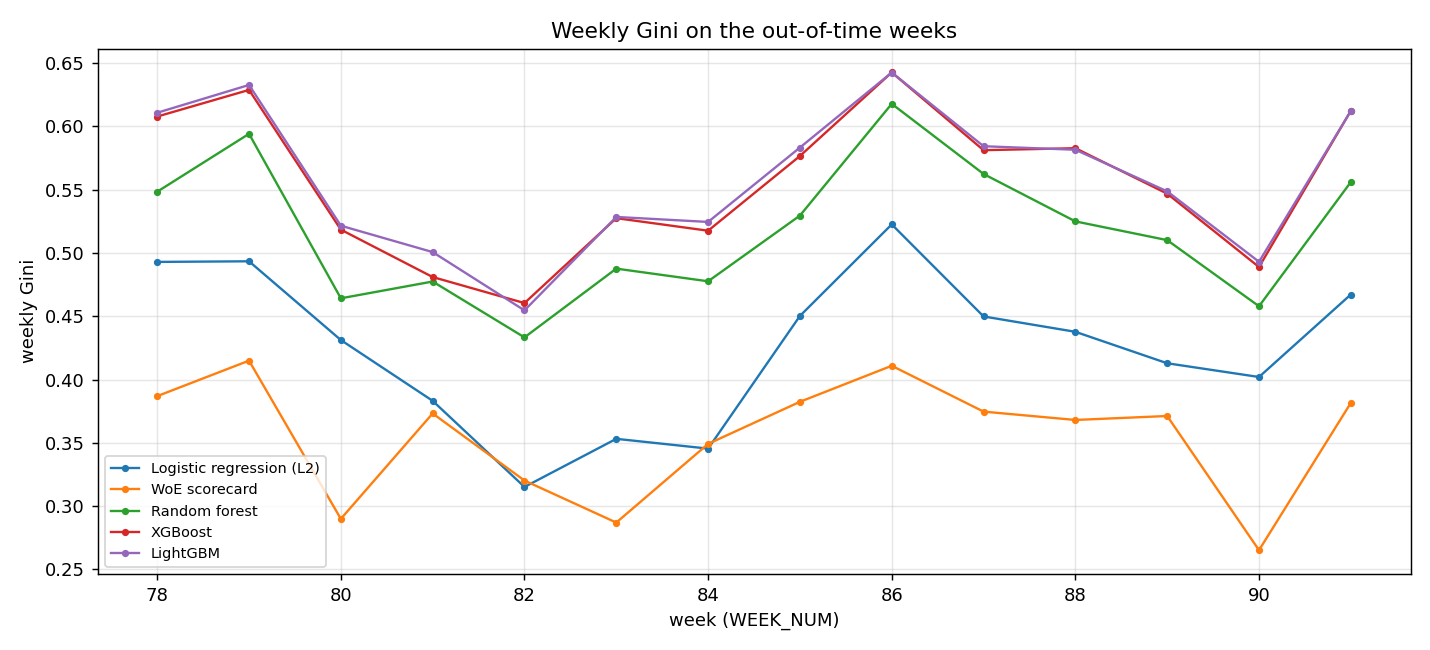

In [21]:
P_O = {
    "dummy": np.full(len(yoo), float(ytr.mean())),
    "woe_scorecard": scorecard_predict(sc, ds["X"][oo_m]),
    "penalised_lr": lr_model.predict_proba(Zoo)[:, 1],
    "random_forest": rf_model.predict_proba(Xoo)[:, 1],
    "xgboost": xgb_model.predict_proba(Xoo)[:, 1],
    "xgboost_monotone": xgbm_model.predict_proba(Xoo)[:, 1],
    "lightgbm": lgb_model.predict_proba(Xoo)[:, 1],
}
oot_eval = {n: eval_split(yoo, p, week_all[oo_m]) for n, p in P_O.items()}
LABEL = {"dummy": "Dummy (base rate)", "penalised_lr": "Logistic regression (L2)", "woe_scorecard": "WoE scorecard",
         "random_forest": "Random forest", "xgboost": "XGBoost", "xgboost_monotone": "XGBoost (monotone)", "lightgbm": "LightGBM"}
otab = pd.DataFrame({LABEL[n]: {k: v[k] for k in ("auc", "gini", "ks", "pr_auc", "brier")} for n, v in oot_eval.items()}).T
print(f"OOT weeks {int(week_all[oo_m].min())}-{int(week_all[oo_m].max())}, n={int(oo_m.sum())}, default rate {yoo.mean():.4f}")
print(otab.round(4).to_string())
print("\nweekly-Gini stability metric (OOT):")
print(pd.Series({LABEL[n]: v["stability"]["stability_metric"] for n, v in oot_eval.items()}).round(4).to_string())

rows = []
for n in P_V:
    r = {"model": n}
    for sp, ev in (("valid", valid_eval[n]), ("oot", oot_eval[n])):
        for k in ("auc", "gini", "pr_auc", "brier", "logloss", "ks"):
            r[f"{sp}_{k}"] = ev[k]
        r[f"{sp}_stability"] = ev["stability"]["stability_metric"]
        r[f"{sp}_mean_weekly_gini"] = ev["stability"]["mean_gini"]
    rows.append(r)
metrics_tbl = pd.DataFrame(rows).sort_values("oot_auc", ascending=False)
metrics_tbl.to_csv(ART / "metrics_table.csv", index=False)

def pack(ev, y, p):
    d = {k: ev[k] for k in ("auc", "gini", "ks", "pr_auc", "brier", "logloss", "stability")}
    d["calibration"] = calibration_summary(y, p)
    d["top5"] = topk_metrics(y, p, 0.05); d["top10"] = topk_metrics(y, p, 0.10)
    return d
write_json(ART / "metrics.json", {
    "models": {n: {"model": n, "valid": pack(valid_eval[n], yva, P_V[n]), "oot": pack(oot_eval[n], yoo, P_O[n]),
                   "weekly": {"valid": valid_eval[n]["weekly"], "oot": oot_eval[n]["weekly"]}} for n in P_V},
    "champion": champion, "champion_rule": frozen["rule"],
    "main_advanced_model": "xgboost",
    "model_meta": {"penalised_lr": {"C": lr_C, "penalty": "l2"}, "xgboost": xgb_best, "random_forest": {"train_rows": rf_rows}}})

fig, ax = plt.subplots(figsize=(11, 5))
for n in ("penalised_lr", "woe_scorecard", "random_forest", "xgboost", "lightgbm"):
    wk = pd.DataFrame(oot_eval[n]["weekly"])
    ax.plot(wk["week"], wk["gini"], marker="o", ms=3, lw=1.3, label=LABEL[n])
ax.set_xlabel("week (WEEK_NUM)"); ax.set_ylabel("weekly Gini"); ax.set_title("Weekly Gini on the out-of-time weeks")
ax.legend(fontsize=8); ax.grid(alpha=0.3); fig.tight_layout()
fig.savefig(ART / "figures" / "weekly_gini_oot.png", dpi=130); plt.show()
stab_rows = []
for n in P_V:
    for sp, ev in (("valid", valid_eval[n]), ("oot", oot_eval[n])):
        st = ev["stability"]
        stab_rows.append({"model": n, "split": sp, **{k: st[k] for k in ("mean_gini", "slope", "std_residual", "stability_metric")}})
pd.DataFrame(stab_rows).to_csv(ART / "stability.csv", index=False)
write_json(ART / "weekly_gini.json", {n: oot_eval[n]["weekly"] for n in P_V})

from sklearn.metrics import precision_recall_curve, roc_curve
curves = {"roc": {}, "pr": {}}
for n, p in P_O.items():
    if n == "dummy":
        continue
    fpr, tpr, _ = roc_curve(yoo, p); s = max(1, len(fpr) // 120)
    curves["roc"][n] = [{"fpr": float(a), "tpr": float(b)} for a, b in zip(fpr[::s], tpr[::s])]
    pr_, rc_, _ = precision_recall_curve(yoo, p); s = max(1, len(pr_) // 120)
    curves["pr"][n] = [{"recall": float(a), "precision": float(b)} for a, b in zip(rc_[::s], pr_[::s])]
write_json(ART / "curves.json", curves)
print("[end of code cell 21]")

## 11. Paired bootstrap of the Gini difference

Same resampled applications for both models in each draw.

In [22]:
t0 = time.time()
boot_preds = {n: P_O[n] for n in ("xgboost", "penalised_lr", "woe_scorecard", "random_forest", "lightgbm")}
boot = paired_bootstrap(yoo, boot_preds, ref="xgboost", n_boot=N_BOOT, seed=SEED)
print(f"paired bootstrap of OOT Gini difference, {N_BOOT} resamples ({time.time() - t0:.0f}s):")
bt = pd.DataFrame(boot).T
print(bt.round(4).to_string())
write_json(ART / "bootstrap_ci.json", {"metric": "OOT Gini difference (XGBoost minus other)", "n_boot": N_BOOT, "results": boot})
print("[end of code cell 22]")

paired bootstrap of OOT Gini difference, 1000 resamples (191s):
                             point_gini_diff  ci95_lo  ci95_hi  n_boot  share_positive
xgboost_minus_penalised_lr            0.1276   0.1142   0.1397  1000.0           1.000
xgboost_minus_woe_scorecard           0.2019   0.1892   0.2153  1000.0           1.000
xgboost_minus_random_forest           0.0382   0.0311   0.0452  1000.0           1.000
xgboost_minus_lightgbm               -0.0032  -0.0059  -0.0005  1000.0           0.012
[end of code cell 22]


## 12. Calibration (Platt vs isotonic)

Both fitted on VALID, compared on OOT before and after, with an expected-vs-actual table by decile.

champion = lightgbm; calibrator chosen on VALID = platt
OOT calibration, before and after (Platt vs isotonic fitted on VALID):
calibration  expected_over_actual  mean_pd  actual_rate     ece   brier  logloss  chosen_on_valid
 none (raw)               1.89661  0.04019      0.02119 0.01900 0.02052  0.09642            False
      platt               1.15392  0.02445      0.02119 0.00326 0.01996  0.09062             True
   isotonic               1.15693  0.02452      0.02119 0.00341 0.02001  0.09111            False

expected vs actual by decile (before / after):
 decile  n_before  expected_before  actual_before  expected_over_actual_before  expected_after  actual_after  expected_over_actual_after
      1     15171           0.0064         0.0024                       2.6304          0.0030        0.0024                      1.2113
      2     15171           0.0109         0.0042                       2.5740          0.0053        0.0042                      1.2528
      3     15170     

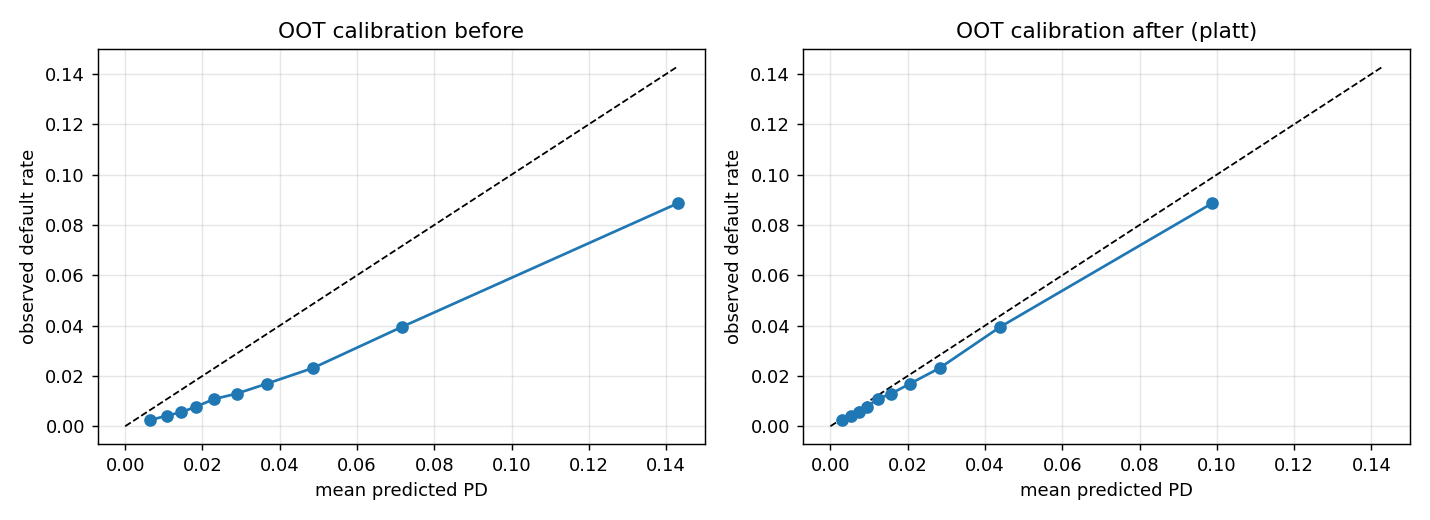

In [23]:
pv_raw, po_raw = P_V[champion], P_O[champion]
variants = {"none (raw)": po_raw}
for nm, cal in cal_sel["calibrators"].items():
    if cal is not None:
        variants[nm] = cal.predict(po_raw)
rows = []
for nm, p in variants.items():
    cs = calibration_summary(yoo, p)
    rows.append({"calibration": nm, "expected_over_actual": cs["expected_actual_ratio"], "mean_pd": cs["mean_predicted"],
                 "actual_rate": cs["observed_rate"], "ece": ece(yoo, p), "brier": brier(yoo, p), "logloss": logloss(yoo, p),
                 "chosen_on_valid": nm.startswith(cal_sel["choice"])})
cal_tbl = pd.DataFrame(rows)
print(f"champion = {champion}; calibrator chosen on VALID = {cal_sel['choice']}")
print("OOT calibration, before and after (Platt vs isotonic fitted on VALID):")
print(cal_tbl.round(5).to_string(index=False))

chosen_p = variants.get(cal_sel["choice"], po_raw)
dec_before = ea_deciles(yoo, po_raw); dec_after = ea_deciles(yoo, chosen_p)
dec = dec_before.merge(dec_after, on="decile", suffixes=("_before", "_after"))
print("\nexpected vs actual by decile (before / after):")
print(dec[["decile", "n_before", "expected_before", "actual_before", "expected_over_actual_before",
           "expected_after", "actual_after", "expected_over_actual_after"]].round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
mx = float(max(dec_before["actual"].max(), dec_before["expected"].max()))
for a, d, ttl in ((ax[0], dec_before, "before"), (ax[1], dec_after, f"after ({cal_sel['choice']})")):
    a.plot([0, mx], [0, mx], "k--", lw=1); a.plot(d["expected"], d["actual"], "o-")
    a.set_xlabel("mean predicted PD"); a.set_ylabel("observed default rate"); a.set_title(f"OOT calibration {ttl}"); a.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(ART / "figures" / "calibration.png", dpi=130); plt.show()
write_json(ART / "calibration.json", {"champion": champion, "chosen_on_valid": cal_sel["choice"], "oot": cal_tbl.to_dict(orient="records"),
           "deciles_before": dec_before.to_dict(orient="records"), "deciles_after": dec_after.to_dict(orient="records")})
print("[end of code cell 23]")

## 13. Why the default rate fell

Calendar view and an exact mix-vs-rate decomposition on TRAIN-score deciles.

default rate by calendar quarter of date_decision:
     q      n  default_rate       split
2019Q1 207740        0.0267       train
2019Q2 231004        0.0289       train
2019Q3 295013        0.0294       train
2019Q4 337005        0.0360       train
2020Q1 222681        0.0441 train/valid
2020Q2  82976        0.0234   oot/valid
2020Q3 141648        0.0211         oot
2020Q4   8592        0.0220         oot

TRAIN default rate 0.0332 | VALID 0.0243 | OOT 0.0212

TRAIN -> OOT, champion-score deciles fitted on TRAIN:
 band  w_train  w_other  rate_train  rate_other
    1      0.1   0.0141      0.0008      0.0014
    2      0.1   0.0609      0.0027      0.0019
    3      0.1   0.0858      0.0054      0.0038
    4      0.1   0.1177      0.0093      0.0054
    5      0.1   0.1161      0.0139      0.0074
    6      0.1   0.1297      0.0205      0.0105
    7      0.1   0.1177      0.0296      0.0141
    8      0.1   0.1085      0.0407      0.0199
    9      0.1   0.1102      0.0616      0.0301

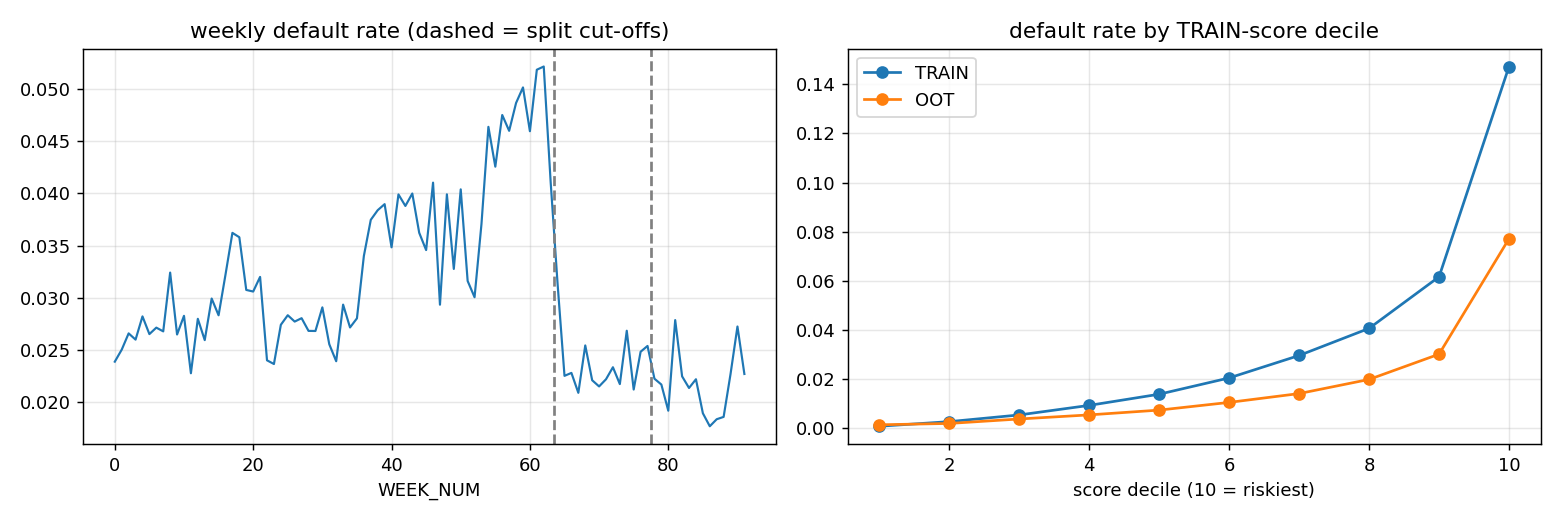

In [24]:
# why OOT default rate is lower than TRAIN: calendar view and mix-vs-rate decomposition
Xtr_champ = Xtr  # same tree design
champ_model = {"xgboost": xgb_model, "lightgbm": lgb_model, "random_forest": rf_model}.get(champion)
s_tr = champ_model.predict_proba(Xtr)[:, 1] if champ_model is not None else lr_model.predict_proba(Ztr)[:, 1]
dates = pd.to_datetime(pd.Series(ds["date"]))
cal_df = pd.DataFrame({"q": dates.dt.to_period("Q").astype(str), "split": ds["split"], "y": y_all})
q_tbl = cal_df.groupby("q").agg(n=("y", "size"), default_rate=("y", "mean"), split=("split", lambda s: "/".join(sorted(set(s))))).reset_index()
print("default rate by calendar quarter of date_decision:")
print(q_tbl.round(4).to_string(index=False))
print(f"\nTRAIN default rate {ytr.mean():.4f} | VALID {yva.mean():.4f} | OOT {yoo.mean():.4f}")

dec_oot = decile_decomposition(s_tr, ytr, po_raw, yoo)
dec_val = decile_decomposition(s_tr, ytr, pv_raw, yva)
print("\nTRAIN -> OOT, champion-score deciles fitted on TRAIN:")
print(dec_oot["table"].round(4).to_string(index=False))
print(f"total change in default rate {dec_oot['total_change']:+.4f} = score-mix effect {dec_oot['mix_effect']:+.4f} + within-band rate effect {dec_oot['rate_effect']:+.4f}")
print(f"TRAIN -> VALID: total {dec_val['total_change']:+.4f} = mix {dec_val['mix_effect']:+.4f} + rate {dec_val['rate_effect']:+.4f}")
print("Reading: a near-zero mix effect means applicants did not get safer on the model's own scale; the drop is inside the same risk bands.")
print("ASSUMPTION (context, not tested here): 2020 payment moratoria / COVID-period relief plausibly lowered observed defaults.")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
wk_rate = pd.DataFrame({"w": week_all, "y": y_all}).groupby("w")["y"].mean()
ax[0].plot(wk_rate.index, wk_rate.values, lw=1.2)
ax[0].axvline(bounds["train_weeks"][-1] + 0.5, c="gray", ls="--"); ax[0].axvline(bounds["valid_weeks"][-1] + 0.5, c="gray", ls="--")
ax[0].set_title("weekly default rate (dashed = split cut-offs)"); ax[0].set_xlabel("WEEK_NUM"); ax[0].grid(alpha=0.3)
t_ = dec_oot["table"]
ax[1].plot(t_["band"], t_["rate_train"], "o-", label="TRAIN"); ax[1].plot(t_["band"], t_["rate_other"], "o-", label="OOT")
ax[1].set_title("default rate by TRAIN-score decile"); ax[1].set_xlabel("score decile (10 = riskiest)"); ax[1].legend(); ax[1].grid(alpha=0.3)
fig.tight_layout(); fig.savefig(ART / "figures" / "default_rate_drop.png", dpi=130); plt.show()
write_json(ART / "default_rate_drop.json", {
    "train_default_rate": float(ytr.mean()), "valid_default_rate": float(yva.mean()), "oot_default_rate": float(yoo.mean()),
    "train_to_oot": {k: dec_oot[k] for k in ("total_change", "mix_effect", "rate_effect")},
    "train_to_valid": {k: dec_val[k] for k in ("total_change", "mix_effect", "rate_effect")},
    "oot_deciles": dec_oot["table"].to_dict(orient="records"), "by_quarter": q_tbl.to_dict(orient="records"),
    "assumption_note": "COVID-period relief as context is an assumption; the numbers above are measured."})
print("[end of code cell 24]")

## 14. Credit-policy layer

Capture at fixed review capacity, cut-offs chosen on VALID at stated bad-rate / approval-rate targets, swap sets, 10-grade master scale with a binomial test per grade, illustrative expected loss.

share of OOT defaulters caught when the riskiest 5/10/20% of applications are reviewed:
                   model  caught_at_5pct  caught_at_10pct  caught_at_20pct
Logistic regression (L2)          0.1810           0.3073           0.4815
           WoE scorecard          0.1353           0.2305           0.4075
           Random forest          0.2607           0.4031           0.5686
                 XGBoost          0.2762           0.4187           0.5984
                LightGBM          0.2774           0.4180           0.6044
      random (reference)          0.0500           0.1000           0.2000

cut-off strategies on the SAME OOT loans (observed defaults):
                 strategy                    model  approval_rate  bad_rate_approved  bad_rate_all  defaulters_declined_share
              approve all                        -         1.0000             0.0212        0.0212                     0.0000
 bad rate <= 1.5% (VALID) Logistic regression (L2)         0.7342       

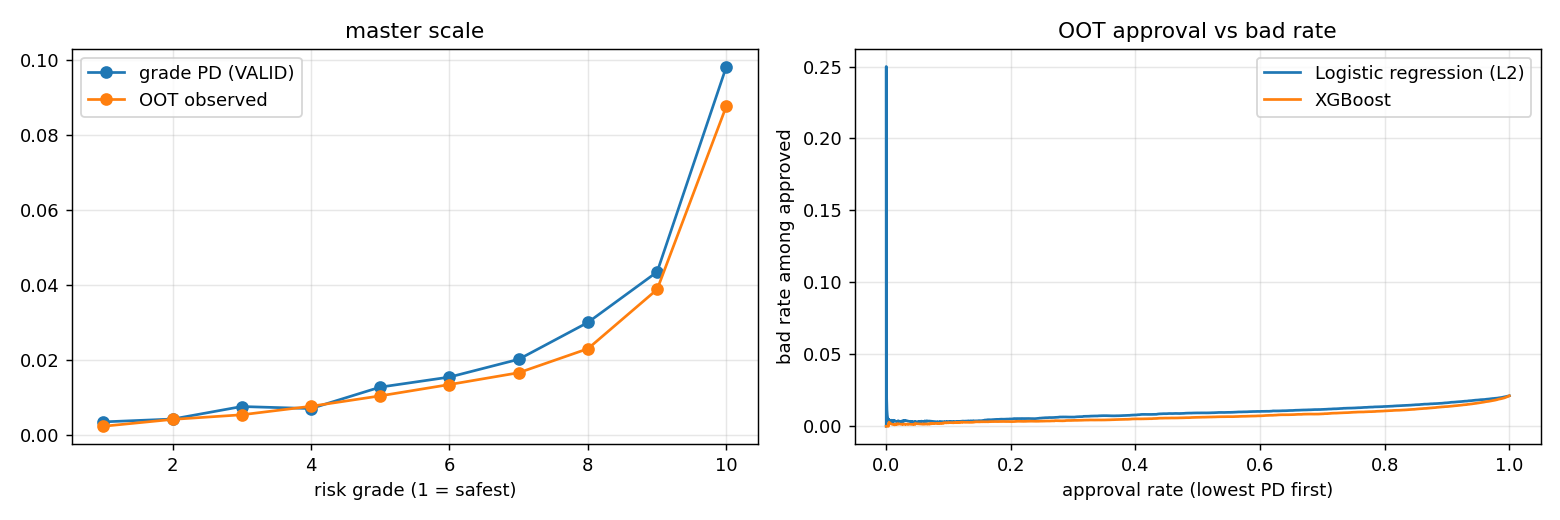

In [25]:
# (a) capture of defaulters at fixed review capacity
cap = capture_table(yoo, {LABEL[n]: P_O[n] for n in ("penalised_lr", "woe_scorecard", "random_forest", "xgboost", "lightgbm")})
print("share of OOT defaulters caught when the riskiest 5/10/20% of applications are reviewed:")
print(cap.round(4).to_string(index=False))

# (b) cut-off strategies: cut-offs frozen on VALID, outcomes observed on OOT
all_ = np.ones(len(yoo), dtype=bool)
rows = [{"strategy": "approve all", "model": "-", **policy_stats(yoo, all_)}]
strategies = {f"bad rate <= {t:.1%} (VALID)": f"bad_rate_{int(t * 1000)}" for t in TARGET_BAD}
strategies[f"approval rate {TARGET_APPROVAL:.0%} (VALID)"] = "approval_80"
for sname, key in strategies.items():
    for n in ("penalised_lr", "xgboost"):
        rows.append({"strategy": sname, "model": LABEL[n], **policy_stats(yoo, P_O[n] < cutoffs[n][key])})
strat = pd.DataFrame(rows)
print("\ncut-off strategies on the SAME OOT loans (observed defaults):")
print(strat[["strategy", "model", "approval_rate", "bad_rate_approved", "bad_rate_all", "defaulters_declined_share"]].round(4).to_string(index=False))

# (c) swap sets at the same approval rate: XGBoost vs logistic regression
swap = swap_sets(yoo, P_O["xgboost"], P_O["penalised_lr"], TARGET_APPROVAL)
print(f"\nswap sets at {TARGET_APPROVAL:.0%} approval on OOT (A = XGBoost, B = logistic regression, same number of loans approved by each):")
print(pd.DataFrame({k: v for k, v in swap.items() if isinstance(v, dict)}).T.round(4).to_string())
print(f"portfolio bad rate of approved loans: XGBoost {swap['portfolio_bad_rate_A']:.4f} | logistic regression {swap['portfolio_bad_rate_B']:.4f}")

# (d) risk grades / master scale (10 grades from VALID quantiles of the champion score)
dfx = ds["diagnostics"].to_pandas().set_index(ID_COL).reindex(ds["case_ids"])
ead_all = dfx["credit_amount"].astype(float)
ead_fill = float(np.nanmedian(ead_all[tr_m]))
ead_oot = ead_all[oo_m].fillna(ead_fill).to_numpy()
LGD = LGD_ASSUMED
ms = master_scale(pv_raw, yva, po_raw, yoo, n_grades=10, ead_oot=ead_oot, lgd=LGD)
mono = bool(np.all(np.diff(ms["oot_default_rate"].to_numpy()) >= 0))
print("\nmaster scale: 10 grades from VALID quantiles of the champion score; grade PD = VALID observed default rate")
print(ms.round(5).to_string(index=False))
print("OOT observed default rate monotone across grades:", mono)
print(f"grades where the binomial test rejects the grade PD at 5%: {int((ms['binomial_p'] < 0.05).sum())} of {len(ms)}")
tot_el, tot_real = ms["expected_loss"].sum(), ms["realised_loss"].sum()
print(f"ILLUSTRATIVE expected loss = PD x LGD x EAD (LGD {LGD} assumed, EAD = application credit amount, median-filled where missing): "
      f"expected {tot_el:,.0f} vs realised {tot_real:,.0f} (ratio {tot_el / tot_real:.3f})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ms["grade"], ms["grade_pd_valid"], "o-", label="grade PD (VALID)"); ax[0].plot(ms["grade"], ms["oot_default_rate"], "o-", label="OOT observed")
ax[0].set_xlabel("risk grade (1 = safest)"); ax[0].set_title("master scale"); ax[0].legend(); ax[0].grid(alpha=0.3)
for n in ("penalised_lr", "xgboost"):
    o = np.argsort(P_O[n], kind="stable"); cum = np.cumsum(yoo[o]) / np.arange(1, len(yoo) + 1)
    ax[1].plot(np.arange(1, len(yoo) + 1) / len(yoo), cum, label=LABEL[n])
ax[1].set_xlabel("approval rate (lowest PD first)"); ax[1].set_ylabel("bad rate among approved"); ax[1].set_title("OOT approval vs bad rate"); ax[1].legend(); ax[1].grid(alpha=0.3)
fig.tight_layout(); fig.savefig(ART / "figures" / "credit_policy.png", dpi=130); plt.show()

write_json(ART / "business.json", {
    "capture": cap.to_dict(orient="records"), "cutoff_strategies_oot": strat.to_dict(orient="records"),
    "swap_sets": swap, "master_scale": ms.to_dict(orient="records"), "master_scale_oot_monotone": mono,
    "expected_loss_illustrative": {"lgd_ASSUMED": LGD, "ead": "application credit amount (credamount_770A), median-filled when missing",
                                  "expected_loss_total": float(tot_el), "realised_loss_total": float(tot_real), "ratio": float(tot_el / tot_real)},
    "note": "all rates are observed OOT outcomes; LGD is an assumption; expected loss is illustrative"})
ms.to_csv(ART / "master_scale.csv", index=False)
strat.to_csv(ART / "cutoff_strategies.csv", index=False)
write_json(ART / "decision.json", {
    "targets": {"bad_rate_among_approved": list(TARGET_BAD), "approval_rate": TARGET_APPROVAL},
    "cutoffs_valid_raw_pd": cutoffs, "oot": strat.to_dict(orient="records"), "swap_sets": swap})
print("[end of code cell 25]")

## 15. Monitoring and interpretability

Score PSI, top-feature PSI/CSI, adversarial validation, top-15 XGBoost features in plain English.

score PSI TRAIN -> VALID 0.1915 | TRAIN -> OOT 0.2203 (watch)

top 15 XGBoost features by gain:
                                                                                                  plain_name  gain_share                                              feature
              Average DPD (days past due) with tolerance within the past 24 months from the... [application]      0.0373        train_static_0_0__avgdpdtolclosure24_3658938P
                                                   Reason for the client's last loan rejection [application]      0.0335    train_static_0_0__lastrejectreasonclient_4145040M
average Value of past due payment for active contract (num_group1 - existing contract... [credit bureau (b)]      0.0281    train_credit_bureau_b_2__pmts_dpdvalue_108P__mean
                   most recent category of Reason for previous application rejection [previous applications]      0.0198       train_applprev_1_1__rejectreason_755M__maxcode
              Average DPD (days pa

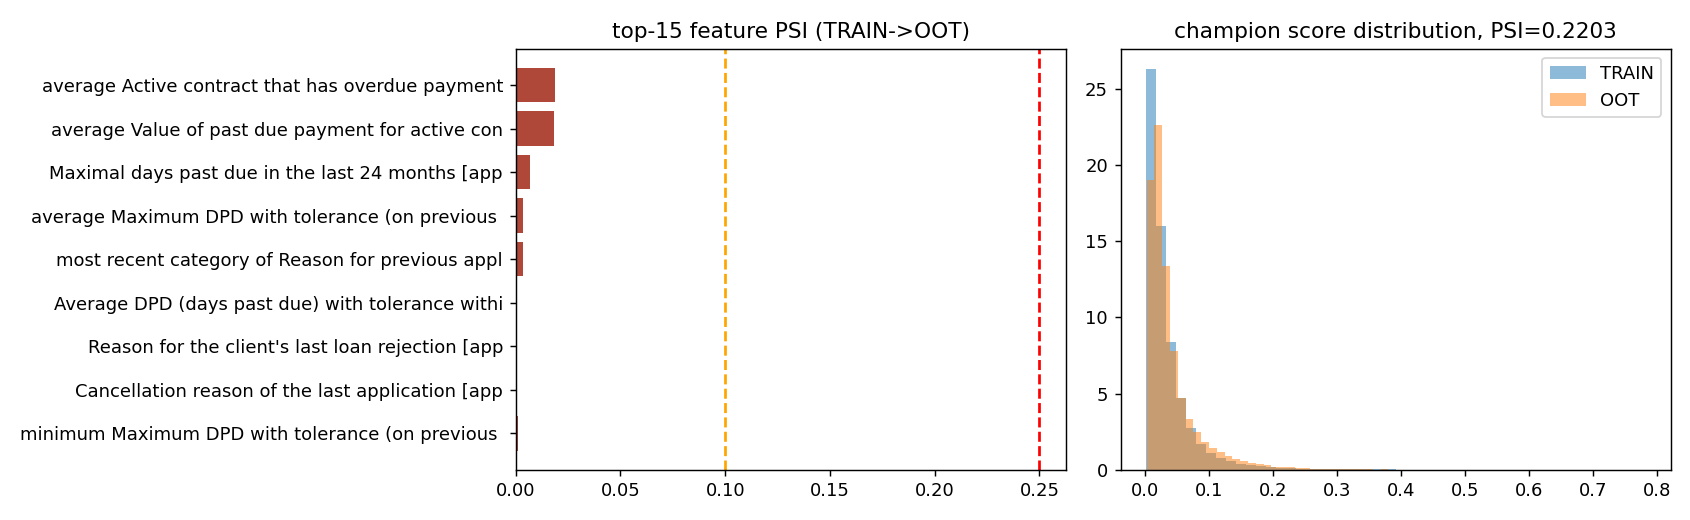

In [26]:
s_oo_raw = po_raw
score_psi = psi(s_tr, s_oo_raw)
score_psi_valid = psi(s_tr, pv_raw)
print(f"score PSI TRAIN -> VALID {score_psi_valid:.4f} | TRAIN -> OOT {score_psi:.4f} ({psi_band(score_psi)})")

gain = pd.Series(xgb_model.get_booster().get_score(importance_type="gain")).sort_values(ascending=False)
top = gain.head(15)
top_tbl = pd.DataFrame({"feature": top.index, "gain": top.values})
top_tbl["gain_share"] = top_tbl["gain"] / gain.sum()
top_tbl["plain_name"] = top_tbl["feature"].map(lambda f: plain_name(f, defs))
print("\ntop 15 XGBoost features by gain:")
print(top_tbl[["plain_name", "gain_share", "feature"]].round(4).to_string(index=False))
top_tbl.to_csv(ART / "top_features.csv", index=False)

csi_tab = psi_table(Xtr, Xoo, top_tbl["feature"].tolist())
csi_tab["plain_name"] = csi_tab["feature"].map(lambda f: plain_name(f, defs))
print("\nfeature stability (PSI/CSI, TRAIN -> OOT) for those top 15 features:")
print(csi_tab[["plain_name", "psi", "band"]].round(4).to_string(index=False))
psi_all = psi_table(Xtr, Xoo, tree_features)
psi_all.to_csv(ART / "psi.csv", index=False)
print("\nall tree features PSI bands:", psi_all["band"].value_counts().to_dict())

adv = adversarial_validation(Xtr, Xoo, tree_features)
print("adversarial AUC TRAIN vs OOT:", round(adv["auc"], 4), "-", adv["interpretation"])
write_json(ART / "drift.json", {"adversarial": adv, "psi": psi_all.to_dict(orient="records"), "psi_bands": psi_all["band"].value_counts().to_dict()})

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].barh(csi_tab["plain_name"].str.slice(0, 48)[::-1], csi_tab["psi"][::-1], color="#b0483a")
ax[0].axvline(PSI_WATCH, ls="--", c="orange"); ax[0].axvline(PSI_ALERT, ls="--", c="red"); ax[0].set_title("top-15 feature PSI (TRAIN->OOT)")
ax[1].hist(s_tr, bins=50, alpha=0.5, density=True, label="TRAIN"); ax[1].hist(po_raw, bins=50, alpha=0.5, density=True, label="OOT")
ax[1].set_title(f"champion score distribution, PSI={score_psi:.4f}"); ax[1].legend()
fig.tight_layout(); fig.savefig(ART / "figures" / "psi.png", dpi=130); plt.show()

mon = build_monitoring(pv_raw, po_raw, ds, tree_features[:60])
mon["score_drift"]["psi_train_to_oot"] = float(score_psi)
mon["score_drift"]["psi_band"] = psi_band(score_psi)
mon["score_psi_train_to_valid"] = float(score_psi_valid)
mon["top15_feature_psi"] = csi_tab.to_dict(orient="records")
write_json(ART / "monitoring.json", mon)
write_json(ART / "evaluation.json", {
    "calibration": dec_after.rename(columns={"expected": "mean_pd", "actual": "observed"}).to_dict(orient="records"),
    "bootstrap": boot, "shap": {"top_features": top_tbl[["feature", "plain_name", "gain_share"]].to_dict(orient="records")},
    "note": "'shap' key kept for the app; values are XGBoost gain shares"})
print("[end of code cell 26]")

## 16. Quality gates, models, manifest

Gate table, saved models for the app, hashed manifest.

In [27]:
gates = []
gates += [{"gate": f"leakage:{c['check']}", "status": c["status"], "detail": c["detail"]} for c in gate["checks"]]
dummy_auc = oot_eval["dummy"]["auc"]
beats = {n: oot_eval[n]["auc"] > dummy_auc for n in P_O if n != "dummy"}
gates.append({"gate": "dummy_baseline_beaten", "status": "PASS" if all(beats.values()) else "FAIL", "detail": beats})
a_ch = oot_eval[champion]["auc"]
gates.append({"gate": "plausible_oot_range", "status": "PASS" if 0.74 <= a_ch <= 0.86 else "WARN",
              "detail": {"champion_oot_auc": a_ch, "range": [0.74, 0.86]}})
gates.append({"gate": "valid_oot_gap_under_0.05", "status": "PASS" if abs(valid_eval[champion]["auc"] - a_ch) < 0.05 else "WARN",
              "detail": {"valid_auc": valid_eval[champion]["auc"], "oot_auc": a_ch}})
gates.append({"gate": "scorecard_all_signs_consistent", "status": "PASS" if bool(signs["consistent"].all()) else "FAIL",
              "detail": {"consistent": int(signs["consistent"].sum()), "total": int(len(signs)), "before_fix": sign_first}})
ea_after = float(cal_tbl.loc[cal_tbl["chosen_on_valid"], "expected_over_actual"].iloc[0])
gates.append({"gate": "calibration_expected_actual_after", "status": "PASS" if 0.8 <= ea_after <= 1.25 else "WARN",
              "detail": {"after": ea_after, "before": float(cal_tbl.iloc[0]["expected_over_actual"])}})
gates.append({"gate": "score_psi_train_to_oot", "status": "PASS" if score_psi < PSI_ALERT else "WARN", "detail": {"psi": float(score_psi)}})
b = boot["xgboost_minus_penalised_lr"]
gates.append({"gate": "xgb_minus_lr_ci_excludes_zero", "status": "PASS" if b["ci95_lo"] > 0 else "WARN", "detail": b})
gates.append({"gate": "champion_frozen_before_oot", "status": "PASS", "detail": {"file": "artifacts/champion.json"}})
gt = pd.DataFrame([{"gate": g["gate"], "status": g["status"]} for g in gates])
print(gt.to_string(index=False))
write_json(ART / "quality_gates.json", {"gates": gates, "n_pass": int((gt["status"] == "PASS").sum()),
                                        "n_fail": int((gt["status"] == "FAIL").sum()), "n_warn": int((gt["status"] == "WARN").sum())})

# ---- models + scored sample for the Streamlit app ------------------------------
xgb_model.save_model(str(ART / "models" / "champion_xgb.txt"))
joblib.dump({"process": sc["process"], "coef_table": sc["coef_table"], "features": sc["features"],
             "process_vars": sc["process_vars"], "base_points": sc["base_points"]}, ART / "models" / "scorecard.joblib", compress=3)
joblib.dump({"pipeline": lin_pipe, "model": lr_model}, ART / "models" / "penalised_lr.joblib", compress=3)
champ_kind = {"xgboost": "xgb", "lightgbm": "lgbm", "random_forest": "rf", "penalised_lr": "linear", "woe_scorecard": "scorecard"}[champion]
if champion == "lightgbm":
    lgb_model.save_model(str(ART / "models" / "champion_lgbm.txt")) if hasattr(lgb_model, "save_model") else lgb_model.booster_.save_model(str(ART / "models" / "champion_lgbm.txt"))
model_file = {"xgboost": "models/champion_xgb.txt", "lightgbm": "models/champion_lgbm.txt"}.get(champion, "models/champion_xgb.txt")

oot_pos = np.where(oo_m)[0]
rng = np.random.default_rng(SEED)
pick = np.sort(rng.choice(len(oot_pos), min(3000, len(oot_pos)), replace=False))
sample_df = ds["X"].iloc[oot_pos[pick]][tree_features].copy()
sample_df.insert(0, "case_id", ds["case_ids"][oot_pos[pick]]); sample_df.insert(1, "week", week_all[oot_pos[pick]]); sample_df.insert(2, "target", yoo[pick])
for n in (champion, "woe_scorecard"):
    sample_df[f"pd_{n}"] = P_O[n][pick]
sample_df.to_parquet(ART / "scored_oot_sample.parquet", index=False)

write_json(ART / "feature_meta.json", {
    "champion": champion, "kind": champ_kind, "features": tree_features, "cat_features": [f for f in tree_features if f in ds["cat_cols"]],
    "model_file": model_file, "scorecard_file": "models/scorecard.joblib", "linear_file": "models/penalised_lr.joblib",
    "typical_values": {f: {"p05": float(np.nanpercentile(ds["X"][f].to_numpy(), 5)), "p50": float(np.nanpercentile(ds["X"][f].to_numpy(), 50)),
                           "p95": float(np.nanpercentile(ds["X"][f].to_numpy(), 95)), "missing": float(np.mean(~np.isfinite(ds["X"][f].to_numpy())))}
                       for f in tree_features},
    "scorecard_features": sc["features"], "pdo": PDO, "base_score": BASE_SCORE, "base_odds": BASE_ODDS})

import sklearn
env = {"python": sys.version.split()[0], "platform": platform.platform(), "sklearn": sklearn.__version__, "pandas": pd.__version__,
       "numpy": np.__version__, "polars": pl.__version__, "lightgbm": __import__("lightgbm").__version__,
       "xgboost": __import__("xgboost").__version__, "statsmodels": __import__("statsmodels").__version__,
       "optbinning": __import__("optbinning").__version__, "kernel": os.environ.get("KAGGLE_KERNEL_RUN_TYPE", "local"),
       "sample_cases": SAMPLE_CASES, "runtime_seconds": round(time.time() - T_START, 1)}
write_json(ART / "environment.json", env)
print(json.dumps(env, indent=2))

import hashlib
manifest = [{"file": str(p.relative_to(ART)).replace("\\", "/"), "bytes": p.stat().st_size,
             "sha256": hashlib.sha256(p.read_bytes()).hexdigest()} for p in sorted(ART.rglob("*")) if p.is_file() and p.name != "MANIFEST.json"]
write_json(ART / "MANIFEST.json", {"created_at": time.strftime("%Y-%m-%dT%H:%M:%S"), "files": manifest})
print(f"manifest: {len(manifest)} files | total runtime {time.time() - T_START:.0f}s")
print("DONE")
print("[end of code cell 27]")

                               gate status
   leakage:no_id_or_outcome_columns   PASS
       leakage:target_not_in_design   PASS
        leakage:time_split_ordering   PASS
            leakage:no_case_overlap   PASS
      leakage:univariate_auc_screen   PASS
leakage:scaler_fitted_on_train_rows   PASS
   leakage:woe_binned_on_train_rows   PASS
leakage:woe_fit_sample_within_train   PASS
              dummy_baseline_beaten   PASS
                plausible_oot_range   PASS
           valid_oot_gap_under_0.05   PASS
     scorecard_all_signs_consistent   PASS
  calibration_expected_actual_after   PASS
             score_psi_train_to_oot   PASS
      xgb_minus_lr_ci_excludes_zero   PASS
         champion_frozen_before_oot   PASS
{
  "python": "3.13.18",
  "platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
  "sklearn": "1.6.1",
  "pandas": "2.3.3",
  "numpy": "2.1.3",
  "polars": "1.35.2",
  "lightgbm": "4.6.0",
  "xgboost": "3.4.1",
  "statsmodels": "0.15.0",
  "optbinning": "1.0.0",
  "kerne